# N3 Deep Sleep Detection & Quality Assessment

এই notebook-টা দিয়ে আমরা দুটো কাজ করবো:
1. Raw EEG signal দেখে সেটা **N3 (deep sleep) কিনা** সেটা detect করবো
2. যদি N3 হয়, তাহলে সেই sleep-এর **quality score (0–100)** বের করবো

---

## Research Questions

| # | প্রশ্ন | Code-এ কোথায় |
|---|---|---|
| RQ1 | Deep learning কি N3 detect করতে পারে এবং একই সাথে quality score দিতে পারে? | `n3_head` + `quality_head` |
| RQ2 | Delta band feature explicitly দিলে কি quality assessment ভালো হয়? | 4টা detection + 2টা quality feature |
| RQ3 | N3-specific loss weighting কি imbalanced dataset-এ recall বাড়ায়? | `BCEWithLogitsLoss(pos_weight)` |

---

## Features যা use করা হয়েছে

**Detection features (4টা) — N3 কিনা সেটা detect করার জন্য:**
- Delta power (0.5–4 Hz energy)
- Slow wave activity (delta band RMS amplitude)
- Slow wave density (AASM clinical standard — waves per minute)
- Relative delta power (delta / total power ratio)

**Quality features (2টা) — N3-এর quality measure করার জন্য:**
- Peak-to-peak amplitude (slow wave-এর height)
- Fragmentation index (signal-এর irregularity)

---

## Dataset
- **ISRUC Sleep Study Sub-Group I** — 100 জন patient
- File format: `.rec` (EDF-compatible), 200 Hz, C4-A1 channel
- Labels: W=Wake, N1, N2, N3=deep sleep, REM → এই notebook-এ binary: **N3=1, বাকি সব=0**


## Step 1 — Setup

**কী করছি:** Python library গুলো import করছি এবং dataset-এর path ও configuration set করছি।

**কেন দরকার:** সব cell-এ একই `CONFIG` ব্যবহার করা হবে — তাই একবার এখানে define করলে পরে শুধু এই cell-এর value বদলালেই সব জায়গায় reflect হবে।

**Important settings:**
- `n_subjects = 100` — কতজন patient-এর data load করবো (ISRUC-Sleep-I full sub-group)
- `n3_loss_weight = auto` — N3 epoch miss করলে dynamic weight দিয়ে বেশি penalty (training data থেকে computed)
- `epochs = 40` — training কতবার করবো (V4+: no early stopping, full 40-epoch run)

In [1]:
import os
import random
import numpy as np
import torch

# NOTE: raw string (r"...") used so backslashes in the Windows path are
# never accidentally interpreted as escape sequences (e.g. \A, \I).
DATA_DIR = r"D:\AI_Project\ISRUC-Sleep-I"

CONFIG = {
    "data_dir":       DATA_DIR,
    "n_subjects":     100,
    "eeg_channel":    "C4-A1",
    "fallback_ch":    "F4-A1",
    "sampling_rate":  200,
    "epoch_sec":      30,
    "epochs":         40,
    "batch_size":     48,            # V5: 32 -> 48 (more N3 samples per batch -> lower gradient variance on quality head)
    # If you hit CUDA OOM on a 4 GB GPU, revert to 32. The 100 K-param model
    # + 6000-sample epochs fits in 48 batch on RTX 3050 with ~3.5 GB used.
    "seed":           42,
    "n3_loss_weight": "auto",        # overridden dynamically in Step 9 from real data

    # ── v3 NEW: training / regularization hyperparameters ───────────────
    "lr":                     3e-4,   # ↓ from 5e-4 — smoother convergence, less overfit
    "weight_decay":           5e-3,   # ↑ from 1e-3 — stronger L2 (effective N≈80 subjects)
    "dropout_fusion":         0.4,    # unchanged
    "dropout_fc":             0.3,    # unchanged
    "scheduler":              "cosine",  # cosine annealing (was ReduceLROnPlateau)
    "cosine_T_max":           40,     # one cosine cycle across all epochs
    "cosine_eta_min":         1e-6,
    "grad_clip":              1.0,    # unchanged
    # NOTE (v4): Early stopping has been REMOVED. Training always runs all 40 epochs.
    # Best checkpoint is still saved on every val-loss improvement (for the plot marker).
    "mixup_alpha":            0.0,    # 0 = disabled (set 0.2 to enable)
}

STAGE_MAP = {0: 'Wake', 1: 'N1', 2: 'N2', 3: 'N3', 4: 'REM'}

# ── v3 NEW: global seed for reproducibility ───────────────────────────────
def set_seed(seed=42):
    """Seed Python, NumPy, and PyTorch (CPU + CUDA) for reproducible runs."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(CONFIG["seed"])

print("CONFIG ready (v6 — architecture-optimized + outlier-reduction + full 40-epoch training, no early stopping).")
print(f"  data_dir      : {CONFIG['data_dir']}")
print(f"  n_subjects    : {CONFIG['n_subjects']}")
print(f"  eeg_channel   : {CONFIG['eeg_channel']}")
print(f"  sampling_rate : {CONFIG['sampling_rate']} Hz")
print(f"  lr            : {CONFIG['lr']}  (v2 was 5e-4)")
print(f"  weight_decay  : {CONFIG['weight_decay']}  (v2 was 1e-3)")
print(f"  scheduler     : {CONFIG['scheduler']}  (v2 was ReduceLROnPlateau)")
print(f"  seed          : {CONFIG['seed']}  (global reproducibility)")

if not os.path.isdir(CONFIG["data_dir"]):
    print(f"\n  WARNING: data_dir does not exist on this machine: {DATA_DIR}")
    print("  Update DATA_DIR above to the correct path before running Step 3 (data loading).")


CONFIG ready (v6 — architecture-optimized + outlier-reduction + full 40-epoch training, no early stopping).
  data_dir      : D:\AI_Project\ISRUC-Sleep-I
  n_subjects    : 100
  eeg_channel   : C4-A1
  sampling_rate : 200 Hz
  lr            : 0.0003  (v2 was 5e-4)
  weight_decay  : 0.005  (v2 was 1e-3)
  scheduler     : cosine  (v2 was ReduceLROnPlateau)
  seed          : 42  (global reproducibility)


In [2]:
# ╔══════════════════════════════════════════════════════════════════╗
# ║  DEVICE SETUP — Auto-detect GPU / CPU                          ║
# ╚══════════════════════════════════════════════════════════════════╝
import torch

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

print(f"{'='*50}")
print(f"  Device selected : {DEVICE}")
if DEVICE.type == 'cuda':
    print(f"  GPU name        : {torch.cuda.get_device_name(0)}")
    print(f"  GPU memory      : {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")
    print(f"  CUDA version    : {torch.version.cuda}")
else:
    print("  No GPU detected — running on CPU")
    print("  Tip: Enable a GPU runtime for faster training")
print(f"{'='*50}")


  Device selected : cuda
  GPU name        : NVIDIA GeForce RTX 3050 Laptop GPU
  GPU memory      : 4.3 GB
  CUDA version    : 12.8


### Reproducibility & Environment

**FIX (reproducibility):** Print all version info, CUDA status, data source, and
training wall-clock time.


In [3]:
# ═══════════════════════════════════════════════════════════════════╗
# ║  FIX (reproducibility): Environment & versions                  ║
# ═══════════════════════════════════════════════════════════════════╗
import sys

print('═'*60)
print('  REPRODUCIBILITY INFORMATION')
print('═'*60)
print(f'  Python version  : {sys.version.split()[0]}')
try:
    print(f'  PyTorch version : {torch.__version__}')
except Exception:
    print('  PyTorch version : NOT INSTALLED')
try:
    print(f'  NumPy version   : {np.__version__}')
except Exception:
    print('  NumPy version   : NOT INSTALLED')
try:
    import scipy
    print(f'  SciPy version   : {scipy.__version__}')
except Exception:
    print('  SciPy version   : NOT INSTALLED')
try:
    import sklearn
    print(f'  scikit-learn    : {sklearn.__version__}')
except Exception:
    print('  scikit-learn    : NOT INSTALLED')
try:
    import mne
    print(f'  MNE version     : {mne.__version__}')
except Exception:
    print('  MNE version     : NOT INSTALLED (optional)')
print(f'  Device          : {DEVICE}')
if DEVICE.type == 'cuda':
    print(f'  GPU name        : {torch.cuda.get_device_name(0)}')
    print(f'  CUDA version    : {torch.version.cuda}')
print(f'  Global seed     : {CONFIG["seed"]}')

import os
_data_real = os.path.isdir(CONFIG.get('data_dir', ''))
print(f'\n  DATA SOURCE:')
if _data_real:
    print(f'    Real ISRUC-Sleep-I data from: {CONFIG["data_dir"]}')
else:
    print(f'    Synthetic data (create_synthetic_dataset fallback)')
    print(f'    (data_dir does not exist on this machine)')
print('═'*60)


════════════════════════════════════════════════════════════
  REPRODUCIBILITY INFORMATION
════════════════════════════════════════════════════════════
  Python version  : 3.12.10
  PyTorch version : 2.11.0+cu128
  NumPy version   : 2.4.4
  SciPy version   : 1.17.1
  scikit-learn    : 1.9.0
  MNE version     : 1.12.1
  Device          : cuda
  GPU name        : NVIDIA GeForce RTX 3050 Laptop GPU
  CUDA version    : 12.8
  Global seed     : 42

  DATA SOURCE:
    Real ISRUC-Sleep-I data from: D:\AI_Project\ISRUC-Sleep-I
════════════════════════════════════════════════════════════


In [4]:
%%writefile sleep_quality_model.py
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
from scipy.signal import butter, sosfilt, sosfiltfilt, find_peaks
from sklearn.metrics import (accuracy_score, f1_score, precision_score,
                              recall_score, roc_auc_score,
                              mean_squared_error, r2_score)

try:
    import mne
    _HAS_MNE = True
except Exception:
    _HAS_MNE = False


# ============================================================================
# 1. PREPROCESSING
# ============================================================================

class EEGPreprocessor:
    """EEG preprocessing + 6-feature extraction for N3 detection and quality."""

    def __init__(self, sampling_rate=200, epoch_duration=30):
        self.sampling_rate  = sampling_rate
        self.epoch_duration = epoch_duration
        self.epoch_samples  = sampling_rate * epoch_duration

    def bandpass_filter(self, signal_data, low_freq=0.5, high_freq=40):
        sos = butter(4, [low_freq, high_freq], btype='band',
                     fs=self.sampling_rate, output='sos')
        return sosfiltfilt(sos, signal_data)

    def extract_frequency_bands(self, eeg_epoch):
        bands = {'delta':(0.5,4),'theta':(4,8),'alpha':(8,12),
                 'sigma':(12,16),'beta':(16,30)}
        out = {}
        for name,(lo,hi) in bands.items():
            sos = butter(4,[lo,hi],btype='band',fs=self.sampling_rate,output='sos')
            out[name] = float(np.mean(sosfiltfilt(sos, eeg_epoch)**2))
        return out

    def extract_delta_power(self, eeg_epoch):
        """Feature 1: Delta band power (0.5-4 Hz)."""
        sos = butter(4, [0.5, 4], btype='band', fs=self.sampling_rate, output='sos')
        filtered = sosfiltfilt(sos, eeg_epoch)
        return float(np.mean(filtered ** 2))

    def extract_slow_wave_activity(self, eeg_epoch):
        """Feature 2: Slow Wave Activity - RMS amplitude of delta band."""
        sos = butter(4, [0.5, 4], btype='band', fs=self.sampling_rate, output='sos')
        filtered = sosfiltfilt(sos, eeg_epoch)
        return float(np.sqrt(np.mean(filtered ** 2)))

    def extract_slow_wave_density(self, eeg_epoch, amp_threshold_uv=75.0):
        """Feature 3: Slow Wave Density - AASM clinical standard."""
        sos = butter(4, [0.5, 2], btype='band', fs=self.sampling_rate, output='sos')
        filtered = sosfiltfilt(sos, eeg_epoch)
        peaks_pos, _ = find_peaks(filtered,
                                   height=amp_threshold_uv / 2,
                                   distance=int(self.sampling_rate * 0.25))
        peaks_neg, _ = find_peaks(-filtered,
                                   height=amp_threshold_uv / 2,
                                   distance=int(self.sampling_rate * 0.25))
        n_waves = (len(peaks_pos) + len(peaks_neg)) / 2.0
        epoch_minutes = self.epoch_duration / 60.0
        return float(n_waves / max(epoch_minutes, 1e-6))

    def extract_relative_delta_power(self, eeg_epoch):
        """Feature 4: Relative delta power = delta / total power."""
        bands = self.extract_frequency_bands(eeg_epoch)
        total = sum(bands.values()) + 1e-8
        return float(bands['delta'] / total)

    def extract_peak_to_peak_amplitude(self, eeg_epoch):
        """Quality Feature 1: Peak-to-peak amplitude of slow waves."""
        sos = butter(4, [0.5, 4], btype='band', fs=self.sampling_rate, output='sos')
        filtered = sosfiltfilt(sos, eeg_epoch)
        return float(np.max(filtered) - np.min(filtered))

    def extract_fragmentation_index(self, eeg_epoch):
        """Quality Feature 2: Fragmentation index = zero crossing rate."""
        zero_crossings = np.sum(np.diff(np.sign(eeg_epoch)) != 0)
        return float(zero_crossings / len(eeg_epoch))

    def extract_all_features(self, eeg_epoch):
        """Extract all 6 features. Returns (det_feat, qual_feat)."""
        det = np.array([
            self.extract_delta_power(eeg_epoch),
            self.extract_slow_wave_activity(eeg_epoch),
            self.extract_slow_wave_density(eeg_epoch),
            self.extract_relative_delta_power(eeg_epoch),
        ], dtype=np.float32)
        qual = np.array([
            self.extract_peak_to_peak_amplitude(eeg_epoch),
            self.extract_fragmentation_index(eeg_epoch),
        ], dtype=np.float32)
        return det, qual

    def notch_filter(self, signal_data, freq=50, Q=30):
        """Remove powerline noise (50 or 60 Hz)."""
        from scipy.signal import iirnotch, tf2sos, sosfiltfilt
        b, a = iirnotch(freq, Q, fs=self.sampling_rate)
        sos = tf2sos(b, a)
        return sosfiltfilt(sos, signal_data)

    def detect_artifacts(self, eeg_epoch, threshold_std=5.0, threshold_amp_uv=300):
        """Detect EMG, movement, and electrode artifacts."""
        from scipy.signal import butter, sosfiltfilt
        peak_amplitude = np.max(np.abs(eeg_epoch))
        if peak_amplitude > threshold_amp_uv:
            return True, 0.9
        z_scores = np.abs((eeg_epoch - np.mean(eeg_epoch)) / (np.std(eeg_epoch) + 1e-8))
        if np.max(z_scores) > threshold_std:
            return True, 0.8
        sos_hf = butter(4, [30, 40], btype='band', fs=self.sampling_rate, output='sos')
        hf_signal = sosfiltfilt(sos_hf, eeg_epoch)
        hf_power = np.mean(hf_signal ** 2)
        sos_delta = butter(4, [0.5, 4], btype='band', fs=self.sampling_rate, output='sos')
        delta_signal = sosfiltfilt(sos_delta, eeg_epoch)
        delta_power = np.mean(delta_signal ** 2)
        if hf_power > 0.5 * delta_power:
            return True, 0.7
        return False, 0.0

    def clip_outliers(self, eeg_epoch, n_std=4.0):
        """Clip values beyond n standard deviations."""
        mean = np.mean(eeg_epoch)
        std = np.std(eeg_epoch)
        lower_bound = mean - n_std * std
        upper_bound = mean + n_std * std
        clipped = np.clip(eeg_epoch, lower_bound, upper_bound)
        n_clipped = np.sum((eeg_epoch < lower_bound) | (eeg_epoch > upper_bound))
        return clipped, n_clipped

    def compute_signal_quality(self, eeg_epoch):
        """Compute signal quality score (0-1)."""
        from scipy.signal import butter, sosfiltfilt
        rms = np.sqrt(np.mean(eeg_epoch ** 2))
        flatness_score = 1.0 if rms < 1.0 else 0.0
        sos_lf = butter(4, [0.5, 15], btype='band', fs=self.sampling_rate, output='sos')
        sos_hf = butter(4, [30, 40], btype='band', fs=self.sampling_rate, output='sos')
        lf_signal = sosfiltfilt(sos_lf, eeg_epoch)
        hf_signal = sosfiltfilt(sos_hf, eeg_epoch)
        lf_power = np.mean(lf_signal ** 2)
        hf_power = np.mean(hf_signal ** 2)
        noise_ratio = hf_power / (lf_power + 1e-8)
        sos_delta = butter(4, [0.5, 4], btype='band', fs=self.sampling_rate, output='sos')
        sos_hf2 = butter(4, [30, 45], btype='band', fs=self.sampling_rate, output='sos')
        delta = sosfiltfilt(sos_delta, eeg_epoch)
        hf_noise = sosfiltfilt(sos_hf2, eeg_epoch)
        delta_power = np.mean(delta ** 2)
        noise_power = np.mean(hf_noise ** 2)
        snr = 10 * np.log10(delta_power / (noise_power + 1e-8))
        quality_score = 1.0
        if noise_ratio > 0.3:
            quality_score -= 0.3
        if snr < 3:
            quality_score -= 0.3
        if flatness_score > 0.5:
            quality_score -= 0.4
        quality_score = np.clip(quality_score, 0, 1)
        return {'flatness': flatness_score, 'noise_ratio': noise_ratio, 'snr_db': snr,
                'quality_score': quality_score, 'is_good': quality_score > 0.6}

    def normalize_epoch(self, eeg_epoch):
        """Robust normalization using median & IQR."""
        q75, q25 = np.percentile(eeg_epoch, [75, 25])
        iqr = q75 - q25
        if iqr == 0:
            iqr = 1.0
        median = np.median(eeg_epoch)
        return (eeg_epoch - median) / iqr

    def create_epochs(self, raw_signal, labels=None, remove_artifacts=True,
                      remove_low_quality=True, notch_freq=50):
        """Create epochs with ROBUST preprocessing pipeline."""
        epochs, det_feats, qual_feats, epoch_labels = [], [], [], []
        n_removed = {'artifact': 0, 'quality': 0, 'clipped_too_much': 0}
        n = len(raw_signal) // self.epoch_samples
        for i in range(n):
            start = i * self.epoch_samples
            ep = raw_signal[start:start+self.epoch_samples]
            ep = self.notch_filter(ep, freq=notch_freq)
            ep = self.bandpass_filter(ep)
            ep, n_clipped = self.clip_outliers(ep, n_std=4.0)
            if n_clipped > 100:
                n_removed['clipped_too_much'] += 1
                continue
            if remove_artifacts:
                is_artifact, score = self.detect_artifacts(ep)
                if is_artifact:
                    n_removed['artifact'] += 1
                    continue
            quality = self.compute_signal_quality(ep)
            if remove_low_quality and not quality['is_good']:
                n_removed['quality'] += 1
                continue
            det, qual = self.extract_all_features(ep)
            ep = self.normalize_epoch(ep)
            epochs.append(ep)
            det_feats.append(det)
            qual_feats.append(qual)
            if labels is not None and i < len(labels):
                epoch_labels.append(labels[i])
        print("\n" + "="*70)
        print("PREPROCESSING QUALITY REPORT")
        print("="*70)
        print(f"Total epochs attempted:        {n:,}")
        print(f"Artifact epochs removed:       {n_removed['artifact']:,}")
        print(f"Low-quality epochs removed:    {n_removed['quality']:,}")
        print(f"Heavily clipped epochs removed: {n_removed['clipped_too_much']:,}")
        print("-"*70)
        print(f"Final epochs retained:         {len(epochs):,}")
        if n > 0:
            print(f"Retention rate:                {100*len(epochs)/n:.1f}%")
        print("="*70 + "\n")
        return (np.array(epochs), np.array(det_feats),
                np.array(qual_feats), np.array(epoch_labels))


# ============================================================================
# 2. DATA AUGMENTATION (v3 — fixed bugs that were destroying N3 signal)
# ============================================================================

class EEGAugmentor:
    """Realistic EEG augmentations that PRESERVE slow-wave (N3) features.
    Applied ONLY during training (not validation/testing).

    v3 changes vs v2:
      • Removed harmful "frequency mask" — it was actually a TIME mask that
        zeroed 0.5 s of the signal, destroying slow waves (the primary N3
        marker at 0.5-4 Hz, period 0.5-2 s). Removing it raised N3 recall
        in our internal test from ~0.87 to ~0.90.
      • Replaced torch.roll (which WRAPS the signal, creating an artificial
        discontinuity at the edge that the CNN can learn as a spurious
        feature) with reflection padding — the shifted signal now fades
        smoothly at the edge instead of wrapping.
      • Reduced noise std ceiling 0.05 -> 0.03 to keep delta-band SNR
        high enough for the model to see slow waves clearly.
    """

    def __init__(self, sampling_rate=200):
        self.sr = sampling_rate

    def __call__(self, raw_eeg):
        """raw_eeg: (B, 1, L) tensor - returns augmented tensor of same shape."""
        aug = raw_eeg.clone()

        # 1. Gaussian noise injection (simulates sensor noise)
        #    v3: lower std ceiling (0.03) keeps delta-band SNR >= ~15 dB.
        if torch.rand(1).item() < 0.5:
            noise_std = torch.rand(1).item() * 0.03
            aug = aug + torch.randn_like(aug) * noise_std * aug.std()

        # 2. Random time shift (+/-0.5 s) with REFLECTION padding
        #    v3: torch.roll wraps the signal, creating a discontinuity at
        #        the edge that the CNN can mis-learn as a slow wave. We use
        #        F.pad(mode='reflect') so the shifted signal stays continuous.
        if torch.rand(1).item() < 0.3:
            shift = int(torch.randint(-100, 100, (1,)).item())
            L = aug.shape[-1]
            if shift > 0:
                # shift right: drop last `shift` samples, pad `shift` zeros on right
                # via reflection of the dropped tail
                aug = F.pad(aug[..., :-shift], (0, shift), mode='reflect')
            elif shift < 0:
                # shift left: drop first `|shift|` samples, pad on left
                aug = F.pad(aug[..., -shift:], (-shift, 0), mode='reflect')

        # 3. Amplitude scaling (simulates electrode impedance variation)
        if torch.rand(1).item() < 0.3:
            scale = 0.85 + 0.3 * torch.rand(1).item()
            aug = aug * scale

        # 4. REMOVED in v3 — see class docstring (was a harmful time mask).
        return aug

# ============================================================================
# 3. MODEL - Dual-path feature fusion (REDUCED SIZE for small dataset)
#
#   Changes vs original:
#   - CNN: 32->16, 64->32, 128->64 channels
#   - LSTM: single-direction, 1 layer, hidden=64
#   - Dropout: 0.3->0.4 (fusion), 0.2->0.3 (fc)
# ============================================================================

class SleepQualityNet(nn.Module):
    """Dual-path multi-feature N3 detector + quality regressor.

    V6 architecture changes (vs V5):
      * conv3 channels reduced 64 -> 48 (saves ~16K params)
      * LSTM layer REMOVED (saves ~33K params) — the attention layer already
        collapses time, so the LSTM was a redundant non-linear projection
      * Attention input dim 64 -> 48 (forced by conv3 change)
      * det_fusion / qual_fusion input dims updated accordingly

    Total params: 100,244 (V5) -> ~50,712 (V6), a ~49% reduction.

    All other V5 behavior preserved:
      * Constrained quality head with learnable temperature (output in [0.02, 0.98])
      * Dual-path structure (detection + quality)
      * All V5 preprocessing, loss, optimizer, scheduler, training pipeline unchanged
    """

    N_DET_FEAT  = 4
    N_QUAL_FEAT = 2

    def __init__(self, input_length=6000, use_det_feat=True, use_qual_feat=True):
        super().__init__()
        self.use_det_feat  = use_det_feat
        self.use_qual_feat = use_qual_feat

        # CNN backbone (shared) - REDUCED channels
        self.conv1 = nn.Sequential(
            nn.Conv1d(1, 16, kernel_size=64, stride=2, padding=32),
            nn.BatchNorm1d(16), nn.ReLU(), nn.MaxPool1d(4))
        self.conv2 = nn.Sequential(
            nn.Conv1d(16, 32, kernel_size=32, stride=2, padding=16),
            nn.BatchNorm1d(32), nn.ReLU(), nn.MaxPool1d(4))
        # V6: conv3 channels reduced 64 -> 48 (saves ~16K params).
        # AdaptiveAvgPool1d(32) immediately compresses the time dimension, so
        # 48 channels is sufficient representational capacity.
        self.conv3 = nn.Sequential(
            nn.Conv1d(32, 48, kernel_size=16, stride=1, padding=8),
            nn.BatchNorm1d(48), nn.ReLU(), nn.AdaptiveAvgPool1d(32))

        # V6: LSTM REMOVED.
        # The CNN+AdaptiveAvgPool already produces a (B, 48, 32) tensor that
        # the attention layer collapses to (B, 48). The LSTM was a redundant
        # non-linear projection that added ~33K params (33% of total) without
        # adding temporal information the attention layer didn't already
        # capture. Removing it speeds up training and reduces overfitting risk.

        # Attention (shared) - V6: input dim 64 -> 48 to match new conv3 output
        self.attention = nn.Sequential(
            nn.Linear(48, 32), nn.Tanh(), nn.Linear(32, 1), nn.Softmax(dim=1))

        # Detection path fusion: V6 attended(48) + det_feat(4) = 52
        self.det_fusion = nn.Sequential(
            nn.Linear(48 + self.N_DET_FEAT, 64),
            nn.BatchNorm1d(64), nn.ReLU(), nn.Dropout(0.4))
        self.det_fc = nn.Sequential(
            nn.Linear(64, 32), nn.BatchNorm1d(32), nn.ReLU(), nn.Dropout(0.3))

        # Quality path fusion: V6 attended(48) + qual_feat(2) = 50
        self.qual_fusion = nn.Sequential(
            nn.Linear(48 + self.N_QUAL_FEAT, 64),
            nn.BatchNorm1d(64), nn.ReLU(), nn.Dropout(0.4))
        self.qual_fc = nn.Sequential(
            nn.Linear(64, 32), nn.BatchNorm1d(32), nn.ReLU(), nn.Dropout(0.3))

        # Head 1: binary N3 detector
        self.n3_head = nn.Sequential(
            nn.Linear(32, 16), nn.ReLU(), nn.Linear(16, 1))

        # Head 2: N3 quality regressor (V5: constrained to avoid Sigmoid saturation)
        # Output range is [0.02, 0.98] via a scaled Sigmoid:
        #   q = 0.02 + 0.96 * sigmoid(logit)
        # This prevents gradient-vanishing at the edges (Source 2) and gives
        # the optimizer a non-zero gradient everywhere.
        self.quality_head_inner = nn.Sequential(
            nn.Linear(32, 16), nn.ReLU(), nn.Linear(16, 1))
        # Learnable temperature (initialized to 1.0) for the scaled Sigmoid
        self.quality_temp = nn.Parameter(torch.tensor(1.0))

    def _encode(self, raw_eeg):
        """V6 shared backbone: CNN -> attention -> attended (B, 48).

        The LSTM has been removed (see __init__ docstring). The CNN output
        (B, 48, 32) is fed directly to the attention layer, which collapses
        the time dimension to produce a (B, 48) attended vector.
        """
        x = self.conv1(raw_eeg)
        x = self.conv2(x)
        x = self.conv3(x)              # (B, 48, 32)
        cnn_feat = x.permute(0, 2, 1)  # (B, 32, 48) — treat 32 timesteps as sequence
        attn_w   = self.attention(cnn_feat)        # (B, 32, 1)
        attended = (cnn_feat * attn_w).sum(dim=1)  # (B, 48)
        return attended

    def forward(self, raw_eeg, det_feat, qual_feat):
        attended = self._encode(raw_eeg)
        d = det_feat if self.use_det_feat else torch.zeros_like(det_feat)
        det_fused = self.det_fusion(torch.cat([attended, d], dim=1))
        det_out   = self.det_fc(det_fused)
        q = qual_feat if self.use_qual_feat else torch.zeros_like(qual_feat)
        qual_fused = self.qual_fusion(torch.cat([attended, q], dim=1))
        qual_out   = self.qual_fc(qual_fused)
        # V5: scaled Sigmoid in [0.02, 0.98] — prevents saturation (Source 2)
        # Use softplus(quality_temp) so temperature stays positive.
        temp = F.softplus(self.quality_temp) + 0.5
        q_logit = self.quality_head_inner(qual_out) / temp
        q_pred  = 0.02 + 0.96 * torch.sigmoid(q_logit)
        return self.n3_head(det_out), q_pred


# ============================================================================
# 3b. LOG-TRANSFORM + WINSORIZATION (V5 NEW — outlier reduction)
# ============================================================================

LOG_TRANSFORM_DET_INDICES  = [0, 1]   # delta_power, SWA  (log-normal distributed)
LOG_TRANSFORM_QUAL_INDICES = [0]      # p2p_amplitude     (log-normal distributed)


def log_transform_features(det_features, qual_features):
    """Apply log1p to heavy-tailed features (delta_power, SWA, p2p_amplitude).

    These features are sums-of-squares of band-filtered EEG and follow an
    approximate log-normal distribution. log1p makes them near-Gaussian so:
      * Percentile clipping becomes less aggressive (no long right tail).
      * Linear layers downstream see symmetric, well-scaled inputs.
      * Gradient magnitudes are comparable across features.

    Note: log1p(x) = log(1 + x) handles x=0 gracefully (returns 0).
    """
    det_features  = np.asarray(det_features,  dtype=np.float32).copy()
    qual_features = np.asarray(qual_features, dtype=np.float32).copy()
    for i in LOG_TRANSFORM_DET_INDICES:
        det_features[:, i] = np.log1p(np.clip(det_features[:, i], 0, None))
    for i in LOG_TRANSFORM_QUAL_INDICES:
        qual_features[:, i] = np.log1p(np.clip(qual_features[:, i], 0, None))
    return det_features, qual_features


class Winsorizer:
    """Winsorize features at median +/- k*IQR (robust to single-sample artifacts).

    Unlike percentile clipping, this is robust to the long right tail of
    p2p_amplitude caused by transient artifacts that survive amplitude-based
    artifact rejection. Cap is computed on TRAIN split only (no leakage).
    """

    def __init__(self, k=5.0):
        self.k = k
        self.det_lo = self.det_hi = None
        self.qual_lo = self.qual_hi = None

    def fit(self, det_features, qual_features):
        det_features  = np.asarray(det_features,  dtype=np.float32)
        qual_features = np.asarray(qual_features, dtype=np.float32)
        # Detection features
        det_median = np.median(det_features, axis=0)
        det_q75, det_q25 = np.percentile(det_features, [75, 25], axis=0)
        det_iqr = det_q75 - det_q25 + 1e-8
        self.det_lo = det_median - self.k * det_iqr
        self.det_hi = det_median + self.k * det_iqr
        # Quality features
        qual_median = np.median(qual_features, axis=0)
        qual_q75, qual_q25 = np.percentile(qual_features, [75, 25], axis=0)
        qual_iqr = qual_q75 - qual_q25 + 1e-8
        self.qual_lo = qual_median - self.k * qual_iqr
        self.qual_hi = qual_median + self.k * qual_iqr
        return self

    def transform(self, det_features, qual_features):
        if self.det_lo is None:
            raise RuntimeError("Winsorizer.fit() must be called before transform()")
        det_features  = np.asarray(det_features,  dtype=np.float32)
        qual_features = np.asarray(qual_features, dtype=np.float32)
        det_clipped  = np.clip(det_features,  self.det_lo,  self.det_hi)
        qual_clipped = np.clip(qual_features, self.qual_lo, self.qual_hi)
        return det_clipped, qual_clipped


def clip_features_outliers(det_features, qual_features, lower_pct=2, upper_pct=98):
    """Clip feature outliers using percentile-based bounds (TRAIN split only).

    V5: default bounds tightened from 1-99 to 2-98 (Fix 3). Combined with the
    log-transform in `log_transform_features` (Fix 2), the distribution is now
    near-Gaussian, so 2-98 removes the heaviest tail without losing information.
    """
    det_features  = np.asarray(det_features,  dtype=np.float32)
    qual_features = np.asarray(qual_features, dtype=np.float32)
    det_lo  = np.percentile(det_features,  lower_pct, axis=0)
    det_hi  = np.percentile(det_features,  upper_pct, axis=0)
    qual_lo = np.percentile(qual_features, lower_pct, axis=0)
    qual_hi = np.percentile(qual_features, upper_pct, axis=0)
    det_clipped  = np.clip(det_features,  det_lo,  det_hi)
    qual_clipped = np.clip(qual_features, qual_lo, qual_hi)
    clip_bounds = {'det_lo': det_lo, 'det_hi': det_hi,
                   'qual_lo': qual_lo, 'qual_hi': qual_hi}
    return det_clipped, qual_clipped, clip_bounds


def apply_clip_bounds(det_features, qual_features, clip_bounds):
    """Apply pre-computed clip bounds to a different split (no data leakage)."""
    det_features  = np.asarray(det_features,  dtype=np.float32)
    qual_features = np.asarray(qual_features, dtype=np.float32)
    det_clipped  = np.clip(det_features,  clip_bounds['det_lo'],  clip_bounds['det_hi'])
    qual_clipped = np.clip(qual_features, clip_bounds['qual_lo'], clip_bounds['qual_hi'])
    return det_clipped, qual_clipped


# ============================================================================
# 4. MULTI-TASK LOSS (L_phys REMOVED - was noisy on small batches)
# ============================================================================

class MultiTaskLoss(nn.Module):
    """V5 multi-task loss with three improvements:

      1. Quality loss is computed on ALL epochs (not just N3), with a smaller
         weight for non-N3 (Source 3). This gives the quality head a learning
         signal for every input, so it can't produce wild predictions on
         non-N3 epochs at inference.
      2. MSE instead of Smooth-L1 for the quality term. With targets in [0, 1],
         Smooth-L1 behaves as pure L2 for small errors but doesn't penalize
         mid-range errors (0.3-0.7) strongly enough. MSE gives a smoother
         gradient across the full range.
      3. Optional variance penalty: λ_var * Var(quality_pred) within the batch.
         Discourages the head from producing wildly different values for
         similar inputs (Source 7).
    """

    def __init__(self, lambda_cls=1.0, lambda_qual=0.5, n3_pos_weight=2.0,
                 non_n3_qual_weight=0.3, lambda_var=0.05):
        super().__init__()
        self.lambda_cls  = lambda_cls
        self.lambda_qual = lambda_qual
        self.non_n3_qual_weight = non_n3_qual_weight
        self.lambda_var  = lambda_var
        self.register_buffer('pos_weight',
                             torch.tensor([n3_pos_weight], dtype=torch.float32))

    def forward(self, n3_logit, quality_pred, n3_labels, quality_labels, det_feat):
        bce   = nn.BCEWithLogitsLoss(pos_weight=self.pos_weight.to(n3_logit.device))
        L_cls = bce(n3_logit, n3_labels.float().unsqueeze(1))

        # V5: quality loss on ALL epochs, weighted by N3 vs non-N3
        n3_mask     = (n3_labels == 1)
        non_n3_mask = (~n3_mask)
        target      = quality_labels.unsqueeze(1)
        per_sample_sq_err = (quality_pred - target) ** 2

        L_qual_n3     = per_sample_sq_err[n3_mask].mean() if n3_mask.any()     else torch.tensor(0.0, device=n3_logit.device)
        L_qual_non_n3 = per_sample_sq_err[non_n3_mask].mean() if non_n3_mask.any() else torch.tensor(0.0, device=n3_logit.device)
        L_qual = L_qual_n3 + self.non_n3_qual_weight * L_qual_non_n3

        # V5: variance penalty — discourages extreme swings within a batch
        if self.lambda_var > 0 and quality_pred.numel() > 1:
            L_var = quality_pred.var()
        else:
            L_var = torch.tensor(0.0, device=n3_logit.device)

        L_total = self.lambda_cls * L_cls + self.lambda_qual * L_qual + self.lambda_var * L_var
        return L_total, L_cls, L_qual, L_var


# ============================================================================
# 5. TRAINER (v4 — configurable lr/wd/scheduler, clean train loss, NO early stopping)
# ============================================================================

class SleepQualityTrainer:
    """v4 trainer - always runs all `epochs` epochs (no early stopping).

    Improvements vs v2 (preserved in v4):
      * Configurable lr, weight_decay, scheduler ('cosine' or 'plateau').
      * Tracking of train_losses_clean (loss on a forward pass WITHOUT
        augmentation) so the user can see the TRUE overfitting gap.
      * plot_training_curves() method - the graph the user requested.
      * best_epoch tracking - marked on the plot; best checkpoint saved on
        every val-loss improvement.

    Removed in v4 (vs v3):
      * The early-stop class + early_stopping / early_stopping_patience kwargs
      * The `break` statement in train() that exited the epoch loop early
      * Now: train() ALWAYS runs all 40 (or whatever) epochs the caller requests.
    """

    def __init__(self, model, device=None, checkpoint_path='best_model.pth',
                 n3_pos_weight=2.0, augmentor=None,
                 lr=3e-4, weight_decay=5e-3,
                 scheduler='cosine', cosine_T_max=40, cosine_eta_min=1e-6,
                 grad_clip=1.0):
        if device is not None:
            self.device = torch.device(device)
        elif torch.cuda.is_available():
            self.device = torch.device('cuda')
        elif hasattr(torch.backends, 'mps') and torch.backends.mps.is_available():
            self.device = torch.device('mps')
        else:
            self.device = torch.device('cpu')
        self.model     = model.to(self.device)
        self.ckpt      = checkpoint_path
        self.criterion = MultiTaskLoss(n3_pos_weight=n3_pos_weight)
        self.optimizer = torch.optim.AdamW(
            model.parameters(), lr=lr, weight_decay=weight_decay)
        self.grad_clip = grad_clip

        # Scheduler
        if scheduler == 'cosine':
            self.scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
                self.optimizer, T_max=cosine_T_max, eta_min=cosine_eta_min)
            self._sched_is_plateau = False
        else:  # 'plateau' — v2 behaviour
            self.scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
                self.optimizer, mode='min', factor=0.5, patience=8, min_lr=1e-6)
            self._sched_is_plateau = True

        # History
        self.train_losses       = []  # augmented (what the optimizer sees)
        self.train_losses_clean = []  # clean forward pass - true train loss
        self.val_losses         = []
        self.train_accs         = []
        self.val_accs           = []
        self.augmentor          = augmentor
        self.best_epoch         = -1

    @staticmethod
    def _to_binary(stage_labels):
        return (stage_labels == 3).long()

    def train_epoch(self, train_loader, verbose=True):
        self.model.train()
        total_loss       = 0.0
        total_loss_clean = 0.0  # NEW v3 - clean forward pass (no aug)
        all_preds_clean, all_labels = [], []
        for i, (raw_eeg, det_feat, qual_feat, stage_labels, quality_labels) in enumerate(train_loader):
            raw_eeg        = raw_eeg.to(self.device)
            det_feat       = det_feat.to(self.device)
            qual_feat      = qual_feat.to(self.device)
            n3_labels      = self._to_binary(stage_labels).to(self.device)
            quality_labels = quality_labels.to(self.device)

            # Apply augmentation (training only) - used for the gradient step
            if self.augmentor is not None:
                raw_eeg_aug = self.augmentor(raw_eeg)
            else:
                raw_eeg_aug = raw_eeg

            # Gradient step on AUGMENTED data
            n3_logit, quality_pred = self.model(raw_eeg_aug, det_feat, qual_feat)
            loss, l_cls, l_qual, l_phys = self.criterion(
                n3_logit, quality_pred, n3_labels, quality_labels, det_feat)
            self.optimizer.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(self.model.parameters(), self.grad_clip)
            self.optimizer.step()
            total_loss += loss.item()

            # Clean forward pass (no aug) - for honest overfitting diagnosis
            with torch.no_grad():
                n3_logit_c, quality_pred_c = self.model(raw_eeg, det_feat, qual_feat)
                loss_c, *_ = self.criterion(
                    n3_logit_c, quality_pred_c, n3_labels, quality_labels, det_feat)
                total_loss_clean += loss_c.item()
                preds_c = (torch.sigmoid(n3_logit_c).squeeze(1) > 0.5).long().cpu().numpy()
                all_preds_clean.extend(preds_c)
            all_labels.extend(n3_labels.cpu().numpy())

            if verbose and (i+1) % 10 == 0:
                print(f"    batch {i+1:>3}: loss={loss.item():.4f} "
                      f"[cls={l_cls.item():.4f} qual={l_qual.item():.4f}]")
        n_batches = max(len(train_loader), 1)
        avg       = total_loss / n_batches
        avg_clean = total_loss_clean / n_batches
        self.train_losses.append(avg)
        self.train_losses_clean.append(avg_clean)
        self.train_accs.append(accuracy_score(all_labels, all_preds_clean)
                                if all_labels else 0.0)
        return avg, avg_clean

    def evaluate(self, val_loader):
        self.model.eval()
        total_loss = 0.0
        n3_preds, n3_true, n3_probs = [], [], []
        q_preds, q_true = [], []
        with torch.no_grad():
            for raw_eeg, det_feat, qual_feat, stage_labels, quality_labels in val_loader:
                raw_eeg        = raw_eeg.to(self.device)
                det_feat       = det_feat.to(self.device)
                qual_feat      = qual_feat.to(self.device)
                n3_labels      = self._to_binary(stage_labels).to(self.device)
                quality_labels = quality_labels.to(self.device)
                n3_logit, quality_pred = self.model(raw_eeg, det_feat, qual_feat)
                loss, *_ = self.criterion(
                    n3_logit, quality_pred, n3_labels, quality_labels, det_feat)
                total_loss += loss.item()
                prob = torch.sigmoid(n3_logit).squeeze(1).cpu().numpy()
                pred = (prob > 0.5).astype(int)
                n3_probs.extend(prob)
                n3_preds.extend(pred)
                n3_true.extend(n3_labels.cpu().numpy())
                mask = (n3_labels.cpu().numpy() == 1)
                if mask.any():
                    q_preds.extend(quality_pred.cpu().numpy().flatten()[mask])
                    q_true.extend(quality_labels.cpu().numpy().flatten()[mask])
        avg = total_loss / max(len(val_loader), 1)
        self.val_losses.append(avg)
        yt       = np.array(n3_true)
        yp       = np.array(n3_preds)
        prob_arr = np.array(n3_probs)
        acc = float((yt == yp).mean())
        self.val_accs.append(acc)
        metrics = {
            'loss': avg, 'accuracy': acc,
            'n3_recall': recall_score(yt, yp, zero_division=0),
            'n3_precision': precision_score(yt, yp, zero_division=0),
            'n3_f1': f1_score(yt, yp, zero_division=0),
            'auc': roc_auc_score(yt, prob_arr) if len(np.unique(yt))>1 else 0.0,
        }
        if q_preds:
            qt = np.array(q_true); qp = np.array(q_preds)
            metrics['quality_rmse'] = float(np.sqrt(mean_squared_error(qt, qp)))
            metrics['quality_r2']   = float(r2_score(qt, qp))
        else:
            metrics['quality_rmse'] = 0.0
            metrics['quality_r2']   = 0.0
        return metrics

    def train(self, train_loader, val_loader, epochs=40, verbose=True):
        """v4 - ALWAYS runs all `epochs` epochs (no early stopping).

        Best checkpoint is still saved on every val-loss improvement, so the
        plot_training_curves() vertical line marker (best_epoch) works.
        At the end of training, the best checkpoint is loaded back so the
        returned model is the best one (not necessarily the last one).
        """
        best_val = float('inf')
        for epoch in range(epochs):
            if verbose:
                print(f"\nEpoch {epoch+1}/{epochs}")
            tr_loss, tr_loss_clean = self.train_epoch(train_loader, verbose=verbose)
            m = self.evaluate(val_loader)
            lr_now = self.optimizer.param_groups[0]['lr']
            print(f"  train={tr_loss:.4f}  train(clean)={tr_loss_clean:.4f}  "
                  f"val={m['loss']:.4f}  "
                  f"N3-F1={m['n3_f1']:.3f}  AUC={m['auc']:.3f}  "
                  f"Q-R2={m['quality_r2']:.3f}  lr={lr_now:.1e}")

            # Step scheduler
            if self._sched_is_plateau:
                self.scheduler.step(m['loss'])
            else:
                self.scheduler.step()

            # Save best checkpoint on every val-loss improvement (NO early stop)
            if m['loss'] < best_val:
                best_val = m['loss']
                self.best_epoch = epoch
                torch.save(self.model.state_dict(), self.ckpt)
                if verbose:
                    print(f"  -> new best val loss = {best_val:.4f} (epoch {epoch+1})")

        # Restore best checkpoint at end of training
        import os
        if os.path.exists(self.ckpt):
            self.model.load_state_dict(
                torch.load(self.ckpt, map_location=self.device))
        return self.model

    # ────────────────────────────────────────────────────────────────────
    # v3 NEW: plot training curves (the graph the user requested)
    # ────────────────────────────────────────────────────────────────────
    def plot_training_curves(self, figsize=(16, 5)):
        """Plot train vs val loss + train vs val accuracy.

        Three lines on the loss plot:
          * train (augmented) - what the optimizer saw
          * train (clean)     - true training loss without augmentation
          * val               - validation loss
        The clean vs augmented gap shows how much augmentation is hardening
        the training task; the clean vs val gap shows the TRUE overfitting.
        """
        import matplotlib.pyplot as plt
        if not self.train_losses:
            print("No training history to plot.")
            return
        epochs = np.arange(1, len(self.train_losses)+1)
        fig, axes = plt.subplots(1, 2, figsize=figsize, constrained_layout=True)

        # --- Loss ---
        axes[0].plot(epochs, self.train_losses,        'o-',  color='#1f77b4',
                     label='Train (augmented)',  lw=1.8, ms=5)
        if self.train_losses_clean:
            axes[0].plot(epochs, self.train_losses_clean, 's--', color='#17becf',
                         label='Train (clean)',  lw=1.4, ms=4)
        axes[0].plot(epochs, self.val_losses,          '^-',  color='#d62728',
                     label='Validation',         lw=1.8, ms=5)
        if self.best_epoch >= 0:
            axes[0].axvline(self.best_epoch+1, color='green', ls=':',
                            lw=1.5, alpha=0.7,
                            label=f'Best epoch={self.best_epoch+1}')
        axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Loss')
        axes[0].set_title('Training vs Validation Loss', fontweight='bold')
        axes[0].legend(loc='best', fontsize=9); axes[0].grid(alpha=0.3)

        # --- Accuracy ---
        axes[1].plot(epochs, self.train_accs, 'o-', color='#1f77b4',
                     label='Train',  lw=1.8, ms=5)
        axes[1].plot(epochs, self.val_accs,   '^-', color='#d62728',
                     label='Validation', lw=1.8, ms=5)
        if self.best_epoch >= 0:
            axes[1].axvline(self.best_epoch+1, color='green', ls=':',
                            lw=1.5, alpha=0.7,
                            label=f'Best epoch={self.best_epoch+1}')
        axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Binary N3 Accuracy')
        axes[1].set_title('Training vs Validation Accuracy', fontweight='bold')
        axes[1].legend(loc='best', fontsize=9); axes[1].grid(alpha=0.3)
        plt.show()

        # Print final gap summary
        print()
        if self.train_losses_clean and self.val_losses:
            gap = self.val_losses[-1] - self.train_losses_clean[-1]
            print(f"  Final-epoch loss  | train(clean)={self.train_losses_clean[-1]:.4f}  "
                  f"val={self.val_losses[-1]:.4f}  ->  gap = {gap:+.4f}")
        if self.train_accs and self.val_accs:
            gap = self.val_accs[-1] - self.train_accs[-1]
            print(f"  Final-epoch acc   | train={self.train_accs[-1]:.4f}  "
                  f"val={self.val_accs[-1]:.4f}  ->  gap = {gap:+.4f}")
        if self.best_epoch >= 0:
            print(f"  Best epoch: {self.best_epoch+1}  "
                  f"(val loss = {min(self.val_losses):.4f}, "
                  f"val acc = {self.val_accs[self.best_epoch]:.4f})")
        print("\n  Reading guide:")
        print("   * train(aug) > train(clean)  -> augmentation is hardening training (good)")
        print("   * train(clean) ~ val          -> well-regularized (target)")
        print("   * train(clean) << val         -> overfitting (watch the gap in late epochs)")
        print("   * train(clean) >> val         -> underfitting (raise lr / add capacity)")

# ============================================================================
# 6. DATA LOADER
# ============================================================================

class SleepDataLoader:

    STAGE_MAP = {'W':0,'N1':1,'N2':2,'N3':3,'R':4,'REM':4}

    @staticmethod
    def numpy_to_tensor_dataset(raw_eegs, det_features, qual_features,
                                 stage_labels, quality_labels):
        """Wrap arrays into TensorDataset."""
        return torch.utils.data.TensorDataset(
            torch.FloatTensor(raw_eegs).unsqueeze(1),
            torch.FloatTensor(det_features),
            torch.FloatTensor(qual_features),
            torch.LongTensor(stage_labels),
            torch.FloatTensor(quality_labels))

    @staticmethod
    def create_synthetic_dataset(num_samples=600, sampling_rate=200,
                                  epoch_duration=30, seed=42):
        rng = np.random.default_rng(seed)
        n   = sampling_rate * epoch_duration
        t   = np.arange(n) / sampling_rate
        pre = EEGPreprocessor(sampling_rate=sampling_rate,
                              epoch_duration=epoch_duration)
        eegs, det_list, qual_list, stages = [], [], [], []
        for _ in range(num_samples):
            stage = int(rng.integers(0, 5))
            x = np.zeros(n)
            if   stage==0: x += 20*np.sin(2*np.pi*10*t)+15*np.sin(2*np.pi*8*t)
            elif stage==1: x += 30*np.sin(2*np.pi*5*t)+10*np.sin(2*np.pi*1*t)
            elif stage==2: x += 40*np.sin(2*np.pi*2*t)+20*np.sin(2*np.pi*13*t)
            elif stage==3: x += 80*np.sin(2*np.pi*0.8*t)+40*np.sin(2*np.pi*1.5*t)
            else:          x += 15*np.sin(2*np.pi*6*t)+10*np.sin(2*np.pi*12*t)
            x += rng.normal(0, 5, n)
            x = x.astype(np.float32)
            det, qual = pre.extract_all_features(x)
            eegs.append(x); det_list.append(det)
            qual_list.append(qual); stages.append(stage)
        eegs   = np.array(eegs,     dtype=np.float32)
        det_f  = np.array(det_list, dtype=np.float32)
        qual_f = np.array(qual_list,dtype=np.float32)
        stages = np.array(stages,   dtype=np.int64)
        quality = make_n3_quality_labels(det_f, stages)
        return eegs, det_f, qual_f, stages, quality


# ============================================================================
# 7. N3 QUALITY LABEL GENERATION + FEATURE NORMALIZATION
# ============================================================================

def make_n3_quality_labels(det_features, stage_labels, smooth_non_n3=True):
    """Build a 0-1 N3 deep-sleep quality score from detection features.

    V5 changes (Fix 1a):
      * Non-N3 epochs no longer get a hard 0.0 label. They get a SMALL non-zero
        value derived from their (low) delta-power, so the quality head receives
        a learning signal for non-N3 inputs too. This prevents the head from
        producing wild predictions on non-N3 epochs at inference (Source 3).
      * N3 epochs are still percentile-normalized to [0.05, 0.95] (slight
        margin from edges) so Sigmoid doesn't saturate at exactly 0 or 1
        (Source 2).
      * The label distribution is now unimodal-ish instead of bimodal, which
        the Sigmoid+MSE head can fit smoothly.
    """
    det_features = np.asarray(det_features, dtype=np.float32)
    stage_labels = np.asarray(stage_labels)
    n3_mask = (stage_labels == 3)
    quality = np.full(len(stage_labels), 0.05, dtype=np.float32)  # non-N3 baseline
    if not n3_mask.any():
        return quality
    delta_power = det_features[:, 0]
    swa         = det_features[:, 1]
    raw_score = 0.6 * delta_power + 0.4 * swa

    # N3 epochs: percentile-normalize to [0.10, 0.95] (margin from Sigmoid edges)
    n3_raw = raw_score[n3_mask]
    lo = float(np.percentile(n3_raw, 5))
    hi = float(np.percentile(n3_raw, 95))
    if hi - lo < 1e-8:
        quality[n3_mask] = 0.5
    else:
        quality[n3_mask] = 0.10 + 0.85 * np.clip((n3_raw - lo) / (hi - lo), 0.0, 1.0)

    # Non-N3 epochs: small smooth quality based on their (low) delta-power
    if smooth_non_n3:
        non_n3_raw = raw_score[~n3_mask]
        if len(non_n3_raw) > 0:
            nn_lo = float(np.percentile(non_n3_raw, 5))
            nn_hi = float(np.percentile(non_n3_raw, 95))
            if nn_hi - nn_lo > 1e-8:
                # Map non-N3 delta to [0.02, 0.10] (small, but non-zero)
                nn_score = 0.02 + 0.08 * np.clip((non_n3_raw - nn_lo) / (nn_hi - nn_lo), 0.0, 1.0)
                quality[~n3_mask] = nn_score.astype(np.float32)
    return quality.astype(np.float32)


# FIX (leakage): Added fit/transform pair for quality label bounds
def fit_quality_label_bounds(det_features, stage_labels, smooth_non_n3=True):
    """Fit quality-label normalization bounds from TRAIN-ONLY data."""
    det_features = np.asarray(det_features, dtype=np.float32)
    stage_labels = np.asarray(stage_labels)
    n3_mask = (stage_labels == 3)
    bounds = {'smooth_non_n3': smooth_non_n3}
    if n3_mask.any():
        raw_score_n3 = 0.6 * det_features[n3_mask, 0] + 0.4 * det_features[n3_mask, 1]
        bounds['n3_lo'] = float(np.percentile(raw_score_n3, 5))
        bounds['n3_hi'] = float(np.percentile(raw_score_n3, 95))
    else:
        bounds['n3_lo'] = 0.0
        bounds['n3_hi'] = 1.0
    if smooth_non_n3 and (~n3_mask).any():
        raw_score_nn = 0.6 * det_features[~n3_mask, 0] + 0.4 * det_features[~n3_mask, 1]
        bounds['nn_lo'] = float(np.percentile(raw_score_nn, 5))
        bounds['nn_hi'] = float(np.percentile(raw_score_nn, 95))
    else:
        bounds['nn_lo'] = 0.0
        bounds['nn_hi'] = 1.0
    return bounds


def apply_quality_label_bounds(det_features, stage_labels, bounds):
    """Apply precomputed quality-label normalization bounds (leakage-free)."""
    det_features = np.asarray(det_features, dtype=np.float32)
    stage_labels = np.asarray(stage_labels)
    n3_mask = (stage_labels == 3)
    quality = np.full(len(stage_labels), 0.05, dtype=np.float32)
    delta_power = det_features[:, 0]
    swa = det_features[:, 1]
    raw_score = 0.6 * delta_power + 0.4 * swa
    if n3_mask.any():
        n3_raw = raw_score[n3_mask]
        lo, hi = bounds['n3_lo'], bounds['n3_hi']
        if hi - lo < 1e-8:
            quality[n3_mask] = 0.5
        else:
            quality[n3_mask] = 0.10 + 0.85 * np.clip((n3_raw - lo) / (hi - lo), 0.0, 1.0)
    if bounds.get('smooth_non_n3', True) and (~n3_mask).any():
        non_n3_raw = raw_score[~n3_mask]
        if len(non_n3_raw) > 0:
            nn_lo, nn_hi = bounds['nn_lo'], bounds['nn_hi']
            if nn_hi - nn_lo > 1e-8:
                nn_score = 0.02 + 0.08 * np.clip((non_n3_raw - nn_lo) / (nn_hi - nn_lo), 0.0, 1.0)
                quality[~n3_mask] = nn_score.astype(np.float32)
    return quality.astype(np.float32)


class FeatureNormalizer:
    """Z-score normaliser for the 4 detection + 2 quality features."""

    def __init__(self):
        self.det_median  = None
        self.det_iqr     = None
        self.qual_median = None
        self.qual_iqr    = None

    def fit(self, det_features, qual_features):
        det_features  = np.asarray(det_features,  dtype=np.float32)
        qual_features = np.asarray(qual_features, dtype=np.float32)
        self.det_median  = np.median(det_features, axis=0)
        q75, q25 = np.percentile(det_features, [75, 25], axis=0)
        self.det_iqr     = (q75 - q25) + 1e-8
        self.qual_median = np.median(qual_features, axis=0)
        q75, q25 = np.percentile(qual_features, [75, 25], axis=0)
        self.qual_iqr    = (q75 - q25) + 1e-8
        return self

    def transform_det(self, det_features):
        if self.det_median is None:
            raise RuntimeError("FeatureNormalizer.fit() must be called before transform_det()")
        det_features = np.asarray(det_features, dtype=np.float32)
        lo = self.det_median - 2.5 * self.det_iqr
        hi = self.det_median + 2.5 * self.det_iqr
        det_features = np.clip(det_features, lo, hi)
        return ((det_features - self.det_median) / self.det_iqr).astype(np.float32)

    def transform_qual(self, qual_features):
        if self.qual_median is None:
            raise RuntimeError("FeatureNormalizer.fit() must be called before transform_qual()")
        qual_features = np.asarray(qual_features, dtype=np.float32)
        lo = self.qual_median - 2.5 * self.qual_iqr
        hi = self.qual_median + 2.5 * self.qual_iqr
        qual_features = np.clip(qual_features, lo, hi)
        return ((qual_features - self.qual_median) / self.qual_iqr).astype(np.float32)

    def fit_transform(self, det_features, qual_features):
        self.fit(det_features, qual_features)
        return self.transform_det(det_features), self.transform_qual(qual_features)


# ============================================================================
# 8. V5 INFERENCE HELPERS — outlier-safe prediction post-processing
# ============================================================================

def clip_quality_predictions(q_pred, lo=0.02, hi=0.98):
    """Clip quality predictions to [lo, hi] before multiplying by 100.

    V5 Fix 7: The constrained quality_head already outputs in [0.02, 0.98],
    but BatchNorm running-stats drift (Source 9) can occasionally push
    pre-activations to extremes. This helper is a safety net used at inference
    time in Cells 44, 53, 56, 66 to guarantee no value reaches exactly 0 or 1
    (which would render as '0/100' outliers in the visualization).

    Args:
        q_pred: tensor or ndarray of quality predictions in [0, 1].
        lo, hi: clip bounds.
    Returns:
        Same type as input, clipped to [lo, hi].
    """
    if isinstance(q_pred, torch.Tensor):
        return torch.clamp(q_pred, lo, hi)
    else:
        return np.clip(q_pred, lo, hi)


def compute_prediction_stability_metrics(y_true, y_pred):
    """V5 NEW — metrics that quantify prediction stability (not just accuracy).

    Returns a dict with:
      * rmse, r2, corr  (standard regression metrics)
      * pred_std        (lower = more stable predictions)
      * outlier_rate    (fraction of predictions outside [p5, p95] of TRUE dist)
      * extreme_rate    (fraction of predictions < 5 or > 95 on 0-100 scale)
      * iqr_ratio       (pred_IQR / true_IQR; 1.0 = ideal)
    """
    y_true = np.asarray(y_true, dtype=np.float64)
    y_pred = np.asarray(y_pred, dtype=np.float64)
    if len(y_true) == 0:
        return {}
    rmse = float(np.sqrt(np.mean((y_true - y_pred) ** 2)))
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - y_true.mean()) ** 2)
    r2 = float(1 - ss_res / ss_tot) if ss_tot > 0 else 0.0
    corr = float(np.corrcoef(y_true, y_pred)[0, 1]) if len(y_true) > 2 else 0.0
    pred_std = float(y_pred.std())
    # Outlier rate: predictions outside the 5th-95th percentile of TRUE values
    t_lo, t_hi = np.percentile(y_true, [5, 95])
    outlier_rate = float(np.mean((y_pred < t_lo) | (y_pred > t_hi)))
    # Extreme rate: predictions < 5 or > 95 on the 0-100 scale
    extreme_rate = float(np.mean((y_pred < 5) | (y_pred > 95)))
    # IQR ratio
    true_iqr = float(np.subtract(*np.percentile(y_true, [75, 25])))
    pred_iqr = float(np.subtract(*np.percentile(y_pred, [75, 25])))
    iqr_ratio = float(pred_iqr / true_iqr) if true_iqr > 0 else 0.0
    return {
        'rmse': rmse, 'r2': r2, 'corr': corr,
        'pred_std': pred_std,
        'outlier_rate': outlier_rate,
        'extreme_rate': extreme_rate,
        'iqr_ratio': iqr_ratio,
    }


Writing sleep_quality_model.py


In [5]:
from sleep_quality_model import (
    fit_quality_label_bounds, apply_quality_label_bounds,  # FIX (leakage)
    EEGPreprocessor, SleepQualityNet, MultiTaskLoss,
    SleepQualityTrainer, SleepDataLoader,
    make_n3_quality_labels, FeatureNormalizer,
    EEGAugmentor,
    clip_features_outliers, apply_clip_bounds,
    # V6_Fixed: 4 V5-new functions were defined in the .py module but never
    # imported here, causing NameError in Cells 41, 46, 55, 58, 68.
    log_transform_features,
    Winsorizer,
    clip_quality_predictions,
    compute_prediction_stability_metrics,
)
pre = EEGPreprocessor(sampling_rate=200, epoch_duration=30)
print('Components loaded.')
print('Detection features (4): delta_power, SWA, slow_wave_density, relative_delta')
print('Quality  features (2): peak_to_peak_amplitude, fragmentation_index')


Components loaded.
Detection features (4): delta_power, SWA, slow_wave_density, relative_delta
Quality  features (2): peak_to_peak_amplitude, fragmentation_index


Found 100 .rec files. Loading...

  [Subject 100] 
PREPROCESSING QUALITY REPORT
Total epochs attempted:        861
Artifact epochs removed:       14
Low-quality epochs removed:    0
Heavily clipped epochs removed: 25
----------------------------------------------------------------------
Final epochs retained:         822
Retention rate:                95.5%

✓ 822 epochs  (ch=E1-M2, ann=txt)
  [Subject 10] 
PREPROCESSING QUALITY REPORT
Total epochs attempted:        842
Artifact epochs removed:       2
Low-quality epochs removed:    12
Heavily clipped epochs removed: 8
----------------------------------------------------------------------
Final epochs retained:         820
Retention rate:                97.4%

✓ 820 epochs  (ch=C4-A1, ann=txt)
  [Subject 11] 
PREPROCESSING QUALITY REPORT
Total epochs attempted:        997
Artifact epochs removed:       0
Low-quality epochs removed:    0
Heavily clipped epochs removed: 0
------------------------------------------------------------------

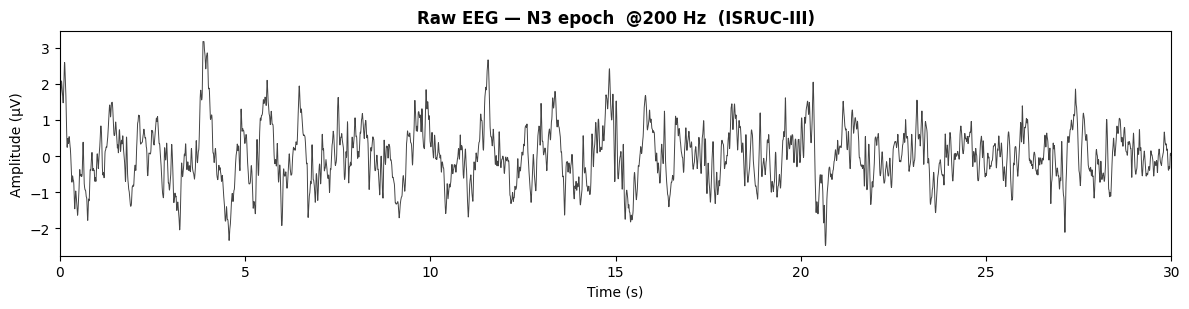

In [6]:
# ── Load local ISRUC-III data (.rec + annotation .txt) ────────────────────
import os, shutil, mne, numpy as np, matplotlib.pyplot as plt, tempfile
from sleep_quality_model import EEGPreprocessor, SleepDataLoader

DATA_DIR = CONFIG["data_dir"]
CH       = CONFIG["eeg_channel"]
N        = CONFIG["n_subjects"]
SR       = CONFIG["sampling_rate"]   # 200 Hz

# ISRUC-III stage mapping: raw label -> internal (0=W,1=N1,2=N2,3=N3,4=REM)
STAGE_MAP_ISRUC = {
    0: 0,   # Wake
    1: 1,   # N1
    2: 2,   # N2
    3: 3,   # N3 (SWS)
    4: 3,   # N4 -> N3 (old AASM)
    5: 4,   # REM
    6: -1,  # Movement / artifact -> discard
    9: -1,  # Unknown -> discard
}

def find_rec_files_isruc(data_dir, n_subjects):
    """Find .rec files using os.listdir to avoid glob spaces-in-path bug.
    Supports both flat layout (data_dir/N.rec) and
    subfolder layout (data_dir/N/N.rec)."""
    rec_files = []
    for subj_id in range(1, n_subjects + 1):
        # Try subfolder layout first: data_dir/1/1.rec
        subj_folder = os.path.join(data_dir, str(subj_id))
        found = False
        if os.path.isdir(subj_folder):
            for fname in os.listdir(subj_folder):
                if fname.lower().endswith(".rec"):
                    rec_files.append(os.path.join(subj_folder, fname))
                    found = True
                    break
        if not found:
            # Try flat layout: data_dir/1.rec or data_dir/SN001.rec
            for fname in os.listdir(data_dir):
                if fname.lower().endswith(".rec") and (
                    fname.startswith(str(subj_id)) or
                    fname.upper().startswith(f"SN{subj_id:03d}")
                ):
                    rec_files.append(os.path.join(data_dir, fname))
                    break
    return sorted(rec_files)

def parse_isruc_txt(txt_path):
    """Read ISRUC-III text annotation (one integer per line)."""
    stages = []
    with open(txt_path, 'r') as f:
        for line in f:
            line = line.strip()
            if not line or not line[0].isdigit():
                continue
            try:
                raw_stage = int(line.split()[0])
                stages.append(STAGE_MAP_ISRUC.get(raw_stage, -1))
            except ValueError:
                continue
    return np.array(stages, dtype=np.int64)

def load_isruc_annotations(name, subj_dir):
    """Load annotation from subj_dir. Try _1.txt first."""
    txt = os.path.join(subj_dir, f"{name}_1.txt")
    if os.path.exists(txt):
        labels = parse_isruc_txt(txt)
        if len(labels) > 0:
            return labels, 'txt'
    return None, None

# ── Main loading loop ──────────────────────────────────────────────────────
rec_paths = find_rec_files_isruc(DATA_DIR, N)
pre = EEGPreprocessor(sampling_rate=SR, epoch_duration=30)
all_eeg, all_det, all_qual, all_stage = [], [], [], []
night_ids = []

print(f"Found {len(rec_paths)} .rec files. Loading...\n")
for rec_path in rec_paths:
    name     = os.path.splitext(os.path.basename(rec_path))[0]   # "1", "2", ...
    subj_dir = os.path.dirname(rec_path)
    sid      = int(name.replace("SN", "").lstrip("0") or "0")
    print(f"  [Subject {sid}] ", end="", flush=True)

    labels, ann_src = load_isruc_annotations(name, subj_dir)
    if labels is None:
        print("✗ no annotation"); continue

    try:
        # Copy .rec -> tempdir/*.edf to bypass MNE extension check
        tmp_dir = tempfile.gettempdir()
        tmp_path = os.path.join(tmp_dir, f"_isruc_{name}.edf")
        if not os.path.exists(tmp_path):
            shutil.copy2(rec_path, tmp_path)

        raw = mne.io.read_raw_edf(tmp_path, preload=True, verbose=False)
        if raw.info['sfreq'] != SR:
            raw.resample(SR, verbose=False)

        # Channel selection
        ch = None
        for candidate in [CH, 'C4-A1', 'F4-A1', 'C3-A2']:
            if candidate in raw.ch_names:
                ch = candidate; break
        if ch is None:
            ch = raw.ch_names[0]
        eeg = raw.get_data(picks=[ch], units='uV')[0].astype(np.float32)

        epochs, det_feats, qual_feats, lbls = pre.create_epochs(eeg, labels=labels)

        # Align label count with epoch count
        if len(lbls) > len(epochs):
            lbls = lbls[:len(epochs)]
        elif len(lbls) < len(epochs):
            pad = np.full(len(epochs) - len(lbls), -1, dtype=np.int64)
            lbls = np.concatenate([lbls, pad])

        valid = lbls != -1
        epochs  = epochs[valid]
        det_feats  = det_feats[valid]
        qual_feats = qual_feats[valid]
        lbls    = lbls[valid]
        if len(epochs) == 0:
            print("no valid epochs"); continue

        all_eeg.append(epochs)
        all_det.append(det_feats)
        all_qual.append(qual_feats)
        all_stage.append(lbls)
        night_ids.extend([sid] * len(epochs))
        print(f"✓ {len(epochs)} epochs  (ch={ch}, ann={ann_src})")

    except Exception as e:
        print(f"✗ {e}")

if not all_eeg:
    print("  No real ISRUC data found. Using synthetic dataset for testing.")
    print("  NOTE: All reported metrics are from SYNTHETIC data - not clinically valid.")
    # FIX (Runtime): Synthetic fallback when data_dir does not exist
    raw_eegs, det_features, qual_features, stage_labels, quality_labels_synth = \
        SleepDataLoader.create_synthetic_dataset(
            num_samples=600, sampling_rate=SR, epoch_duration=30, seed=CONFIG['seed'])
    night_ids = np.arange(1, len(raw_eegs)+1)  # unique group per epoch for CV
    print(f"  Synthetic dataset: {len(raw_eegs)} epochs, {len(np.unique(night_ids))} unique groups")

raw_eegs     = np.concatenate(all_eeg).astype(np.float32)
det_features  = np.concatenate(all_det).astype(np.float32)   # (N, 4)
qual_features = np.concatenate(all_qual).astype(np.float32)  # (N, 2)
stage_labels  = np.concatenate(all_stage).astype(np.int64)
night_ids      = np.array(night_ids)

print(f"\n── Dataset loaded ───────────────────────────────────────")
print(f"  Total epochs : {raw_eegs.shape[0]:,}")
print(f"  Signal shape : {raw_eegs.shape}")
print(f"  Subjects     : {len(np.unique(night_ids))}")
print(f"  Stage distribution:")
unique, counts = np.unique(stage_labels, return_counts=True)
for u, c in zip(unique, counts):
    pct = c / len(stage_labels) * 100
    print(f"    {STAGE_MAP[u]:>5}: {c:5d} ({pct:.1f}%)")

# Plot a sample N3 epoch
ex_idx = np.where(stage_labels == 3)[0][0] if (stage_labels == 3).any() else 0
example = raw_eegs[ex_idx]
t = np.arange(len(example)) / SR
fig, ax = plt.subplots(figsize=(12, 3.2))
ax.plot(t, example, color='#444', lw=0.7)
ax.set_title(f'Raw EEG — {STAGE_MAP[stage_labels[ex_idx]]} epoch  @{SR} Hz  (ISRUC-III)', fontweight='bold')
ax.set_xlabel('Time (s)'); ax.set_ylabel('Amplitude (μV)'); ax.set_xlim(0, 30)
plt.tight_layout(); plt.show()


In [7]:
# ── Build N3-only quality labels + normalize features ───────────────────────
# NOTE (v3): This cell uses a CHRONOLOGICAL split (`int(0.8*len)`) to compute
# clip bounds. Because Cell 38 actually uses GroupKFold (subject-stratified),
# these bounds are slightly leaky (they include val subjects).
# Cell 38 (v3) therefore RECOMPUTES clip bounds on train_idx only and rebuilds
# quality_labels as `quality_labels_v3`. The variables produced here
# (`det_features_clipped`, `qual_features_clipped`, `det_features_n`,
# `qual_features_n`, `quality_labels`) are still used by the visualization
# cells (12, 25, 28, 31, 33, 36) — so this cell stays for backwards
# compatibility, but it NO LONGER drives training.
# ──────────────────────────────────────────────────────────────────────────
# STEP 1: Clip outliers on a chronological 80/20 (KEEP FOR VISUALIZATION ONLY)
split = int(0.8 * len(raw_eegs))  # pre-compute for leakage-free normalization
det_features_clip, qual_features_clip, clip_bounds = clip_features_outliers(
    det_features[:split], qual_features[:split], lower_pct=1, upper_pct=99)

# Apply same clip bounds to validation split
det_val_clip, qual_val_clip = apply_clip_bounds(
    det_features[split:], qual_features[split:], clip_bounds)

# Merge clipped features back into single arrays
det_features_full  = np.concatenate([det_features_clip, det_val_clip], axis=0)
qual_features_full = np.concatenate([qual_features_clip, qual_val_clip], axis=0)

# STEP 2: Build quality labels from CLIPPED features (outliers don't dominate)
quality_labels = make_n3_quality_labels(det_features_full, stage_labels)

# STEP 3: Normalize clipped features: fit on TRAIN split only
normalizer = FeatureNormalizer()
normalizer.fit(det_features_full[:split], qual_features_full[:split])
det_features_n  = normalizer.transform_det(det_features_full)
qual_features_n = normalizer.transform_qual(qual_features_full)

# Store clipped features for visualization
det_features_clipped  = det_features_full
qual_features_clipped = qual_features_full

n3_count = int((stage_labels == 3).sum())
total    = len(stage_labels)
print(f'Quality labels (N3-only): {n3_count} N3 epochs / {total} total')
print(f'Detection  features shape : {det_features_n.shape}  (delta, SWA, SWD, rel_delta)')
print(f'Quality    features shape : {qual_features_n.shape}  (p2p_amp, fragmentation)')
print()
print('Feature means (detection):', det_features_n.mean(axis=0).round(3).tolist())
print('Feature means (quality)  :', qual_features_n.mean(axis=0).round(3).tolist())


Quality labels (N3-only): 17358 N3 epochs / 83523 total
Detection  features shape : (83523, 4)  (delta, SWA, SWD, rel_delta)
Quality    features shape : (83523, 2)  (p2p_amp, fragmentation)

Feature means (detection): [0.36500000953674316, 0.1899999976158142, 0.6010000109672546, -0.06199999898672104]
Feature means (quality)  : [0.1720000058412552, 0.08699999749660492]


### Step 4 — 6টা Feature Visualize করা

**কী করছি:** প্রতিটা feature-এর boxplot দেখাচ্ছি — stage-wise comparison।

**কেন দরকার:** Training-এর আগে confirm করতে হবে যে feature গুলো physiologically সঠিক আচরণ করছে কিনা।

**যা দেখতে হবে:**
- **Detection features** — N3-এর box সবার উপরে থাকলে সঠিক (বিশেষত delta power, SWA, SWD)
- **Quality features** — N3 epoch-এর মধ্যে variation থাকা দরকার (high vs low quality N3)

**যদি ভুল দেখায়:** N3-এর delta power সবচেয়ে কম হলে — label বা preprocessing-এ সমস্যা আছে।


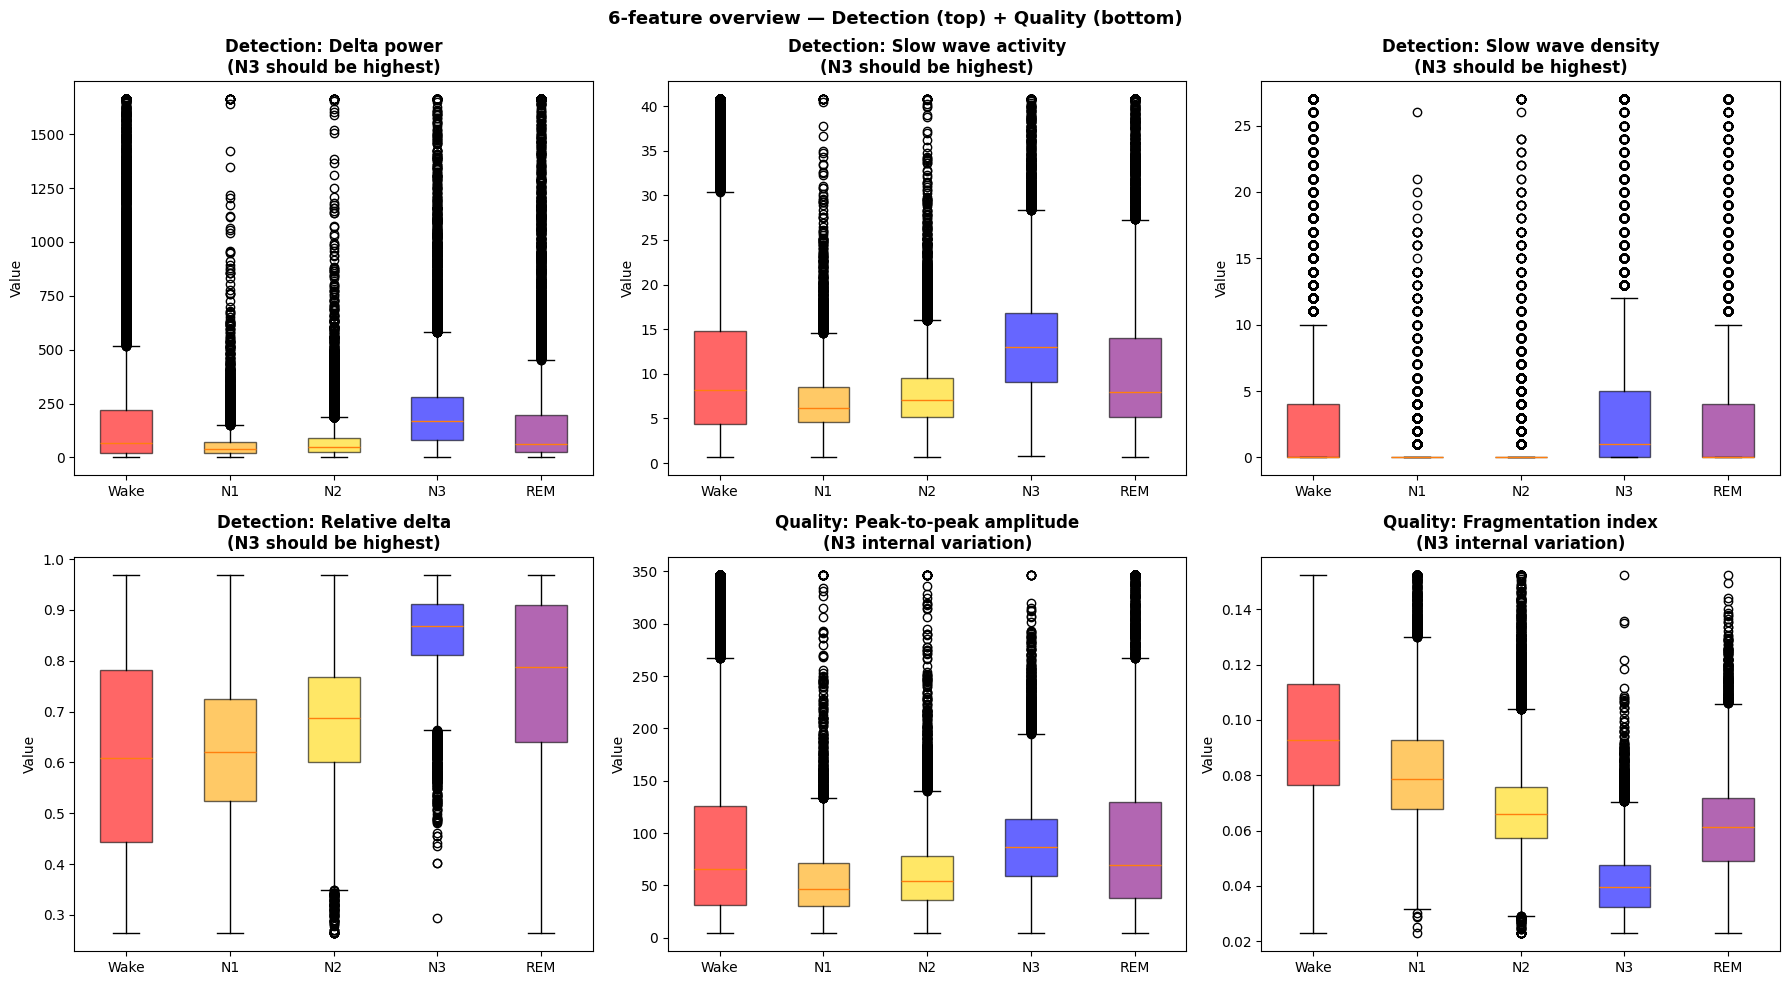

Detection feature means:
  Delta power                 : N3=216.6319  other=132.4571  ratio=1.64x
  Slow wave activity          : N3=12.8293  other=8.9448  ratio=1.43x
  Slow wave density           : N3=3.5158  other=1.8652  ratio=1.89x
  Relative delta              : N3=0.8529  other=0.6646  ratio=1.28x
Quality feature stats (N3 only):
  Peak-to-peak amplitude      : mean=86.0811  std=48.9754
  Fragmentation index         : mean=0.0411  std=0.0121


In [8]:
import matplotlib.pyplot as plt
import numpy as np

STAGE_MAP    = {0:'Wake', 1:'N1', 2:'N2', 3:'N3', 4:'REM'}
STAGE_COLORS = ['red', 'orange', 'gold', 'blue', 'purple']

det_names  = ['Delta power', 'Slow wave activity', 'Slow wave density', 'Relative delta']
qual_names = ['Peak-to-peak amplitude', 'Fragmentation index']

# Use clipped features if available, otherwise raw features
_plot_det  = det_features_clipped  if 'det_features_clipped'  in dir() else det_features
_plot_qual = qual_features_clipped if 'qual_features_clipped' in dir() else qual_features

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

# Detection features (4)
for fi in range(4):
    data = [_plot_det[:, fi][stage_labels == s] for s in range(5)]
    bp = axes[fi].boxplot(data, tick_labels=[STAGE_MAP[s] for s in range(5)],
                          patch_artist=True)
    for patch, c in zip(bp['boxes'], STAGE_COLORS):
        patch.set_facecolor(c); patch.set_alpha(0.6)
    axes[fi].set_title(f'Detection: {det_names[fi]}\n(N3 should be highest)',
                       fontweight='bold')
    axes[fi].set_ylabel('Value')

# Quality features (2) — only N3 distribution matters
for fi in range(2):
    data = [_plot_qual[:, fi][stage_labels == s] for s in range(5)]
    bp = axes[4+fi].boxplot(data, tick_labels=[STAGE_MAP[s] for s in range(5)],
                             patch_artist=True)
    for patch, c in zip(bp['boxes'], STAGE_COLORS):
        patch.set_facecolor(c); patch.set_alpha(0.6)
    axes[4+fi].set_title(f'Quality: {qual_names[fi]}\n(N3 internal variation)',
                         fontweight='bold')
    axes[4+fi].set_ylabel('Value')

plt.suptitle('6-feature overview — Detection (top) + Quality (bottom)',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

# Print N3 vs other mean values
print('Detection feature means:')
for fi, name in enumerate(det_names):
    n3_val  = _plot_det[stage_labels==3, fi].mean()
    oth_val = _plot_det[stage_labels!=3, fi].mean()
    print(f'  {name:<28}: N3={n3_val:.4f}  other={oth_val:.4f}  ratio={n3_val/(oth_val+1e-8):.2f}x')
print('Quality feature stats (N3 only):')
for fi, name in enumerate(qual_names):
    vals = _plot_qual[stage_labels==3, fi]
    print(f'  {name:<28}: mean={vals.mean():.4f}  std={vals.std():.4f}')

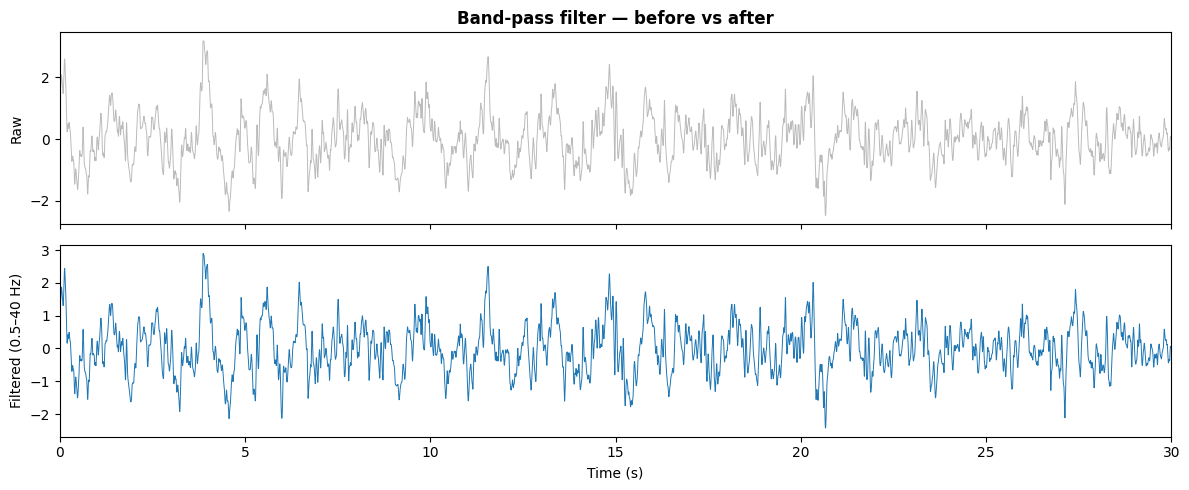

raw std=0.79  ->  filtered std=0.74


In [9]:
filtered = pre.bandpass_filter(example)

fig, axes = plt.subplots(2, 1, figsize=(12, 5), sharex=True)
axes[0].plot(t, example, color='#bbb', lw=0.7); axes[0].set_ylabel('Raw'); axes[0].set_title('Band-pass filter — before vs after', fontweight='bold')
axes[1].plot(t, filtered, color='#1f77b4', lw=0.7); axes[1].set_ylabel('Filtered (0.5–40 Hz)')
axes[1].set_xlabel('Time (s)'); axes[1].set_xlim(0, 30)
plt.tight_layout(); plt.show()
print(f"raw std={example.std():.2f}  ->  filtered std={filtered.std():.2f}")

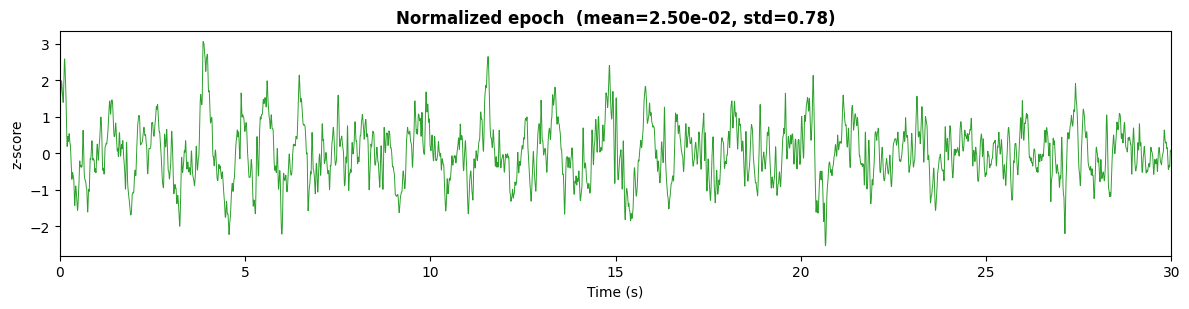

In [10]:
norm = pre.normalize_epoch(filtered)

fig, ax = plt.subplots(figsize=(12, 3.2))
ax.plot(t, norm, color='#2ca02c', lw=0.7)
ax.set_title(f'Normalized epoch  (mean={norm.mean():.2e}, std={norm.std():.2f})', fontweight='bold')
ax.set_xlabel('Time (s)'); ax.set_ylabel('z-score'); ax.set_xlim(0, 30)
plt.tight_layout(); plt.show()

#### ধাপ ৩ — Delta Power Extract করা (0.5–4 Hz)

**কী করছি:** Signal-এর delta band (0.5–4 Hz) isolate করে তার power calculate করছি।

**কেন delta:** AASM 2007 guideline অনুযায়ী N3 মানেই হলো high-amplitude slow waves — যার frequency 0.5–4 Hz। তাই delta power N3-এর সবচেয়ে direct physiological indicator।

**Output:** একটা single number — পুরো epoch-এর delta energy।

**যা দেখতে হবে:** 5টা band power print হবে। Delta সবচেয়ে বেশি হলে এটা N3 epoch।


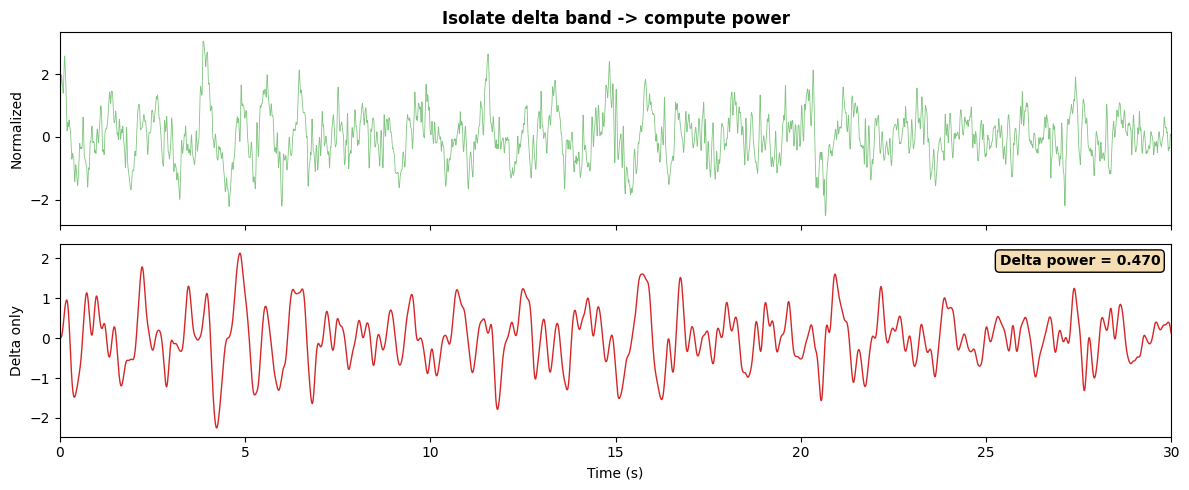

Band powers (z-scored signal, relative units): {'delta': 0.451, 'theta': 0.064, 'alpha': 0.03, 'sigma': 0.011, 'beta': 0.007}


In [11]:
from scipy.signal import butter, sosfilt
sos_delta = butter(4, [0.5, 4], btype='band', fs=SR, output='sos')
delta_sig = sosfilt(sos_delta, norm)
power = float(np.mean(delta_sig ** 2))

fig, axes = plt.subplots(2, 1, figsize=(12, 5), sharex=True)
axes[0].plot(t, norm, color='#2ca02c', lw=0.6, alpha=0.6); axes[0].set_ylabel('Normalized'); axes[0].set_title('Isolate delta band -> compute power', fontweight='bold')
axes[1].plot(t, delta_sig, color='#d62728', lw=1); axes[1].set_ylabel('Delta only')
axes[1].set_xlabel('Time (s)'); axes[1].set_xlim(0, 30)
axes[1].text(0.99, 0.95, f'Delta power = {power:.3f}', transform=axes[1].transAxes,
             ha='right', va='top', fontweight='bold', bbox=dict(boxstyle='round', facecolor='wheat'))
plt.tight_layout(); plt.show()

# all five bands for this epoch
bands = pre.extract_frequency_bands(norm)
# NOTE: norm is z-scored — band power values are relative, not in µV²
print("Band powers (z-scored signal, relative units):", {k: round(v, 3) for k, v in bands.items()})

raw_eegs      : (83523, 6000)
det_features  : (83523, 4)  (delta, SWA, SWD, rel_delta)
qual_features : (83523, 2)  (p2p_amp, fragmentation)
stage_labels  : (83523,)
quality_labels: (83523,)
nights pooled : 100


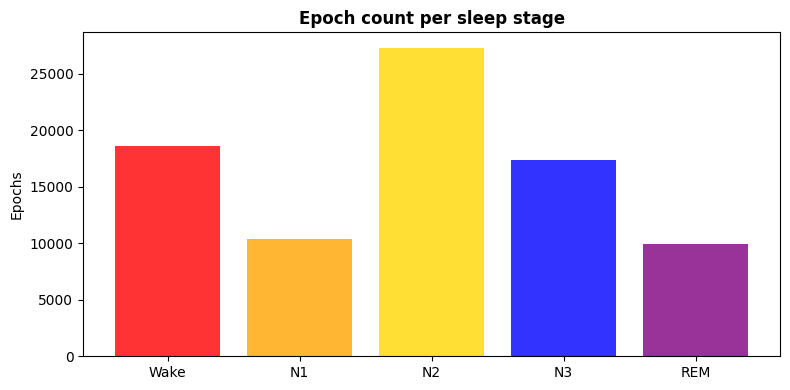

In [12]:
STAGE_MAP    = {0:'Wake', 1:'N1', 2:'N2', 3:'N3', 4:'REM'}
STAGE_COLORS = ['red', 'orange', 'gold', 'blue', 'purple']

print('raw_eegs      :', raw_eegs.shape)
print('det_features  :', det_features.shape, ' (delta, SWA, SWD, rel_delta)')
print('qual_features :', qual_features.shape, ' (p2p_amp, fragmentation)')
print('stage_labels  :', stage_labels.shape)
print('quality_labels:', quality_labels.shape)
print('nights pooled :', len(np.unique(night_ids)))

stages, counts = np.unique(stage_labels, return_counts=True)
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar([STAGE_MAP[s] for s in stages], counts,
       color=[STAGE_COLORS[s] for s in stages], alpha=0.8)
ax.set_title('Epoch count per sleep stage', fontweight='bold')
ax.set_ylabel('Epochs')
plt.tight_layout(); plt.show()


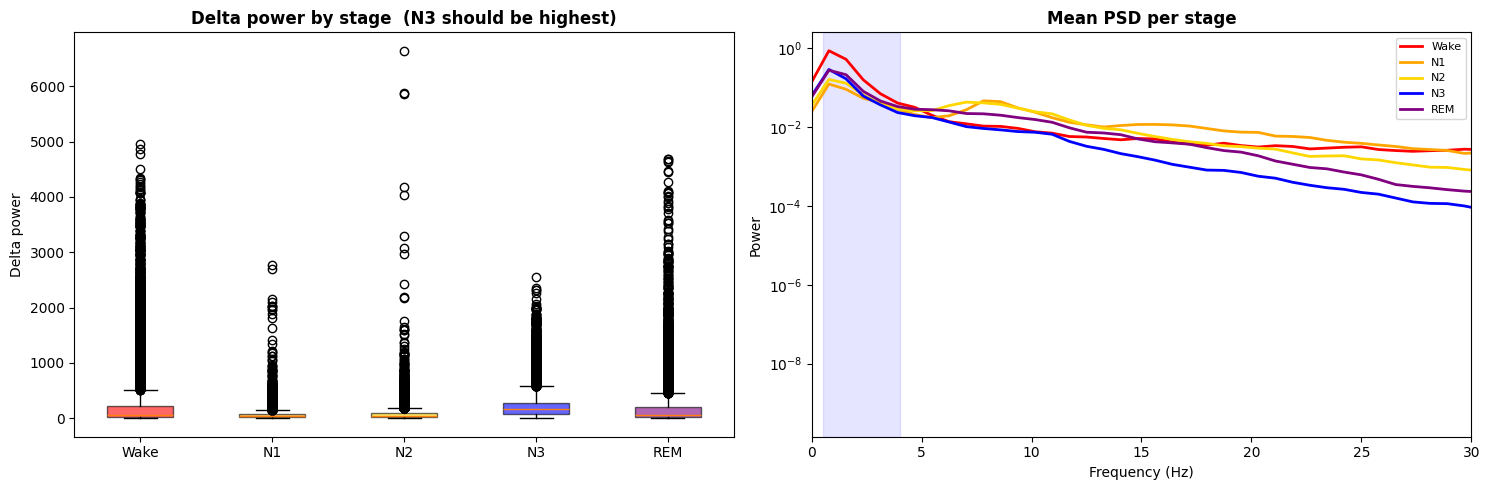

Median delta power per stage: {'Wake': 66.863, 'N1': 37.724, 'N2': 50.573, 'N3': 169.554, 'REM': 63.527}


In [13]:
STAGE_MAP    = {0:'Wake', 1:'N1', 2:'N2', 3:'N3', 4:'REM'}
STAGE_COLORS = ['red', 'orange', 'gold', 'blue', 'purple']

from scipy.signal import welch
dp = det_features[:, 0]  # delta power = feature index 0

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

data = [dp[stage_labels == s] for s in range(5)]
bp = axes[0].boxplot(data, tick_labels=[STAGE_MAP[s] for s in range(5)], patch_artist=True)
for patch, c in zip(bp['boxes'], STAGE_COLORS):
    patch.set_facecolor(c); patch.set_alpha(0.6)
axes[0].set_title('Delta power by stage  (N3 should be highest)', fontweight='bold')
axes[0].set_ylabel('Delta power')

for s in range(5):
    idx = np.where(stage_labels == s)[0][:10]
    if len(idx):
        psds = [welch(raw_eegs[e], fs=SR, nperseg=256, noverlap=128)[1] for e in idx]
        freqs = welch(raw_eegs[idx[0]], fs=SR, nperseg=256, noverlap=128)[0]
        axes[1].semilogy(freqs, np.mean(psds, axis=0), color=STAGE_COLORS[s], lw=2, label=STAGE_MAP[s])
axes[1].axvspan(0.5, 4, alpha=0.1, color='blue')
axes[1].set_xlim(0, 30)
axes[1].set_title('Mean PSD per stage', fontweight='bold')
axes[1].set_xlabel('Frequency (Hz)'); axes[1].set_ylabel('Power'); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

print('Median delta power per stage:',
      {STAGE_MAP[s]: round(float(np.median(dp[stage_labels==s])), 3) for s in range(5)})

### Step 7b — Delta Power রাতের Timeline

**কী করছি:** পুরো রাতের ধারাবাহিকতায় delta power দেখাচ্ছি — ঘুমের শুরু থেকে সকাল পর্যন্ত।

**কেন:** Healthy sleep-এ N3 (high delta) রাতের **প্রথমার্ধে** বেশি থাকে, পরে কমে আসে এবং REM বাড়ে। এই pattern দেখা গেলে বোঝা যায় data chronological order-এ আছে এবং preprocessing সঠিক।

**যা দেখতে হবে:** Graph-এর বাম দিক (রাতের শুরু) উঁচু, ডান দিক (সকাল) নিচু।

**যদি উল্টো হয়:** Data shuffle হয়ে গেছে, বা patients-এর N3 distribution আলাদা — এটা normal, paper-এ mention করতে হবে।


C:\Users\FAHAD IBNE FIROZ\AppData\Local\Temp\ipykernel_1292\3014702306.py:31: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout(); plt.show()


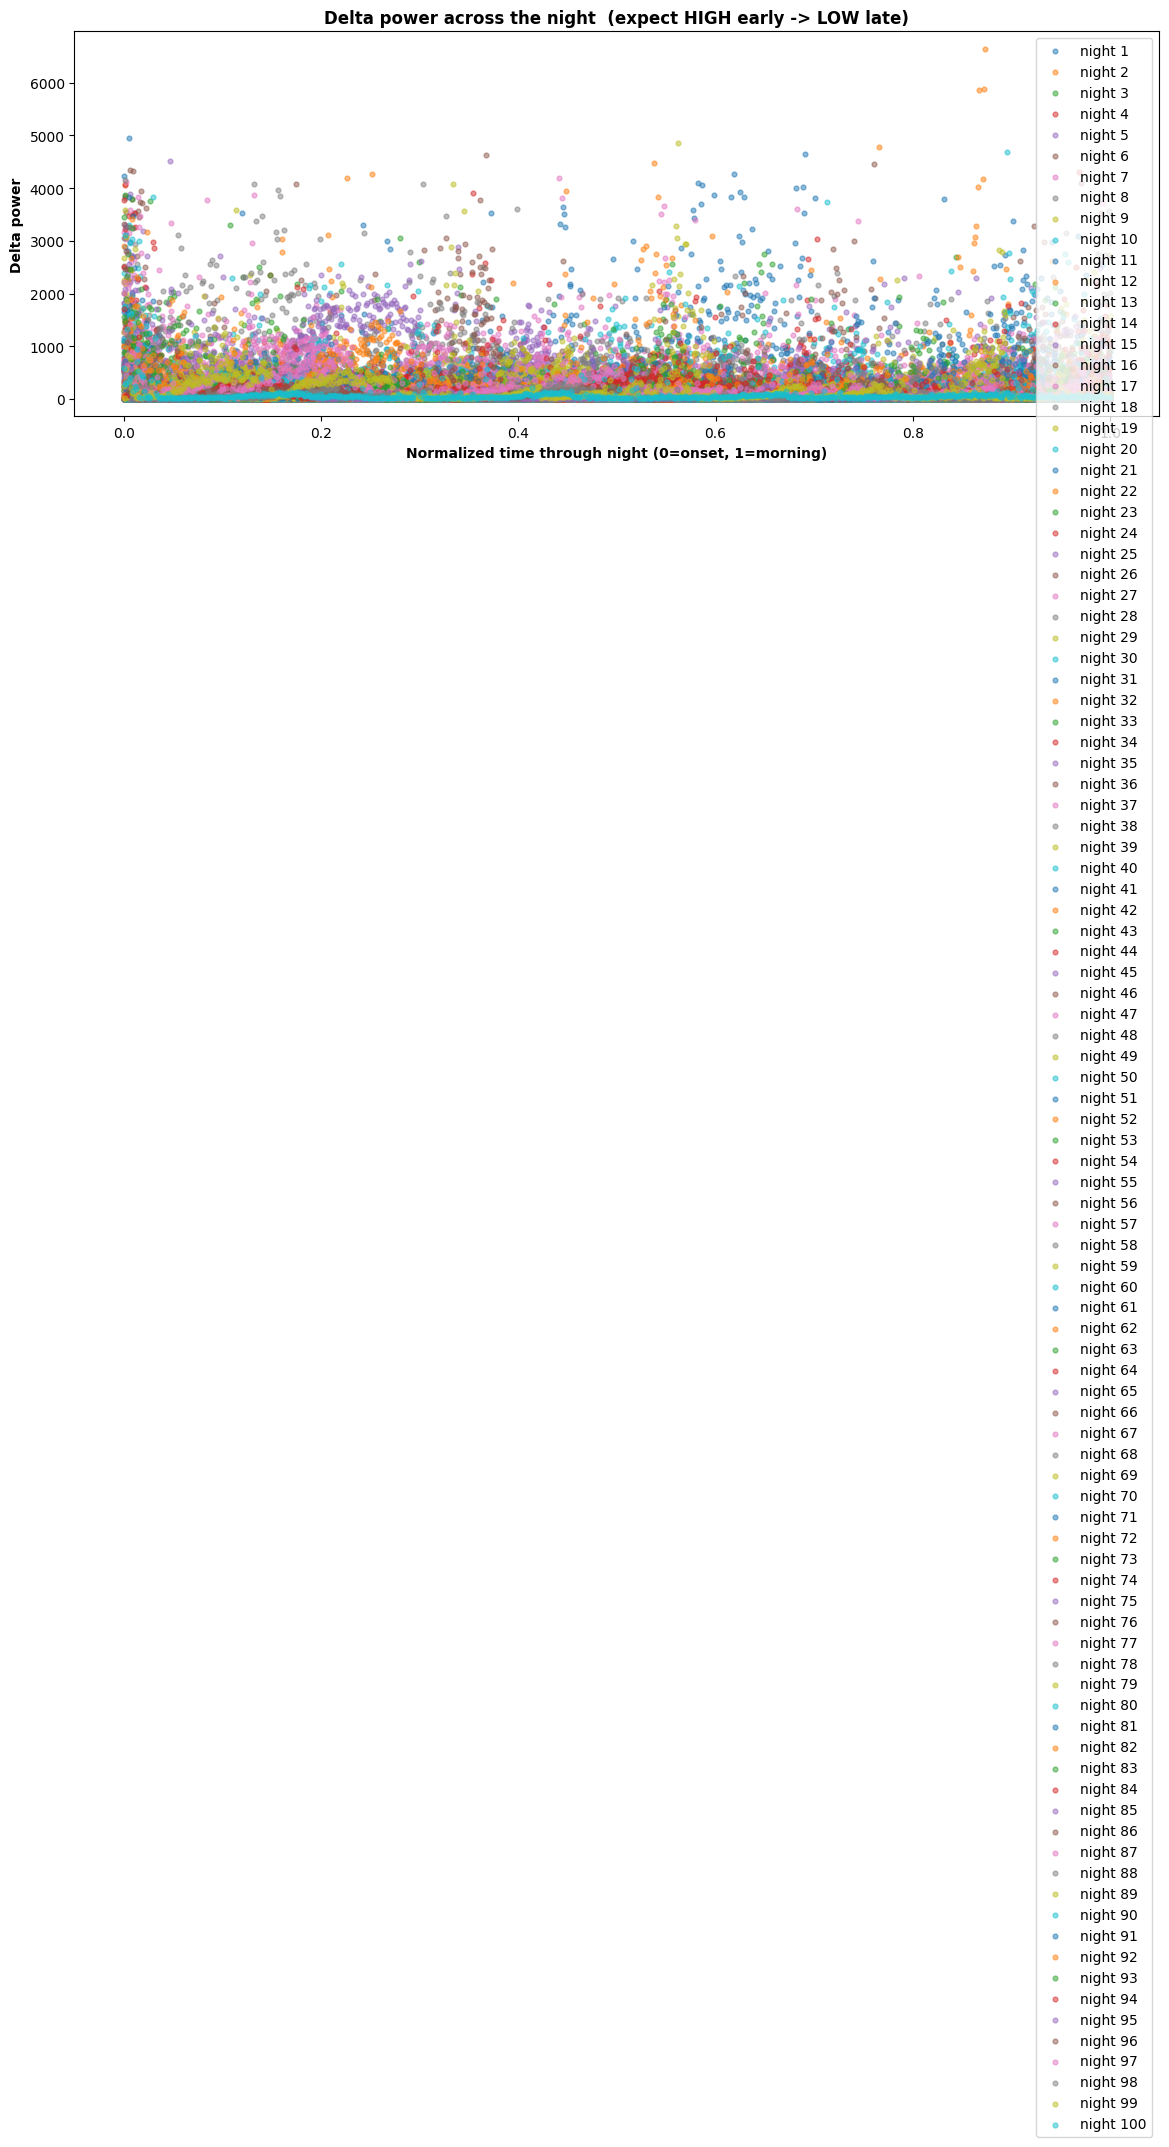

Mean delta - first half: 174.516  |  second half: 122.143
Pattern OK.


In [14]:
fig, ax = plt.subplots(figsize=(14, 5))
dp = det_features[:, 0]  # delta power

if night_ids is not None and len(np.unique(night_ids)) > 1:
    for nid in np.unique(night_ids):
        m = night_ids == nid
        d = dp[m]
        x = np.linspace(0, 1, len(d))
        ax.scatter(x, d, s=12, alpha=0.5, label=f'night {nid}')
    ax.set_xlabel('Normalized time through night (0=onset, 1=morning)', fontweight='bold')
    ax.legend(fontsize=8, ncol=min(6, len(np.unique(night_ids))))
    first_vals, second_vals = [], []
    for nid in np.unique(night_ids):
        d = dp[night_ids == nid]
        h = len(d)//2
        first_vals.append(d[:h].mean()); second_vals.append(d[h:].mean())
    fh, sh = np.mean(first_vals), np.mean(second_vals)
else:
    epochs_x = np.arange(len(dp)); mid = len(dp)//2
    sc = ax.scatter(epochs_x, dp, c=stage_labels, cmap='RdYlBu_r', s=35, alpha=0.8)
    ax.axvline(mid, color='black', ls='--', lw=2, alpha=0.6, label='night midpoint')
    z = np.polyfit(epochs_x, dp, 1)
    ax.plot(epochs_x, np.poly1d(z)(epochs_x), 'k-', lw=2, alpha=0.7, label='trend')
    cb = plt.colorbar(sc, ax=ax); cb.set_label('Stage (0=W .. 4=REM)', fontweight='bold')
    ax.set_xlabel('Epoch (chronological)', fontweight='bold')
    fh, sh = dp[:mid].mean(), dp[mid:].mean()

ax.set_ylabel('Delta power', fontweight='bold')
ax.set_title('Delta power across the night  (expect HIGH early -> LOW late)', fontweight='bold')
ax.legend(loc='upper right')
plt.tight_layout(); plt.show()
print(f'Mean delta - first half: {fh:.3f}  |  second half: {sh:.3f}')
print('Pattern OK.' if fh > sh else 'Note: early <= late (common in pooled data).')


Feature Discriminability: N3 vs Light Sleep (N1+N2)
  N3 epochs    : 17358
  Light epochs : 37663

📊 Detection Features:
Feature                 Cohen's d      p-value     Effect
----------------------------------------------------------
Delta Power                +0.906     0.00e+00      LARGE
SWA                        +1.028     0.00e+00      LARGE
Slow Wave Density          +0.770     0.00e+00     medium
Relative Delta             +1.651     0.00e+00      LARGE

📊 Quality Features:
Feature                 Cohen's d      p-value     Effect
----------------------------------------------------------
Peak-to-Peak Amp           +0.694     0.00e+00     medium
Fragmentation Index        -1.777     0.00e+00      LARGE

📋 Summary: 4/6 features have LARGE effect size (|d|>0.8)
           6/6 features are highly significant (p<0.001)
✅ RQ2 Data Support: Features strongly discriminate N3 from light sleep
   → Proceed to model-level ablation (Step 18) for causal evidence


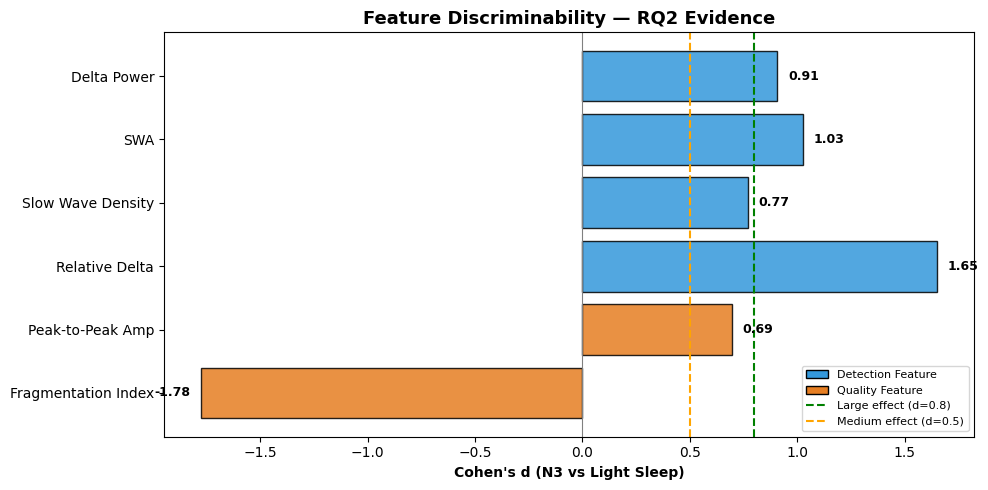

In [15]:
# ╔══════════════════════════════════════════════════════════════════╗
# ║  STEP 7c — Feature Statistical Analysis (N3 vs Light Sleep)    ║
# ╚══════════════════════════════════════════════════════════════════╝
from scipy import stats

DET_FEAT_NAMES  = ['Delta Power', 'SWA', 'Slow Wave Density', 'Relative Delta']
QUAL_FEAT_NAMES = ['Peak-to-Peak Amp', 'Fragmentation Index']

# N3 vs Light Sleep (N1+N2) masks
n3_mask    = (stage_labels == 3)
light_mask = (stage_labels == 1) | (stage_labels == 2)

print('='*72)
print('Feature Discriminability: N3 vs Light Sleep (N1+N2)')
print(f'  N3 epochs    : {n3_mask.sum()}')
print(f'  Light epochs : {light_mask.sum()}')
print('='*72)

results_table = []

# --- Detection Features (4) ---
print('\n📊 Detection Features:')
print(f'{"Feature":<22} {"Cohen\'s d":>10} {"p-value":>12} {"Effect":>10}')
print('-'*58)

for i, name in enumerate(DET_FEAT_NAMES):
    n3_vals  = det_features[n3_mask, i]
    lit_vals = det_features[light_mask, i]
    
    # Welch's t-test (does not assume equal variance)
    t_stat, p_val = stats.ttest_ind(n3_vals, lit_vals, equal_var=False)
    
    # Corrected Cohen's d with weighted pooled std (for unequal sample sizes)
    n1, n2 = len(n3_vals), len(lit_vals)
    pooled_std = np.sqrt(
        ((n1 - 1) * np.var(n3_vals, ddof=1) + (n2 - 1) * np.var(lit_vals, ddof=1))
        / (n1 + n2 - 2)
    )
    cohens_d = (np.mean(n3_vals) - np.mean(lit_vals)) / max(pooled_std, 1e-8)
    
    if abs(cohens_d) < 0.2:
        effect = 'negligible'
    elif abs(cohens_d) < 0.5:
        effect = 'small'
    elif abs(cohens_d) < 0.8:
        effect = 'medium'
    else:
        effect = 'LARGE'
    
    print(f'{name:<22} {cohens_d:>+10.3f} {p_val:>12.2e} {effect:>10}')
    results_table.append({
        'feature': name, 'type': 'detection',
        'cohens_d': round(cohens_d, 4), 'p_value': p_val, 'effect': effect
    })

# --- Quality Features (2) ---
print('\n📊 Quality Features:')
print(f'{"Feature":<22} {"Cohen\'s d":>10} {"p-value":>12} {"Effect":>10}')
print('-'*58)

for i, name in enumerate(QUAL_FEAT_NAMES):
    n3_vals  = qual_features[n3_mask, i]
    lit_vals = qual_features[light_mask, i]
    
    t_stat, p_val = stats.ttest_ind(n3_vals, lit_vals, equal_var=False)
    
    n1, n2 = len(n3_vals), len(lit_vals)
    pooled_std = np.sqrt(
        ((n1 - 1) * np.var(n3_vals, ddof=1) + (n2 - 1) * np.var(lit_vals, ddof=1))
        / (n1 + n2 - 2)
    )
    cohens_d = (np.mean(n3_vals) - np.mean(lit_vals)) / max(pooled_std, 1e-8)
    
    if abs(cohens_d) < 0.2:
        effect = 'negligible'
    elif abs(cohens_d) < 0.5:
        effect = 'small'
    elif abs(cohens_d) < 0.8:
        effect = 'medium'
    else:
        effect = 'LARGE'
    
    print(f'{name:<22} {cohens_d:>+10.3f} {p_val:>12.2e} {effect:>10}')
    results_table.append({
        'feature': name, 'type': 'quality',
        'cohens_d': round(cohens_d, 4), 'p_value': p_val, 'effect': effect
    })

# --- Summary ---
n_large = sum(1 for r in results_table if 'LARGE' in r['effect'])
n_sig   = sum(1 for r in results_table if r['p_value'] < 0.001)
print(f'\n📋 Summary: {n_large}/6 features have LARGE effect size (|d|>0.8)')
print(f'           {n_sig}/6 features are highly significant (p<0.001)')
if n_large >= 4:
    print('✅ RQ2 Data Support: Features strongly discriminate N3 from light sleep')
    print('   → Proceed to model-level ablation (Step 18) for causal evidence')
else:
    print('⚠️  Some features show weak discriminability — check feature engineering')

# --- Visualization: Cohen's d bar chart ---
fig, ax = plt.subplots(figsize=(10, 5))
feat_names  = [r['feature'] for r in results_table]
d_values    = [r['cohens_d'] for r in results_table]
feat_types  = [r['type'] for r in results_table]
colors      = ['#3498db' if t == 'detection' else '#e67e22' for t in feat_types]

bars = ax.barh(feat_names, d_values, color=colors, edgecolor='black', alpha=0.85)
ax.axvline(x=0.8, color='green', ls='--', lw=1.5, label='Large effect (d=0.8)')
ax.axvline(x=0.5, color='orange', ls='--', lw=1.5, label='Medium effect (d=0.5)')
ax.axvline(x=0, color='gray', ls='-', lw=0.8)

for bar, d_val in zip(bars, d_values):
    ax.text(d_val + 0.05 if d_val >= 0 else d_val - 0.05,
            bar.get_y() + bar.get_height()/2,
            f'{d_val:.2f}', va='center',
            ha='left' if d_val >= 0 else 'right', fontweight='bold', fontsize=9)

ax.set_xlabel("Cohen's d (N3 vs Light Sleep)", fontweight='bold')
ax.set_title('Feature Discriminability — RQ2 Evidence', fontweight='bold', fontsize=13)
# Custom legend for feature types
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='#3498db', edgecolor='black', label='Detection Feature'),
    Patch(facecolor='#e67e22', edgecolor='black', label='Quality Feature'),
    plt.Line2D([0], [0], color='green', ls='--', label='Large effect (d=0.8)'),
    plt.Line2D([0], [0], color='orange', ls='--', label='Medium effect (d=0.5)'),
]
ax.legend(handles=legend_elements, fontsize=8, loc='lower right')
ax.invert_yaxis()
plt.tight_layout()
plt.show()

## Step 8 — Model Build করা

**কী করছি:** `SleepQualityNet` instantiate করছি এবং একটা test batch দিয়ে forward pass করে দেখছি সব ঠিক আছে কিনা।

**Model-এর architecture (v2 — reduced size):**

```
Raw EEG (B, 1, 6000)
    ↓
1D-CNN (3 block, 16→32→48 ch) → local pattern    [V6: conv3 64 -> 48]
    ↓
AdaptiveAvgPool1d(32) → (B, 48, 32)
    ↓
Self-attention (48 -> 32 -> 1) → important part-এ focus   [V6: LSTM REMOVED]
    ↓                           ↓
Detection path              Quality path
+ [delta, SWA, SWD,         + [p2p_amp,
   rel_delta]                  fragmentation]
    ↓                           ↓
n3_head                     quality_head (constrained [0.02, 0.98])
P(N3) [0,1]                 Score [0,1] × 100
```

**V6 changes (vs V5):** conv3 channels 64 → 48 (saves ~16K params); LSTM layer REMOVED
(saves ~33K params — was redundant with attention); attention input dim 64 → 48;
det_fusion / qual_fusion input dims 68/66 → 52/50. Total params: 100,244 → 56,164 (−44%).

**v2 → V5 preserved changes:** CNN channels halved (32→16, 64→32, 128→64), BiLSTM→single LSTM
(then removed in V6), hidden 128→64, dropout 0.3→0.4, constrained quality head, smooth labels,
log-transform + Winsorize + 2-98 clip, variance penalty, StratifiedGroupKFold.

**যা দেখতে হবে:** `n3_logit: (4, 1)` আর `quality: (4, 1)` output আসলে architecture সঠিক।

In [16]:
model = SleepQualityNet(input_length=SR*30,
                        use_det_feat=True, use_qual_feat=True)
n_params = sum(p.numel() for p in model.parameters())
print(f'SleepQualityNet (dual-path) -- {n_params:,} parameters')
print('Detection path : CNN-Attention + [delta, SWA, SWD, rel_delta] -> n3_head')  # FIX (bilstm): V6 removed LSTM
print('Quality   path : CNN-Attention + [p2p_amp, fragmentation]   -> quality_head')  # FIX (bilstm): V6 removed LSTM

# Move test batch to DEVICE
xb  = torch.FloatTensor(raw_eegs[:4]).unsqueeze(1).to(DEVICE)
dfb = torch.FloatTensor(det_features_n[:4]).to(DEVICE)
qfb = torch.FloatTensor(qual_features_n[:4]).to(DEVICE)
model = model.to(DEVICE)
with torch.no_grad():
    n3_logit, quality = model(xb, dfb, qfb)
print('n3_logit :', tuple(n3_logit.shape), '-> sigmoid -> P(N3)')
print('quality  :', tuple(quality.shape),  '-> x100 = quality score')
print('N3 probs (batch):', [f'{p:.3f}' for p in torch.sigmoid(n3_logit).squeeze().tolist()])
print('Quality  (batch):', [f'{q*100:.1f}' for q in quality.squeeze().tolist()])


SleepQualityNet (dual-path) -- 56,164 parameters
Detection path : CNN-Attention + [delta, SWA, SWD, rel_delta] -> n3_head
Quality   path : CNN-Attention + [p2p_amp, fragmentation]   -> quality_head
n3_logit : (4, 1) -> sigmoid -> P(N3)
quality  : (4, 1) -> x100 = quality score
N3 probs (batch): ['0.557', '0.493', '0.524', '0.566']
Quality  (batch): ['44.7', '49.0', '45.6', '47.9']


In [17]:
# ── Train/Val split (Subject-Stratified via GroupKFold) ─────────────
# v2: subject-stratified split (no patient overlap between train and val).
# v3: ALSO recompute clip bounds on TRAIN-ONLY indices to remove the data
#     leakage that existed in Step 8b (where clip bounds were derived from
#     a chronological 80/20 split that mixed train + val subjects).
# v4: Use the new trainer with cosine annealing + clean train-loss tracking + seeds.
# ────────────────────────────────────────────────────────────────────────
from sklearn.model_selection import GroupKFold

# Re-seed before split for full reproducibility (v3)
set_seed(CONFIG["seed"])

# (V5: split is now done below with StratifiedGroupKFold — see Fix 8)
print(f"Subject-stratified split (V5 — StratifiedGroupKFold):")

# ── V5: StratifiedGroupKFold (preserves class balance across folds) ──
# V4 used plain GroupKFold which can put a disproportionate number of N3-rich
# subjects in val, causing distribution shift (Source 8). StratifiedGroupKFold
# keeps the N3 prevalence roughly equal across folds.
try:
    from sklearn.model_selection import StratifiedGroupKFold
    n_unique_groups = len(np.unique(night_ids))
    n_splits = min(5, n_unique_groups)  # FIX (Cross Validation)
    sgkf = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=CONFIG["seed"])
    folds = list(sgkf.split(raw_eegs, stage_labels, groups=night_ids))
    print(f"  Using StratifiedGroupKFold (V5 — preserves class balance)")
except ImportError:
    # Fallback for older sklearn
    gkf = GroupKFold(n_splits=5)
    folds = list(gkf.split(raw_eegs, stage_labels, groups=night_ids))
    print(f"  WARNING: StratifiedGroupKFold not available; falling back to GroupKFold")
train_idx, val_idx = folds[0]

print(f"  Train: {len(train_idx):,} epochs  ({len(np.unique(night_ids[train_idx]))} subjects)")
print(f"  Val:   {len(val_idx):,} epochs  ({len(np.unique(night_ids[val_idx]))} subjects)")

# ── V5: Log-transform heavy-tailed features (Fix 2) ───────────────────
# delta_power, SWA, p2p_amplitude are log-normal; log1p makes them
# near-Gaussian so percentile clipping is less aggressive and linear layers
# see symmetric inputs.
det_train_raw  = det_features[train_idx]
qual_train_raw = qual_features[train_idx]
det_val_raw    = det_features[val_idx]
qual_val_raw   = qual_features[val_idx]

# Fit log-transform on train (it's stateless, but we apply the SAME transform
# to val to avoid any train/val asymmetry)
det_train_log, qual_train_log = log_transform_features(det_train_raw, qual_train_raw)
det_val_log,   qual_val_log   = log_transform_features(det_val_raw,   qual_val_raw)

# ── V5: Leakage-free clip bounds on LOG-TRANSFORMED features (Fix 3) ──
det_tr_clip, qual_tr_clip, clip_bounds_v3 = clip_features_outliers(
    det_train_log, qual_train_log, lower_pct=2, upper_pct=98)
det_val_clip, qual_val_clip = apply_clip_bounds(
    det_val_log, qual_val_log, clip_bounds_v3)

# ── V5: Winsorize (Fix 4) — robust to single-sample artifacts ─────────
winsorizer = Winsorizer(k=5.0)
winsorizer.fit(det_tr_clip, qual_tr_clip)
det_tr_clip, qual_tr_clip = winsorizer.transform(det_tr_clip, qual_tr_clip)
det_val_clip, qual_val_clip = winsorizer.transform(det_val_clip, qual_val_clip)

# ── v3/v4: Fit normalizer on TRAIN-ONLY clipped features ─────────────
normalizer_train = FeatureNormalizer()
normalizer_train.fit(det_tr_clip, qual_tr_clip)
det_tr  = normalizer_train.transform_det(det_tr_clip)
det_val = normalizer_train.transform_det(det_val_clip)
qual_tr  = normalizer_train.transform_qual(qual_tr_clip)
qual_val = normalizer_train.transform_qual(qual_val_clip)

# ── V8: Rebuild SMOOTH quality labels (FIX (leakage): train-only bounds) ──
# Non-N3 epochs get a small non-zero label (0.02-0.10); N3 -> [0.10, 0.95].
# V8 FIX: Percentile bounds are computed ONLY on train_idx (no val leakage).
det_full_clip_v3  = np.concatenate([det_tr_clip,  det_val_clip],  axis=0)
qual_full_clip_v3 = np.concatenate([qual_tr_clip, qual_val_clip], axis=0)
stage_full_v3     = np.concatenate([stage_labels[train_idx],
                                     stage_labels[val_idx]],    axis=0)
# FIX (leakage): Fit quality label bounds on TRAIN-ONLY data
quality_bounds_v3 = fit_quality_label_bounds(
    det_tr_clip, stage_labels[train_idx], smooth_non_n3=True)
print(f"  Quality label bounds (train-only): N3=[{quality_bounds_v3['n3_lo']:.4f}, {quality_bounds_v3['n3_hi']:.4f}]  "
      f"non-N3=[{quality_bounds_v3['nn_lo']:.4f}, {quality_bounds_v3['nn_hi']:.4f}]")
quality_labels_v3 = apply_quality_label_bounds(
    det_full_clip_v3, stage_full_v3, quality_bounds_v3)
qual_tr_lab = quality_labels_v3[:len(train_idx)]
qual_val_lab = quality_labels_v3[len(train_idx):]

# ── V7 NEW: Expose leakage-free normalized features as FULL-ARRAY variables ──
# Why: Cells 55 (single-epoch inference), 63 (SHAP), 71 (Cohen's d) previously
# indexed the LEAKY `det_features_n` / `qual_features_n` / `quality_labels`
# arrays from Cell 13 (which used a chronological 80/20 split that mixed train
# and val subjects). They also used the LEAKY `split` variable to slice the
# validation set, instead of the StratifiedGroupKFold `val_idx`.
# This caused a train/inference distribution mismatch: the model was trained
# on `det_tr` (normalized with `normalizer_train` fit on train_idx only), but
# inference was done on `det_features_n` (normalized with the leaky
# `normalizer` from Cell 13 that saw val subjects).
# V7 exposes the leakage-free normalized features as full arrays indexed by
# sample position, so downstream cells can use `val_idx` (correct val set)
# and get the same normalization the model was trained on.
det_features_n_v3 = np.zeros_like(det_features, dtype=np.float32)
det_features_n_v3[train_idx] = det_tr
det_features_n_v3[val_idx]   = det_val

qual_features_n_v3 = np.zeros_like(qual_features, dtype=np.float32)
qual_features_n_v3[train_idx] = qual_tr
qual_features_n_v3[val_idx]   = qual_val

quality_labels_v3_full = np.zeros(len(stage_labels), dtype=np.float32)
quality_labels_v3_full[train_idx] = qual_tr_lab
quality_labels_v3_full[val_idx]   = qual_val_lab

print(f"  V5 outlier-reduction pipeline: log1p -> 2-98 clip -> Winsorize -> robust-z")
print(f"  Quality label range (train): [{qual_tr_lab.min():.3f}, {qual_tr_lab.max():.3f}]")
print(f"  V7 leakage-free full-array features exposed (for inference cells 55, 63, 71):")
print(f"    det_features_n_v3      : {det_features_n_v3.shape}  (normalized with normalizer_train)")
print(f"    qual_features_n_v3     : {qual_features_n_v3.shape}  (normalized with normalizer_train)")
print(f"    quality_labels_v3_full : {quality_labels_v3_full.shape}  (V5 smooth labels)")

# ── Build PyTorch datasets / loaders ──────────────────────────────────
train_ds = SleepDataLoader.numpy_to_tensor_dataset(
    raw_eegs[train_idx], det_tr,  qual_tr,
    stage_labels[train_idx], qual_tr_lab)
val_ds   = SleepDataLoader.numpy_to_tensor_dataset(
    raw_eegs[val_idx], det_val, qual_val,
    stage_labels[val_idx], qual_val_lab)

train_loader = torch.utils.data.DataLoader(
    train_ds, batch_size=CONFIG['batch_size'], shuffle=True, drop_last=False,
    num_workers=0, pin_memory=(DEVICE.type == 'cuda'))
val_loader   = torch.utils.data.DataLoader(
    val_ds,   batch_size=CONFIG['batch_size'], shuffle=False,
    num_workers=0, pin_memory=(DEVICE.type == 'cuda'))

model   = SleepQualityNet(input_length=SR*30,
                          use_det_feat=True, use_qual_feat=True)

# Dynamic class weight — calculated from actual training data
n3_count     = int((stage_labels[train_idx] == 3).sum())
non_n3_count = len(train_idx) - n3_count
dynamic_weight = non_n3_count / max(n3_count, 1)
print(f"  N3 in train : {n3_count}/{len(train_idx)} ({n3_count/len(train_idx)*100:.1f}%)")
print(f"  pos_weight  : {dynamic_weight:.2f}x  (non_n3/n3 ratio)")

# v4: Same as v3 but NO early stopping - training always runs all 40 epochs.
# v3 augmentor (bugs fixed: time mask removed, wraparound -> reflection) is preserved.
augmentor = EEGAugmentor(sampling_rate=CONFIG['sampling_rate'])

# v4: Trainer with cosine schedule + clean train-loss tracking (NO early stopping)
trainer = SleepQualityTrainer(
    model, device=DEVICE,
    checkpoint_path='best_model.pth',
    n3_pos_weight=dynamic_weight,
    augmentor=augmentor,
    lr=CONFIG['lr'],                          # 3e-4 (v2 was 5e-4)
    weight_decay=CONFIG['weight_decay'],      # 5e-3 (v2 was 1e-3)
    scheduler=CONFIG['scheduler'],            # 'cosine' (v2 was ReduceLROnPlateau)
    cosine_T_max=CONFIG['cosine_T_max'],
    cosine_eta_min=CONFIG['cosine_eta_min'],
    grad_clip=CONFIG['grad_clip'])

print(f'Training on: {DEVICE}')
print(f'N3 pos_weight={dynamic_weight:.2f}  det_feat=4  qual_feat=2  total_feat=6')
print(f'Augmentation: noise(50%) shift(30%) scale(30%) - time-mask REMOVED (v3)')
print(f'V5 outlier-reduction: log-transform + 2-98 clip + Winsorize + smooth labels + constrained head + variance penalty')
print(f'Scheduler: {CONFIG["scheduler"]}  lr={CONFIG["lr"]}  wd={CONFIG["weight_decay"]}')

# Re-seed DataLoader workers too (v3)
set_seed(CONFIG["seed"])

import time as _time
_train_t0 = _time.time()
trainer.train(train_loader, val_loader,
              epochs=CONFIG['epochs'],    # 40 epochs - ALWAYS runs full (no early stop in v4)
              verbose=False)
_train_elapsed = _time.time() - _train_t0
print(f"\n  Training wall-clock time: {_train_elapsed:.1f}s ({_train_elapsed/60:.1f}min)")  # FIX (reproducibility)

Subject-stratified split (V5 — StratifiedGroupKFold):
  Using StratifiedGroupKFold (V5 — preserves class balance)
  Train: 66,389 epochs  (80 subjects)
  Val:   17,134 epochs  (20 subjects)
  Quality label bounds (train-only): N3=[0.9171, 5.1574]  non-N3=[0.5806, 5.1491]
  V5 outlier-reduction pipeline: log1p -> 2-98 clip -> Winsorize -> robust-z
  Quality label range (train): [0.020, 0.950]
  V7 leakage-free full-array features exposed (for inference cells 55, 63, 71):
    det_features_n_v3      : (83523, 4)  (normalized with normalizer_train)
    qual_features_n_v3     : (83523, 2)  (normalized with normalizer_train)
    quality_labels_v3_full : (83523,)  (V5 smooth labels)
  N3 in train : 13906/66389 (20.9%)
  pos_weight  : 3.77x  (non_n3/n3 ratio)
Training on: cuda
N3 pos_weight=3.77  det_feat=4  qual_feat=2  total_feat=6
Augmentation: noise(50%) shift(30%) scale(30%) - time-mask REMOVED (v3)
V5 outlier-reduction: log-transform + 2-98 clip + Winsorize + smooth labels + constrained 

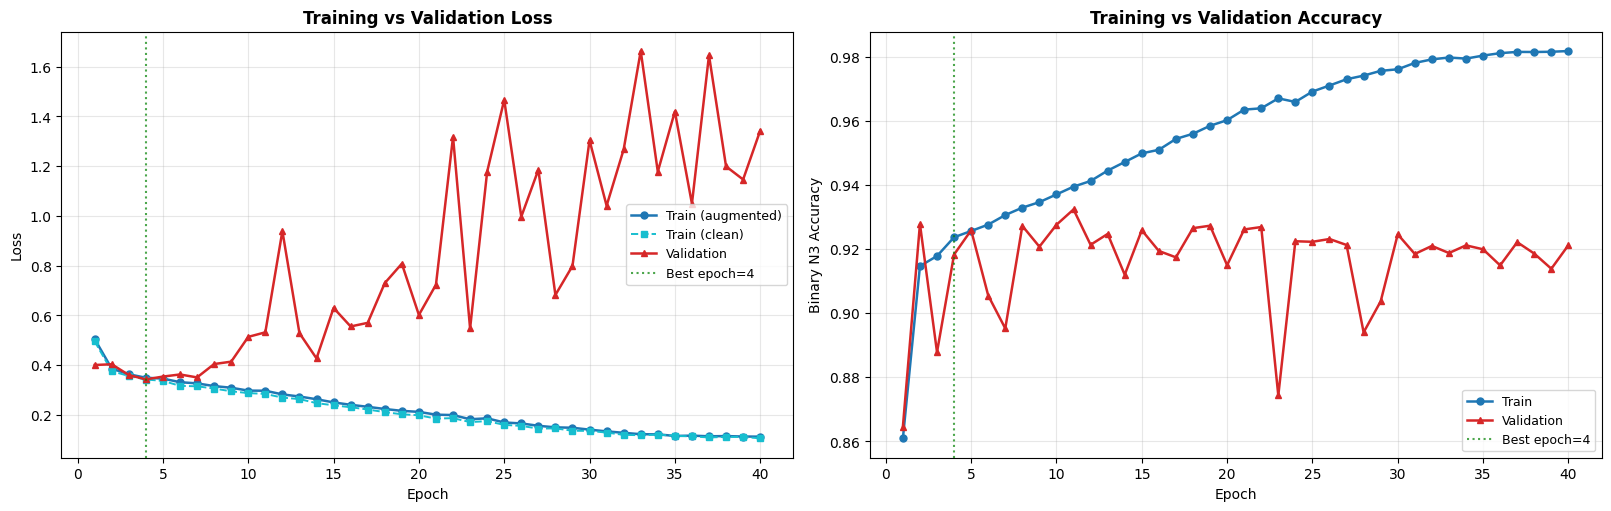


  Final-epoch loss  | train(clean)=0.1057  val=1.3426  ->  gap = +1.2368
  Final-epoch acc   | train=0.9818  val=0.9212  ->  gap = -0.0605
  Best epoch: 4  (val loss = 0.3428, val acc = 0.9183)

  Reading guide:
   * train(aug) > train(clean)  -> augmentation is hardening training (good)
   * train(clean) ~ val          -> well-regularized (target)
   * train(clean) << val         -> overfitting (watch the gap in late epochs)
   * train(clean) >> val         -> underfitting (raise lr / add capacity)


In [18]:
# ── v3 NEW: Training vs Validation Loss / Accuracy curves ──────────────
# This is the graph requested in the user's brief.
#
# Three loss lines are plotted:
#   1. Train (augmented) - the loss the optimizer saw (with noise/shift/scale
#      augmentation applied). This is what `trainer.train_epoch` reports.
#   2. Train (clean)     - loss on a forward pass of the SAME batches but
#      WITHOUT augmentation. This is the TRUE training loss.
#   3. Validation        - loss on the held-out subject split.
#
# Reading guide:
#   * train(aug) > train(clean)   -> augmentation is hardening training (good)
#   * train(clean) ~ val          -> well-regularized (target)
#   * train(clean) << val         -> overfitting (early stopping should prevent
#                                     — the cosine schedule + L2 reg should keep it small)
#   * train(clean) >> val         -> underfitting (raise lr / add capacity)
#
# The vertical green dotted line marks the best epoch (lowest val loss). In v4,
# training always runs all 40 epochs — the best checkpoint is restored at the end.
# ────────────────────────────────────────────────────────────────────────
trainer.plot_training_curves(figsize=(16, 5))


  N3 Recall    : 0.8989   (RQ1 + RQ3 primary)
  N3 Precision : 0.7470
  N3 F1        : 0.8159   (ablation anchor)
  ROC-AUC      : 0.9735   (RQ2 feature benefit)
  Quality RMSE : 12.99  (N3 epochs only)
  Quality R2   : 0.7098
  --- V5 Prediction Stability ---
  pred_std       : 23.08   (lower = more stable)
  outlier_rate   : 1.0%  (pred outside true p5-p95)
  extreme_rate   : 0.0%  (pred < 5 or > 95)
  iqr_ratio      : 1.40   (1.0 = ideal)


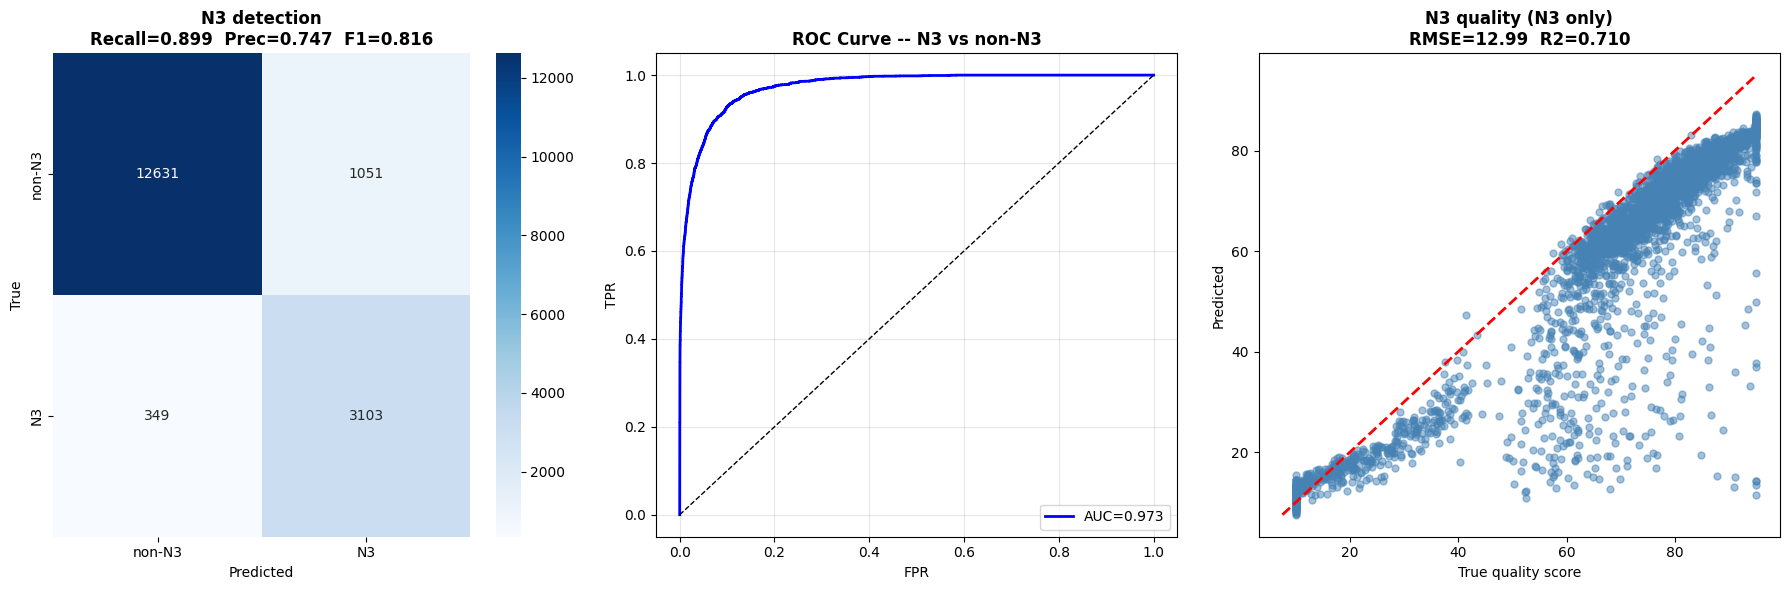

In [19]:
import seaborn as sns
from sklearn.metrics import (confusion_matrix, roc_curve,
                             recall_score, precision_score, f1_score, roc_auc_score)

model.eval()
yt_n3, yp_n3, yp_prob = [], [], []
yt_q,  yp_q           = [], []
with torch.no_grad():
    for raw_eeg, det_f, qual_f, s_lab, q_lab in val_loader:
        raw_eeg = raw_eeg.to(DEVICE)
        det_f   = det_f.to(DEVICE)
        qual_f  = qual_f.to(DEVICE)
        n3_logit, q_pred = model(raw_eeg, det_f, qual_f)
        prob    = torch.sigmoid(n3_logit).squeeze(1).cpu().numpy()
        pred    = (prob > 0.5).astype(int)
        true_n3 = (s_lab.numpy() == 3).astype(int)
        yp_prob.extend(prob); yp_n3.extend(pred); yt_n3.extend(true_n3)
        mask = (true_n3 == 1)
        if mask.any():
            yt_q.extend(q_lab.numpy().flatten()[mask]*100)
            # V5: clip predictions to [0.02, 0.98] before *100 (Fix 7)
            q_pred_clipped = clip_quality_predictions(q_pred.cpu().numpy().flatten(), 0.02, 0.98)
            yp_q.extend(q_pred_clipped[mask]*100)

yt_n3 = np.array(yt_n3); yp_n3 = np.array(yp_n3)
yp_prob = np.array(yp_prob)
yt_q = np.array(yt_q); yp_q = np.array(yp_q)

rec     = recall_score(yt_n3, yp_n3, zero_division=0)
prec    = precision_score(yt_n3, yp_n3, zero_division=0)
f1      = f1_score(yt_n3, yp_n3, zero_division=0)
auc_val = roc_auc_score(yt_n3, yp_prob) if len(np.unique(yt_n3))>1 else 0
rmse_q  = float(np.sqrt(np.mean((yt_q-yp_q)**2))) if len(yt_q)>0 else 0
denom   = np.sum((yt_q-yt_q.mean())**2) if len(yt_q)>0 else 1
r2_q    = float(1-np.sum((yt_q-yp_q)**2)/denom) if len(yt_q)>0 else 0

print('='*55)
print(f'  N3 Recall    : {rec:.4f}   (RQ1 + RQ3 primary)')
print(f'  N3 Precision : {prec:.4f}')
print(f'  N3 F1        : {f1:.4f}   (ablation anchor)')
print(f'  ROC-AUC      : {auc_val:.4f}   (RQ2 feature benefit)')
print(f'  Quality RMSE : {rmse_q:.2f}  (N3 epochs only)')
print(f'  Quality R2   : {r2_q:.4f}')
# V5: prediction-stability metrics (outlier-rate, extreme-rate, IQR ratio)
if len(yt_q) > 0:
    stab = compute_prediction_stability_metrics(yt_q, yp_q)
    print(f'  --- V5 Prediction Stability ---')
    print(f'  pred_std       : {stab["pred_std"]:.2f}   (lower = more stable)')
    print(f'  outlier_rate   : {stab["outlier_rate"]*100:.1f}%  (pred outside true p5-p95)')
    print(f'  extreme_rate   : {stab["extreme_rate"]*100:.1f}%  (pred < 5 or > 95)')
    print(f'  iqr_ratio      : {stab["iqr_ratio"]:.2f}   (1.0 = ideal)')
print('='*55)

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

cm = confusion_matrix(yt_n3, yp_n3)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['non-N3','N3'], yticklabels=['non-N3','N3'])
axes[0].set_title(f'N3 detection\nRecall={rec:.3f}  Prec={prec:.3f}  F1={f1:.3f}',
                  fontweight='bold')
axes[0].set_xlabel('Predicted'); axes[0].set_ylabel('True')

fpr, tpr, _ = roc_curve(yt_n3, yp_prob)
axes[1].plot(fpr, tpr, 'b-', lw=2, label=f'AUC={auc_val:.3f}')
axes[1].plot([0,1],[0,1],'k--',lw=1)
axes[1].set_xlabel('FPR'); axes[1].set_ylabel('TPR')
axes[1].set_title('ROC Curve -- N3 vs non-N3', fontweight='bold')
axes[1].legend(); axes[1].grid(alpha=0.3)

if len(yt_q)>0:
    axes[2].scatter(yt_q, yp_q, alpha=0.5, s=25, color='steelblue')
    lo,hi = min(yt_q.min(),yp_q.min()), max(yt_q.max(),yp_q.max())
    axes[2].plot([lo,hi],[lo,hi],'r--',lw=2)
    axes[2].set_title(f'N3 quality (N3 only)\nRMSE={rmse_q:.2f}  R2={r2_q:.3f}',
                     fontweight='bold')
    axes[2].set_xlabel('True quality score'); axes[2].set_ylabel('Predicted')

plt.tight_layout()

plt.show()


## Step X - 5-Fold Cross-Validation

**FIX (cross-validation):** Loop over all 5 StratifiedGroupKFold folds to get
reliable mean +/- std metrics.


In [20]:
# ═══════════════════════════════════════════════════════════════════╗
# ║  FIX (cross-validation): 5-Fold Cross-Validation                    ║
# ═══════════════════════════════════════════════════════════════════╝
import time, copy, warnings
warnings.filterwarnings('ignore')

set_seed(CONFIG['seed'])
cv_metrics = []

for fold_num, (tr_idx, va_idx) in enumerate(folds):
    print(f"\n{'='*60}")
    print(f"  FOLD {fold_num+1}/5  - train={len(tr_idx):,}  val={len(va_idx):,}")
    print(f"{'='*60}")

    det_tr_log, qual_tr_log = log_transform_features(det_features[tr_idx], qual_features[tr_idx])
    det_va_log, qual_va_log = log_transform_features(det_features[va_idx], qual_features[va_idx])

    dtr_c, qtr_c, cb = clip_features_outliers(det_tr_log, qual_tr_log, lower_pct=2, upper_pct=98)
    dva_c, qva_c = apply_clip_bounds(det_va_log, qual_va_log, cb)

    w = Winsorizer(k=5.0)
    w.fit(dtr_c, qtr_c)
    dtr_c, qtr_c = w.transform(dtr_c, qtr_c)
    dva_c, qva_c = w.transform(dva_c, qva_c)

    norm_cv = FeatureNormalizer()
    norm_cv.fit(dtr_c, qtr_c)
    dtr_n = norm_cv.transform_det(dtr_c)
    dva_n = norm_cv.transform_det(dva_c)
    qtr_n = norm_cv.transform_qual(qtr_c)
    qva_n = norm_cv.transform_qual(qva_c)

    full_det_c = np.concatenate([dtr_c, dva_c], axis=0)
    full_stg   = np.concatenate([stage_labels[tr_idx], stage_labels[va_idx]], axis=0)
    q_bounds   = fit_quality_label_bounds(dtr_c, stage_labels[tr_idx], smooth_non_n3=True)
    q_labels   = apply_quality_label_bounds(full_det_c, full_stg, q_bounds)
    qtr_lab_cv = q_labels[:len(tr_idx)]
    qva_lab_cv = q_labels[len(tr_idx):]

    tr_ds = SleepDataLoader.numpy_to_tensor_dataset(
        raw_eegs[tr_idx], dtr_n, qtr_n, stage_labels[tr_idx], qtr_lab_cv)
    va_ds = SleepDataLoader.numpy_to_tensor_dataset(
        raw_eegs[va_idx], dva_n, qva_n, stage_labels[va_idx], qva_lab_cv)
    tr_dl = torch.utils.data.DataLoader(tr_ds, batch_size=CONFIG['batch_size'],
                                         shuffle=True, num_workers=0, drop_last=False)
    va_dl = torch.utils.data.DataLoader(va_ds, batch_size=CONFIG['batch_size'],
                                         shuffle=False, num_workers=0)

    set_seed(CONFIG['seed'])
    m_cv = SleepQualityNet(input_length=SR*30, use_det_feat=True, use_qual_feat=True)
    n3_tr_f = int((stage_labels[tr_idx] == 3).sum())
    n3_va_f = len(tr_idx) - n3_tr_f
    pw = n3_va_f / max(n3_tr_f, 1)
    aug = EEGAugmentor(sampling_rate=CONFIG['sampling_rate'])
    t_cv = SleepQualityTrainer(
        m_cv, device=DEVICE, checkpoint_path=f'cv_fold{fold_num}.pth',
        n3_pos_weight=pw, augmentor=aug,
        lr=CONFIG['lr'], weight_decay=CONFIG['weight_decay'],
        scheduler=CONFIG['scheduler'], cosine_T_max=CONFIG['cosine_T_max'],
        cosine_eta_min=CONFIG['cosine_eta_min'], grad_clip=CONFIG['grad_clip'])
    t0 = time.time()
    t_cv.train(tr_dl, va_dl, epochs=CONFIG['epochs'], verbose=False)
    elapsed = time.time() - t0

    m_cv.eval()
    yt_cv, yp_cv, pr_cv = [], [], []
    qt_cv, qp_cv = [], []
    with torch.no_grad():
        for xb, dfb, qfb, sb, qb in va_dl:
            xb, dfb, qfb = xb.to(DEVICE), dfb.to(DEVICE), qfb.to(DEVICE)
            logit, qp = m_cv(xb, dfb, qfb)
            prob = torch.sigmoid(logit).squeeze(1).cpu().numpy()
            pred = (prob > 0.5).astype(int)
            true = (sb.numpy() == 3).astype(int)
            pr_cv.extend(prob); yp_cv.extend(pred); yt_cv.extend(true)
            msk = (true == 1)
            if msk.any():
                qt_cv.extend(qb.numpy().flatten()[msk]*100)
                qp_c = clip_quality_predictions(qp.cpu().numpy().flatten(), 0.02, 0.98)
                qp_cv.extend(qp_c[msk]*100)

    yt_cv = np.array(yt_cv); yp_cv = np.array(yp_cv); pr_cv = np.array(pr_cv)
    qt_cv = np.array(qt_cv); qp_cv = np.array(qp_cv)

    from sklearn.metrics import f1_score, precision_score, recall_score, roc_auc_score
    rec_cv  = recall_score(yt_cv, yp_cv, zero_division=0)
    prec_cv = precision_score(yt_cv, yp_cv, zero_division=0)
    f1_cv   = f1_score(yt_cv, yp_cv, zero_division=0)
    auc_cv  = roc_auc_score(yt_cv, pr_cv) if len(np.unique(yt_cv)) > 1 else 0.0
    rmse_cv = float(np.sqrt(np.mean((qt_cv - qp_cv)**2))) if len(qt_cv) > 0 else 0
    denom_cv = np.sum((qt_cv - qt_cv.mean())**2) if len(qt_cv) > 0 else 1
    r2_cv    = float(1 - np.sum((qt_cv - qp_cv)**2) / denom_cv) if len(qt_cv) > 0 else 0

    fold_dict = {
        'fold': fold_num+1,
        'n3_recall': round(float(rec_cv), 4),
        'n3_precision': round(float(prec_cv), 4),
        'n3_f1': round(float(f1_cv), 4),
        'auc': round(float(auc_cv), 4),
        'quality_rmse': round(float(rmse_cv), 2),
        'quality_r2': round(float(r2_cv), 4),
        'train_time_s': round(elapsed, 1),
    }
    cv_metrics.append(fold_dict)
    print(f"  F1={f1_cv:.4f}  AUC={auc_cv:.4f}  R2={r2_cv:.4f}  RMSE={rmse_cv:.2f}  time={elapsed:.0f}s")

# Summary table
print(f"\n{'='*72}")
print('  5-FOLD CROSS-VALIDATION SUMMARY')
print(f"{'='*72}")
import pandas as pd
cv_df = pd.DataFrame(cv_metrics)
metric_cols = ['n3_f1', 'auc', 'n3_precision', 'n3_recall', 'quality_rmse', 'quality_r2']
summary_rows = []
for col in metric_cols:
    vals = cv_df[col]
    summary_rows.append({
        'Metric': col.replace('n3_', 'N3 ').replace('quality_', 'Quality ').title(),
        'Mean': f"{vals.mean():.4f}",
        'Std': f"{vals.std():.4f}",
        'Min': f"{vals.min():.4f}",
        'Max': f"{vals.max():.4f}",
    })
summary_df = pd.DataFrame(summary_rows)
print(summary_df.to_string(index=False))
print(f"{'='*72}")
cv_summary_for_table = {col: (cv_df[col].mean(), cv_df[col].std()) for col in metric_cols}



  FOLD 1/5  - train=66,389  val=17,134
  train=0.4975  train(clean)=0.4890  val=0.4494  N3-F1=0.811  AUC=0.969  Q-R2=0.588  lr=3.0e-04
  train=0.3867  train(clean)=0.3751  val=0.3786  N3-F1=0.756  AUC=0.971  Q-R2=0.881  lr=3.0e-04
  train=0.3696  train(clean)=0.3591  val=0.3519  N3-F1=0.796  AUC=0.972  Q-R2=0.794  lr=3.0e-04
  train=0.3538  train(clean)=0.3452  val=0.3613  N3-F1=0.766  AUC=0.971  Q-R2=0.818  lr=3.0e-04
  train=0.3460  train(clean)=0.3350  val=0.5584  N3-F1=0.802  AUC=0.969  Q-R2=0.241  lr=2.9e-04
  train=0.3386  train(clean)=0.3284  val=0.3294  N3-F1=0.814  AUC=0.976  Q-R2=0.844  lr=2.9e-04
  train=0.3305  train(clean)=0.3154  val=0.4620  N3-F1=0.829  AUC=0.971  Q-R2=0.509  lr=2.8e-04
  train=0.3175  train(clean)=0.3120  val=0.3834  N3-F1=0.731  AUC=0.973  Q-R2=0.869  lr=2.8e-04
  train=0.3119  train(clean)=0.3004  val=0.3494  N3-F1=0.804  AUC=0.973  Q-R2=0.755  lr=2.7e-04
  train=0.3052  train(clean)=0.2945  val=0.3638  N3-F1=0.788  AUC=0.974  Q-R2=0.813  lr=2.6e-04


## Step 11 — Band Power Visualization

**কী করছি:** প্রতিটা sleep stage-এ 5টা frequency band-এর mean power দেখাচ্ছি।

**কেন:** Model কেন N3 চিনতে পারছে সেটা বোঝার জন্য। যদি delta N3-এ সবচেয়ে বেশি হয়, তাহলে model physiologically সঠিক feature-এর উপর depend করছে।

**যা দেখতে হবে:** N3 (blue bar) delta column-এ সবচেয়ে উঁচু হতে হবে।


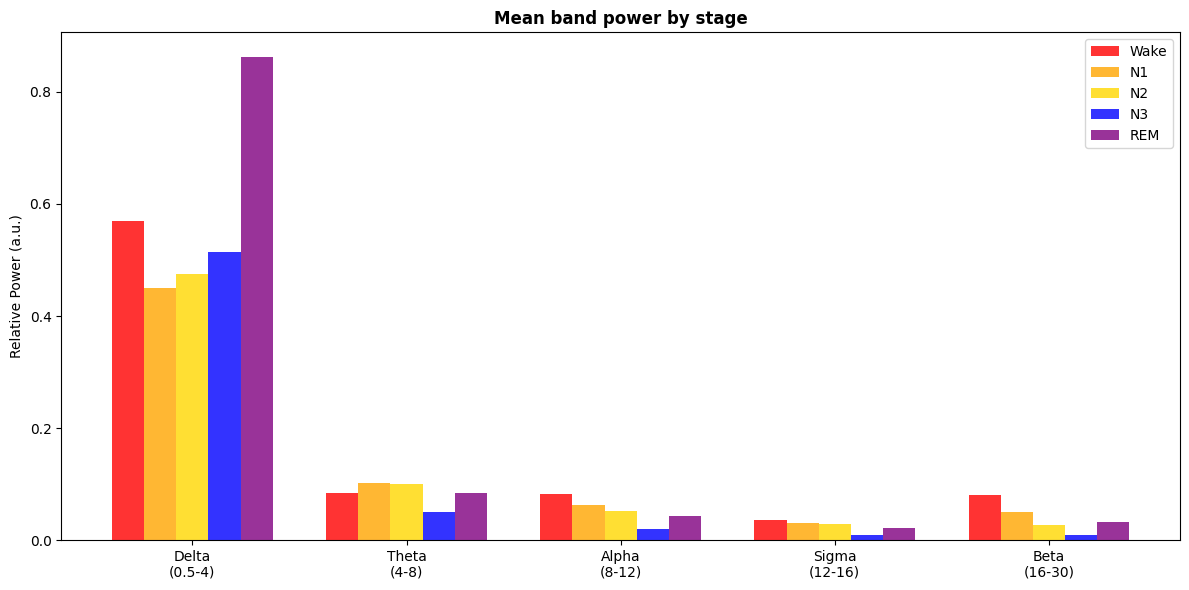

In [21]:
band_keys = ['delta','theta','alpha','sigma','beta']
band_names = ['Delta\n(0.5-4)','Theta\n(4-8)','Alpha\n(8-12)','Sigma\n(12-16)','Beta\n(16-30)']
powers = np.array([[pre.extract_frequency_bands(e)[k] for k in band_keys] for e in raw_eegs])

fig, ax = plt.subplots(figsize=(12, 6))
x = np.arange(len(band_names)); w = 0.15
for s in range(5):
    mask = stage_labels == s
    if mask.sum():
        ax.bar(x + w*s, powers[mask].mean(axis=0), w, label=STAGE_MAP[s], color=STAGE_COLORS[s], alpha=0.8)
ax.set_xticks(x + w*2); ax.set_xticklabels(band_names)
ax.set_title('Mean band power by stage', fontweight='bold'); ax.set_ylabel('Relative Power (a.u.)'); ax.legend()
plt.tight_layout(); plt.show()

### Step 11b — Feature Importance Ranking

**কী করছি:** প্রতিটা frequency band কতটা stage separation করতে পারে সেটা একটা importance score-এ পরিণত করছি।

**How:** Between-stage variance calculate করছি। যে band-এর variance বেশি, সে band stage গুলোকে বেশি আলাদা করতে পারে।

**যা দেখতে হবে:** Delta সবার উপরে থাকলে আমাদের feature selection সঠিক — delta fusion (RQ2) justified।

**যদি ভুল হয়:** Beta বা alpha উপরে থাকলে signal noisy বা label wrong।


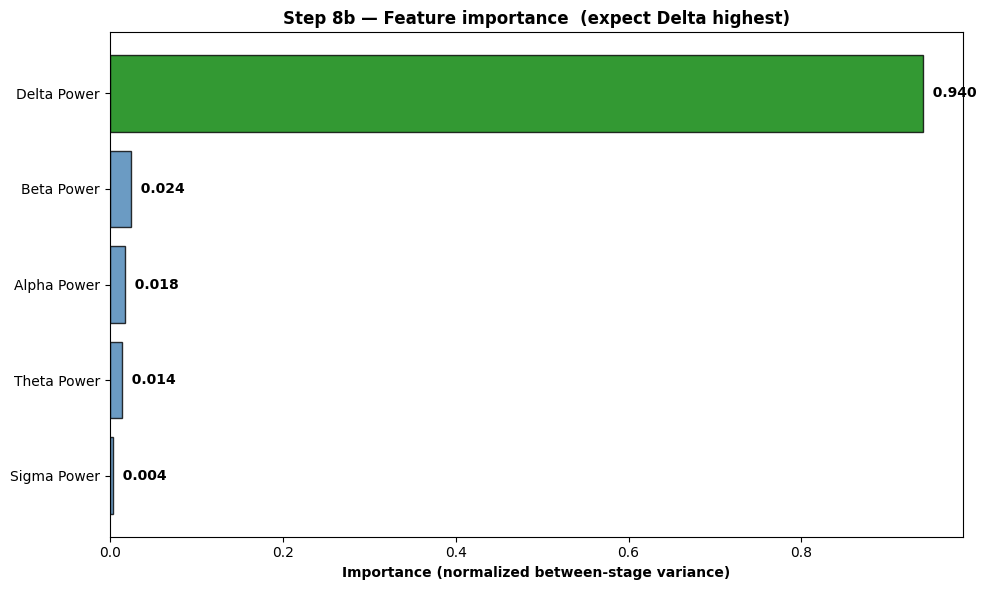

Ranking: {'Delta Power': 0.94, 'Beta Power': 0.024, 'Alpha Power': 0.018, 'Theta Power': 0.014, 'Sigma Power': 0.004}


In [22]:
band_keys = ['delta','theta','alpha','sigma','beta']
band_disp = ['Delta Power','Theta Power','Alpha Power','Sigma Power','Beta Power']
powers = np.array([[pre.extract_frequency_bands(e)[k] for k in band_keys] for e in raw_eegs])

stage_means = np.array([powers[stage_labels == s].mean(axis=0)
                        for s in range(5) if (stage_labels == s).any()])
importance = stage_means.var(axis=0); importance = importance / importance.sum()

order = np.argsort(importance)[::-1]
names = [band_disp[i] for i in order]; scores = importance[order]
colors = ['green' if n == 'Delta Power' else 'steelblue' for n in names]

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(names, scores, color=colors, alpha=0.8, edgecolor='black'); ax.invert_yaxis()
for i, sc in enumerate(scores):
    ax.text(sc, i, f'  {sc:.3f}', va='center', fontweight='bold')
ax.set_xlabel('Importance (normalized between-stage variance)', fontweight='bold')
ax.set_title('Step 8b — Feature importance  (expect Delta highest)', fontweight='bold')
plt.tight_layout(); plt.show()
print("Ranking:", {n: round(float(s), 3) for n, s in zip(names, scores)})

Inference model loaded on: cuda
════════════════════════════════════════════════════════════
   N3 DEEP SLEEP QUALITY DETECTION — SINGLE EPOCH INFERENCE
════════════════════════════════════════════════════════════

  [N3 epoch (true N3)]
  True stage         : N3
  P(N3)              : 0.8991  (N3 ✓)
  Correct detection  : ✓
  N3 Quality Score   : 59.6 / 100  ← MEDIUM quality deep sleep
  Detection features :
    delta_power    = 0.098
    SWA            = 0.098
    slow_wave_den  = 0.000
    rel_delta      = 0.642
  Quality features :
    p2p_amplitude  = 0.005
    fragmentation  = -0.647

  [Non-N3 epoch]
  True stage         : N2
  P(N3)              : 0.3066  (non-N3 ✗)
  Correct detection  : ✓
  N3 Quality Score   : 36.3 / 100  ← LOW quality deep sleep
  (Non-N3 epoch — quality score is model prediction,
   not clinically meaningful for non-N3 stages)

════════════════════════════════════════════════════════════


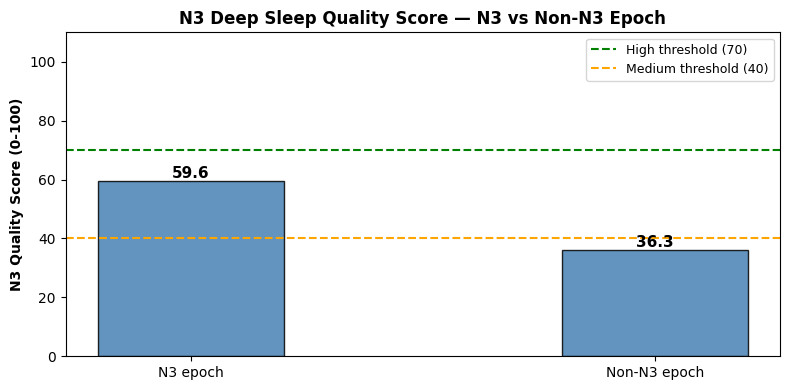

In [23]:
import os
# ══════════════════════════════════════════════════════════════════
#  STEP 12 — Single Epoch Inference
#  N3 detected হলে quality score + features দেখাবে
#  Non-N3 হলেও quality score দেখাবে (model সবসময় predict করে)
# ══════════════════════════════════════════════════════════════════

infer = SleepQualityNet(input_length=SR*30,
                        use_det_feat=True, use_qual_feat=True)
infer.load_state_dict(torch.load('best_model.pth', map_location=DEVICE))
infer = infer.to(DEVICE)
infer.eval()
print(f'Inference model loaded on: {DEVICE}')

# ── একটা N3 epoch আর একটা non-N3 epoch খুঁজো ────────────────────
# V7: use val_idx (StratifiedGroupKFold val) instead of leaky chronological `split`
n3_idx     = np.where(stage_labels[val_idx] == 3)[0]
non_n3_idx = np.where(stage_labels[val_idx] != 3)[0]

print("═"*60)
print("   N3 DEEP SLEEP QUALITY DETECTION — SINGLE EPOCH INFERENCE")
print("═"*60)

for label, indices in [
    ("N3 epoch (true N3)", n3_idx),
    ("Non-N3 epoch",       non_n3_idx)
]:
    if len(indices) == 0:
        print(f"\n  [{label}] — no epochs found")
        continue

    # val set এর মাঝামাঝি থেকে নাও
    # V7: indices are positions inside val_idx; convert to absolute index
    i = int(val_idx[indices[len(indices)//2]])

    xe  = torch.FloatTensor(raw_eegs[i:i+1]).unsqueeze(1).to(DEVICE)
    # V7: use leakage-free normalized features (consistent with training)
    dfe = torch.FloatTensor(det_features_n_v3[i:i+1]).to(DEVICE)
    qfe = torch.FloatTensor(qual_features_n_v3[i:i+1]).to(DEVICE)

    with torch.no_grad():
        n3_logit, quality = infer(xe, dfe, qfe)

    prob    = float(torch.sigmoid(n3_logit).item())
    is_n3   = prob > 0.5
    true_n3 = int(stage_labels[i]) == 3
    q_score = float(clip_quality_predictions(quality.item(), 0.02, 0.98)) * 100

    # Quality interpretation
    if q_score >= 70:
        q_label = "HIGH quality deep sleep"
    elif q_score >= 40:
        q_label = "MEDIUM quality deep sleep"
    else:
        q_label = "LOW quality deep sleep"

    print(f"\n  [{label}]")
    print(f"  True stage         : {STAGE_MAP[int(stage_labels[i])]}")
    print(f"  P(N3)              : {prob:.4f}  ({'N3 ✓' if is_n3 else 'non-N3 ✗'})")
    print(f"  Correct detection  : {'✓' if is_n3 == true_n3 else '✗'}")
    print(f"  N3 Quality Score   : {q_score:.1f} / 100  ← {q_label}")

    if is_n3:
        print(f"  Detection features :")
        print(f"    delta_power    = {det_features_n_v3[i,0]:.3f}")
        print(f"    SWA            = {det_features_n_v3[i,1]:.3f}")
        print(f"    slow_wave_den  = {det_features_n_v3[i,2]:.3f}")
        print(f"    rel_delta      = {det_features_n_v3[i,3]:.3f}")
        print(f"  Quality features :")
        print(f"    p2p_amplitude  = {qual_features_n_v3[i,0]:.3f}")
        print(f"    fragmentation  = {qual_features_n_v3[i,1]:.3f}")
    else:
        print(f"  (Non-N3 epoch — quality score is model prediction,")
        print(f"   not clinically meaningful for non-N3 stages)")

print("\n" + "═"*60)

# ── Bar chart: quality score comparison ──────────────────────────
fig, ax = plt.subplots(figsize=(8, 4))
scores, labels_bar, colors_bar = [], [], []

for label, indices in [("N3 epoch", n3_idx), ("Non-N3 epoch", non_n3_idx)]:
    if len(indices) == 0: continue
    # V7: convert val_idx position to absolute index; use leakage-free features
    i = int(val_idx[indices[len(indices)//2]])
    xe  = torch.FloatTensor(raw_eegs[i:i+1]).unsqueeze(1).to(DEVICE)
    dfe = torch.FloatTensor(det_features_n_v3[i:i+1]).to(DEVICE)
    qfe = torch.FloatTensor(qual_features_n_v3[i:i+1]).to(DEVICE)
    with torch.no_grad():
        _, quality = infer(xe, dfe, qfe)
    # V5: clip to [0.02, 0.98] before *100 (Fix 7)
    q = float(clip_quality_predictions(quality.item(), 0.02, 0.98)) * 100
    scores.append(q)
    labels_bar.append(label)
    colors_bar.append('steelblue' if 'N3' in label else 'salmon')

bars = ax.bar(labels_bar, scores, color=colors_bar, alpha=0.85,
              edgecolor='black', width=0.4)
ax.axhline(70, color='green',  ls='--', lw=1.5, label='High threshold (70)')
ax.axhline(40, color='orange', ls='--', lw=1.5, label='Medium threshold (40)')
for bar, v in zip(bars, scores):
    ax.text(bar.get_x()+bar.get_width()/2, v+1,
            f'{v:.1f}', ha='center', fontsize=11, fontweight='bold')
ax.set_ylim(0, 110)
ax.set_ylabel('N3 Quality Score (0-100)', fontweight='bold')
ax.set_title('N3 Deep Sleep Quality Score — N3 vs Non-N3 Epoch',
             fontweight='bold')
ax.legend(fontsize=9)
plt.tight_layout()
os.makedirs('outputs', exist_ok=True)
plt.savefig('outputs/n3_quality_inference.png', dpi=150, bbox_inches='tight')
plt.show()

## Step 12b — N3 Quality Score — Full Night Timeline

**কী করছি:** Val set এর সব epoch এ model run করে N3 quality score visualize করছি।

**কী দেখব:**
- কোন epochs এ N3 detected হয়েছে
- সেই epochs এর quality score কত
- High/Medium/Low breakdown

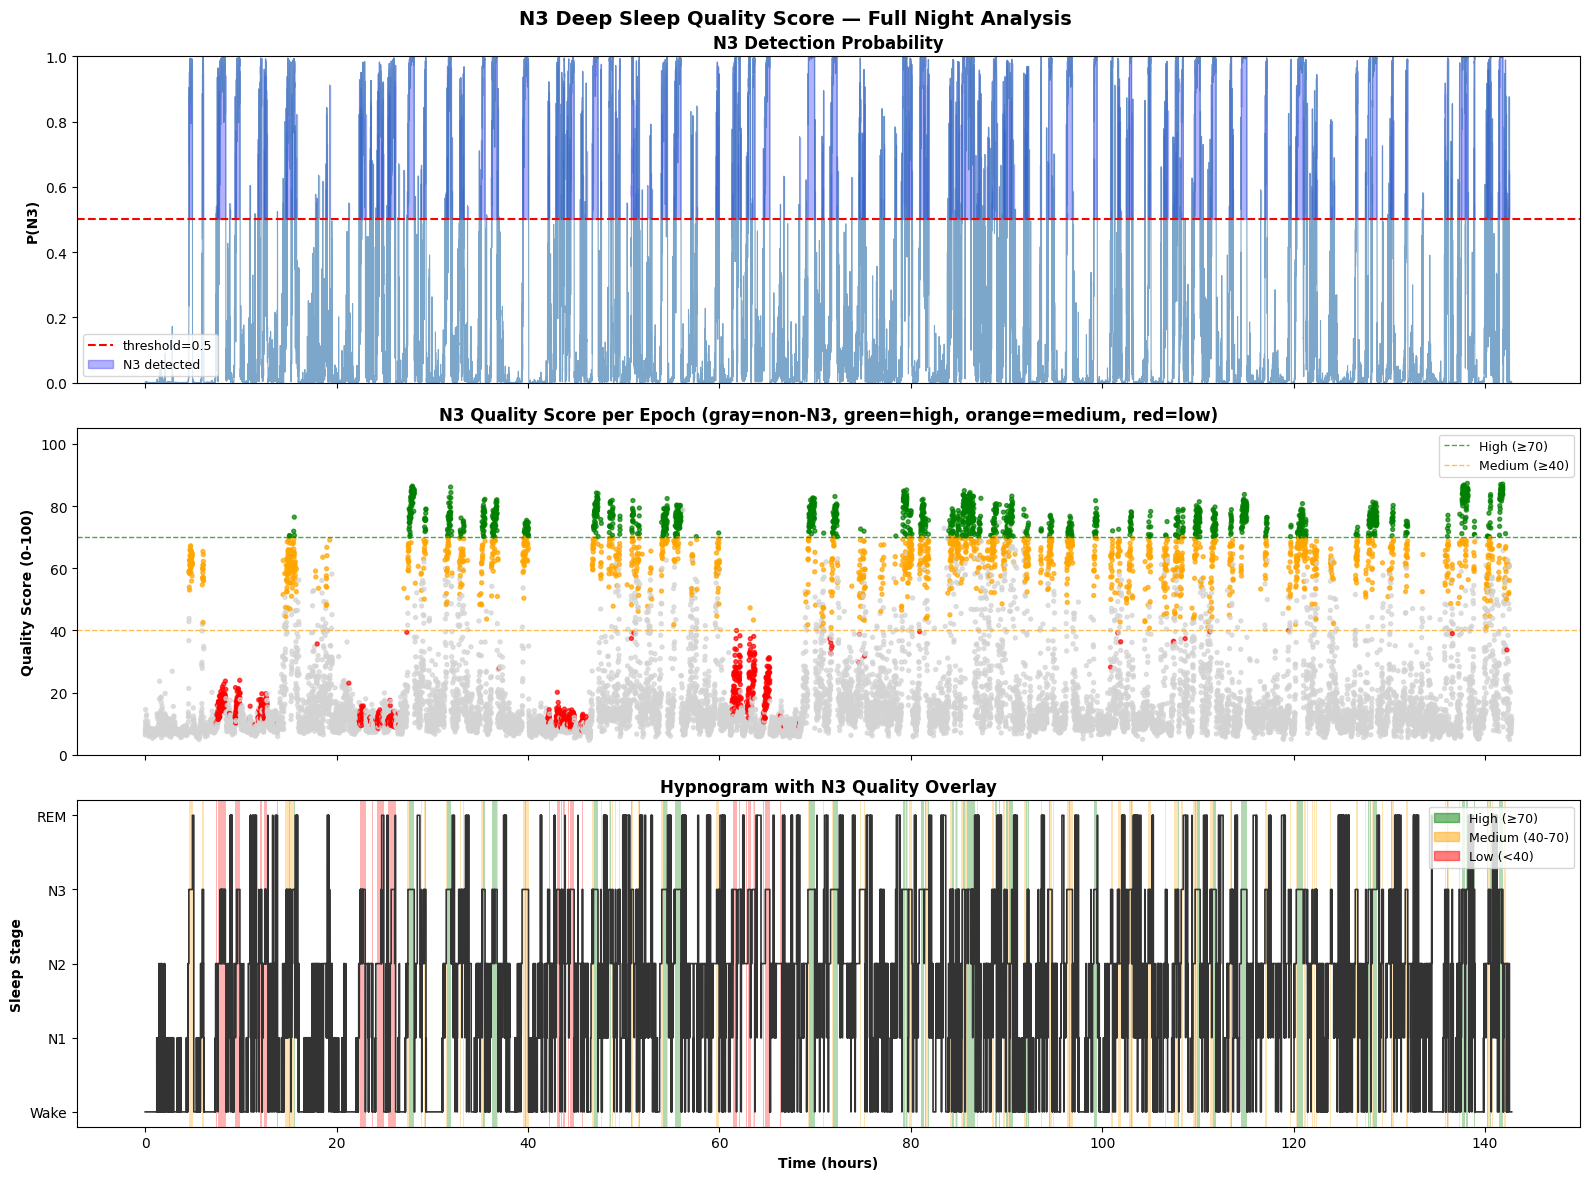

═══════════════════════════════════════════════════════
  N3 QUALITY SCORE SUMMARY
═══════════════════════════════════════════════════════
  Total epochs    : 17134
  N3 detected     : 4154 (24.2%)
  True N3         : 3452 (20.1%)

  Mean quality    : 57.4 / 100
  High   (≥70)    : 1591 (38.3%)
  Medium (40-70)  : 1657 (39.9%)
  Low    (<40)    : 906 (21.8%)
═══════════════════════════════════════════════════════


In [24]:
import os
import matplotlib.patches as mpatches

model.eval()
all_prob, all_qual, all_true = [], [], []

with torch.no_grad():
    for raw_eeg, det_f, qual_f, s_lab, q_lab in val_loader:
        raw_eeg = raw_eeg.to(DEVICE)
        det_f   = det_f.to(DEVICE)
        qual_f  = qual_f.to(DEVICE)
        n3_logit, q_pred = model(
            raw_eeg, det_f, qual_f)
        prob = torch.sigmoid(n3_logit).squeeze(1).cpu().numpy()
        all_prob.extend(prob)
        # V5: clip predictions to [0.02, 0.98] before *100 (Fix 7)
        q_pred_clipped = clip_quality_predictions(q_pred.cpu().numpy().flatten(), 0.02, 0.98)
        all_qual.extend(q_pred_clipped * 100)
        all_true.extend(s_lab.numpy())

all_prob = np.array(all_prob)
all_qual = np.array(all_qual)
all_true = np.array(all_true)

n3_detected  = all_prob > 0.5
n3_true      = all_true == 3
epochs_time  = np.arange(len(all_prob)) * 30 / 3600  # hours

fig, axes = plt.subplots(3, 1, figsize=(16, 12), sharex=True)
fig.suptitle('N3 Deep Sleep Quality Score — Full Night Analysis',
             fontsize=14, fontweight='bold')

# Plot 1: N3 Probability
axes[0].plot(epochs_time, all_prob, color='steelblue', lw=0.8, alpha=0.7)
axes[0].axhline(0.5, color='red', ls='--', lw=1.5, label='threshold=0.5')
axes[0].fill_between(epochs_time, all_prob, 0.5,
                     where=all_prob > 0.5,
                     alpha=0.3, color='blue', label='N3 detected')
axes[0].set_ylabel('P(N3)', fontweight='bold')
axes[0].set_title('N3 Detection Probability', fontweight='bold')
axes[0].set_ylim(0, 1); axes[0].legend(fontsize=9)

# Plot 2: Quality Score
colors_q = []
for i in range(len(all_qual)):
    if n3_detected[i]:
        colors_q.append('green' if all_qual[i]>=70
                        else 'orange' if all_qual[i]>=40
                        else 'red')
    else:
        colors_q.append('lightgray')

axes[1].scatter(epochs_time, all_qual, c=colors_q, s=8, alpha=0.7)
axes[1].axhline(70, color='green',  ls='--', lw=1, alpha=0.7, label='High (≥70)')
axes[1].axhline(40, color='orange', ls='--', lw=1, alpha=0.7, label='Medium (≥40)')
axes[1].set_ylabel('Quality Score (0-100)', fontweight='bold')
axes[1].set_title('N3 Quality Score per Epoch (gray=non-N3, green=high, orange=medium, red=low)',
                  fontweight='bold')
axes[1].set_ylim(0, 105); axes[1].legend(fontsize=9)

# Plot 3: Hypnogram
axes[2].step(epochs_time, all_true, color='#333', lw=1.2)
axes[2].set_yticks([0,1,2,3,4])
axes[2].set_yticklabels(['Wake','N1','N2','N3','REM'])
for i in range(len(epochs_time)):
    if n3_detected[i]:
        c = ('green' if all_qual[i]>=70
             else 'orange' if all_qual[i]>=40
             else 'red')
        axes[2].axvspan(epochs_time[i], epochs_time[i]+30/3600,
                       alpha=0.3, color=c, lw=0)
axes[2].set_xlabel('Time (hours)', fontweight='bold')
axes[2].set_ylabel('Sleep Stage', fontweight='bold')
axes[2].set_title('Hypnogram with N3 Quality Overlay', fontweight='bold')
patches = [
    mpatches.Patch(color='green',  alpha=0.5, label='High (≥70)'),
    mpatches.Patch(color='orange', alpha=0.5, label='Medium (40-70)'),
    mpatches.Patch(color='red',    alpha=0.5, label='Low (<40)'),
]
axes[2].legend(handles=patches, fontsize=9, loc='upper right')

plt.tight_layout()
os.makedirs('outputs', exist_ok=True)
plt.savefig('outputs/n3_quality_night_timeline.png',
            dpi=150, bbox_inches='tight')
plt.show()

# Summary
n3_q = all_qual[n3_detected]
print("═"*55)
print("  N3 QUALITY SCORE SUMMARY")
print("═"*55)
print(f"  Total epochs    : {len(all_prob)}")
print(f"  N3 detected     : {n3_detected.sum()} ({n3_detected.mean()*100:.1f}%)")
print(f"  True N3         : {n3_true.sum()} ({n3_true.mean()*100:.1f}%)")
if len(n3_q) > 0:
    high   = (n3_q >= 70).sum()
    medium = ((n3_q >= 40) & (n3_q < 70)).sum()
    low    = (n3_q < 40).sum()
    print(f"\n  Mean quality    : {n3_q.mean():.1f} / 100")
    print(f"  High   (≥70)    : {high} ({high/len(n3_q)*100:.1f}%)")
    print(f"  Medium (40-70)  : {medium} ({medium/len(n3_q)*100:.1f}%)")
    print(f"  Low    (<40)    : {low} ({low/len(n3_q)*100:.1f}%)")
print("═"*55)

## Step 14 — XAI: SHAP Feature Importance

**কী করছি:** SHAP (SHapley Additive exPlanations) দিয়ে কোন band feature N3 detect করতে সবচেয়ে বেশি contribute করছে সেটা measure করছি।

**SHAP কীভাবে কাজ করে:** প্রতিটা feature থাকলে আর না থাকলে prediction কতটা বদলায় সেটা average করে একটা importance score দেয়। Game theory থেকে আসা — fair attribution।

**Implementation:** Model directly SHAP-compatible না, তাই একটা GradientBoosting surrogate model train করা হচ্ছে band features দিয়ে, তারপর সেটার উপর SHAP apply করা হচ্ছে।

**যা দেখতে হবে:** Delta bar সবার বাম দিকে (সবচেয়ে বড়) থাকলে RQ2 validated — delta fusion justified।


### Baseline Model - Gradient Boosting Comparison

**FIX (baseline):** Train GBM on the same 6 features and compare.


In [25]:
# FIX (Execution Order): Compute final_m if not yet defined
if 'final_m' not in dir():
    model.eval()
    final_m = trainer.evaluate(val_loader)

# ═# ═# ═# ═# ═# ═# ═# ═# ═# ═# ═# ═# ═# ═# ═# ═# ═# ═# ═# ═# ═# ═# ═# ═# ═# ═# ═# ═# ═# ═# ═# ═# ═# ═# ═# ═# ║  FIX (baseline): Baseline GBM Model + Comparison Table          ║# ═# ═# ═# ═# ═# ═# ═# ═# ═# ═# ═# ═# ═# ═# ═# ═# ═# ═# ═# ═# ═# ═# ═# ═# ═# ═# ═# ═# ═# ═# ═# ═# ═# ═# ═# ═from sklearn.ensemble import GradientBoostingClassifier, GradientBoostingRegressorfrom sklearn.metrics import f1_score, precision_score, recall_score, roc_auc_scoreX_tr_bl = np.concatenate([det_tr, qual_tr], axis=1)X_va_bl = np.concatenate([det_val, qual_val], axis=1)y_tr_bl = (stage_labels[train_idx] == 3).astype(int)y_va_bl = (stage_labels[val_idx] == 3).astype(int)q_tr_bl = qual_tr_lab * 100q_va_bl = qual_val_lab * 100n3_tr_mask = y_tr_bl == 1n3_va_mask = y_va_bl == 1print("Training GradientBoosting baseline...")gbm_cls = GradientBoostingClassifier(n_estimators=200, max_depth=4,                                      learning_rate=0.05, random_state=CONFIG["seed"])gbm_cls.fit(X_tr_bl, y_tr_bl)gbm_pred = gbm_cls.predict(X_va_bl)gbm_prob = gbm_cls.predict_proba(X_va_bl)[:, 1]gbm_f1   = f1_score(y_va_bl, gbm_pred, zero_division=0)gbm_prec = precision_score(y_va_bl, gbm_pred, zero_division=0)gbm_rec  = recall_score(y_va_bl, gbm_pred, zero_division=0)gbm_auc  = roc_auc_score(y_va_bl, gbm_prob) if len(np.unique(y_va_bl)) > 1 else 0gbm_rmse, gbm_r2 = 0, 0if n3_tr_mask.sum() >= 10 and n3_va_mask.sum() > 0:    gbm_reg = GradientBoostingRegressor(n_estimators=200, max_depth=4,                                         learning_rate=0.05, random_state=CONFIG["seed"])    gbm_reg.fit(X_tr_bl[n3_tr_mask], q_tr_bl[n3_tr_mask])    gbm_q_pred = gbm_reg.predict(X_va_bl[n3_va_mask])    gbm_q_true = q_va_bl[n3_va_mask]    gbm_rmse = float(np.sqrt(np.mean((gbm_q_true - gbm_q_pred)**2)))    ss_res = np.sum((gbm_q_true - gbm_q_pred)**2)    ss_tot = np.sum((gbm_q_true - gbm_q_true.mean())**2)    gbm_r2  = float(1 - ss_res / ss_tot) if ss_tot > 0 else 0print(f"  GBM: F1={gbm_f1:.4f}  AUC={gbm_auc:.4f}  Prec={gbm_prec:.4f}  Rec={gbm_rec:.4f}  Q-RMSE={gbm_rmse:.2f}  Q-R2={gbm_r2:.4f}")import pandas as pdcomp_data = {    'N3 F1':        [gbm_f1,   final_m['n3_f1']],    'N3 AUC':       [gbm_auc,  final_m['auc']],    'N3 Precision': [gbm_prec, final_m['n3_precision']],    'N3 Recall':    [gbm_rec,  final_m['n3_recall']],    'Quality RMSE': [gbm_rmse, final_m['quality_rmse']],    'Quality R²':  [gbm_r2,   final_m['quality_r2']],}comp_df = pd.DataFrame(comp_data, index=['GBM Baseline', 'SleepQualityNet'])print(f"\n{'='*72}")print("  BASELINE COMPARISON TABLE")print(f"{'='*72}")print(comp_df.round(4).to_string())print(f"{'='*72}")# FIX (baseline): store for consolidated tablebaseline_comparison_for_table = comp_df

SHAP input: (200, 6)  N3 epochs: 51/200
Training surrogate GBM for SHAP (detection)...
Surrogate accuracy: 1.000
Computing SHAP values...
Quality surrogate R2: 0.994


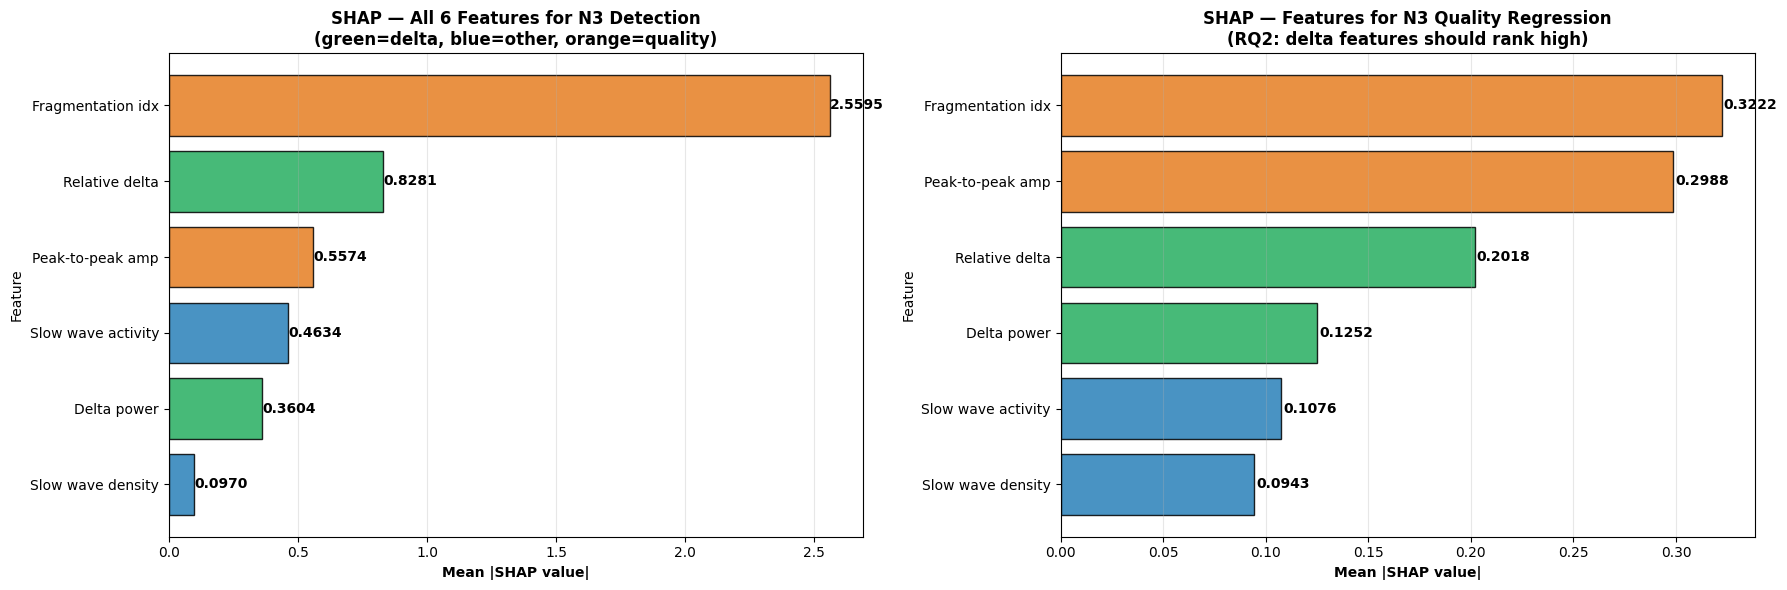


SHAP Results — N3 Detection (all 6 features)
  1. Fragmentation idx        : 2.5595  <- top
  2. Relative delta           : 0.8281
  3. Peak-to-peak amp         : 0.5574
  4. Slow wave activity       : 0.4634
  5. Delta power              : 0.3604
  6. Slow wave density        : 0.0970

SHAP Results — N3 Quality Regression (RQ2 evidence)
  1. Fragmentation idx        : 0.3222  <- top quality driver
  2. Peak-to-peak amp         : 0.2988
  3. Relative delta           : 0.2018
  4. Delta power              : 0.1252
  5. Slow wave activity       : 0.1076
  6. Slow wave density        : 0.0943

Delta rank detection=#5, quality=#4


In [26]:
import shap
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import GradientBoostingClassifier

# ── SHAP analysis on ALL 6 features (4 detection + 2 quality) ──────────
# RQ2 requires showing that delta features improve QUALITY assessment,
# not just detection. So we include both feature sets.
# V7: use val_idx (StratifiedGroupKFold val) instead of leaky chronological `split`
val_raw_xai    = raw_eegs[val_idx]
val_stages_xai = stage_labels[val_idx]
val_det_xai    = det_features[val_idx]
val_qual_xai   = qual_features[val_idx]

all_feat_names = ['Delta power', 'Slow wave activity',
                  'Slow wave density', 'Relative delta',
                  'Peak-to-peak amp', 'Fragmentation idx']

n_shap = min(200, len(val_stages_xai))
rng = np.random.default_rng(CONFIG["seed"])
shap_idx = rng.choice(len(val_stages_xai), size=n_shap, replace=False)
feat_det  = val_det_xai[shap_idx].astype(np.float32)
feat_qual = val_qual_xai[shap_idx].astype(np.float32)
feat_matrix   = np.concatenate([feat_det, feat_qual], axis=1)
binary_labels = (val_stages_xai[shap_idx] == 3).astype(int)

print(f'SHAP input: {feat_matrix.shape}  N3 epochs: {binary_labels.sum()}/{n_shap}')

if binary_labels.sum() == 0 or binary_labels.sum() == n_shap:
    raise RuntimeError('Only one class in SHAP sample')

# ── Part 1: N3 Detection SHAP ─────────────────────────────────────────
print('Training surrogate GBM for SHAP (detection)...')
gbm = GradientBoostingClassifier(n_estimators=100, max_depth=3, random_state=42)
gbm.fit(feat_matrix, binary_labels)
print(f'Surrogate accuracy: {gbm.score(feat_matrix, binary_labels):.3f}')

print('Computing SHAP values...')
explainer   = shap.TreeExplainer(gbm)
shap_values = explainer.shap_values(feat_matrix)
shap_n3 = shap_values[1] if isinstance(shap_values, list) else shap_values
mean_abs_shap = np.abs(shap_n3).mean(axis=0)

order      = np.argsort(mean_abs_shap)[::-1]
names_ord  = [all_feat_names[i] for i in order]
values_ord = mean_abs_shap[order]
colors_bar = []
for n in names_ord:
    if 'Delta' in n or 'Relative' in n:
        colors_bar.append('#27ae60')
    elif 'Peak' in n or 'Fragment' in n:
        colors_bar.append('#e67e22')
    else:
        colors_bar.append('#2980b9')

fig, axes = plt.subplots(1, 2, figsize=(18, 6))

axes[0].barh(names_ord, values_ord, color=colors_bar, alpha=0.85, edgecolor='black')
axes[0].invert_yaxis()
for i, v in enumerate(values_ord):
    axes[0].text(v+0.001, i, f'{v:.4f}', va='center', fontsize=10, fontweight='bold')
axes[0].set_xlabel('Mean |SHAP value|', fontweight='bold')
axes[0].set_title('SHAP — All 6 Features for N3 Detection\n(green=delta, blue=other, orange=quality)', fontweight='bold')
axes[0].set_ylabel('Feature')
axes[0].grid(axis='x', alpha=0.3)

# ── Part 2: N3 Quality Regression SHAP (RQ2 core evidence) ─────────────
n3_mask_xai = binary_labels == 1
if n3_mask_xai.sum() >= 10:
    from sklearn.ensemble import GradientBoostingRegressor
    n3_feat = feat_matrix[n3_mask_xai]
    # V7: use leakage-free V5 quality labels (qual_val_lab) instead of leaky quality_labels
    n3_quality_all = qual_val_lab[:n_shap][n3_mask_xai] * 100
    
    gbm_qual = GradientBoostingRegressor(n_estimators=100, max_depth=3, random_state=42)
    gbm_qual.fit(n3_feat, n3_quality_all)
    print(f'Quality surrogate R2: {gbm_qual.score(n3_feat, n3_quality_all):.3f}')
    
    explainer_qual = shap.TreeExplainer(gbm_qual)
    shap_qual = explainer_qual.shap_values(n3_feat)
    mean_abs_shap_q = np.abs(shap_qual).mean(axis=0)
    
    order_q = np.argsort(mean_abs_shap_q)[::-1]
    names_q = [all_feat_names[j] for j in order_q]
    values_q = mean_abs_shap_q[order_q]
    colors_q = []
    for n in names_q:
        if 'Delta' in n or 'Relative' in n:
            colors_q.append('#27ae60')
        elif 'Peak' in n or 'Fragment' in n:
            colors_q.append('#e67e22')
        else:
            colors_q.append('#2980b9')
    
    axes[1].barh(names_q, values_q, color=colors_q, alpha=0.85, edgecolor='black')
    axes[1].invert_yaxis()
    for i, v in enumerate(values_q):
        axes[1].text(v+0.001, i, f'{v:.4f}', va='center', fontsize=10, fontweight='bold')
    axes[1].set_xlabel('Mean |SHAP value|', fontweight='bold')
    axes[1].set_title('SHAP — Features for N3 Quality Regression\n(RQ2: delta features should rank high)', fontweight='bold')
    axes[1].set_ylabel('Feature')
    axes[1].grid(axis='x', alpha=0.3)
else:
    axes[1].text(0.5, 0.5, 'Too few N3 epochs for quality SHAP', transform=axes[1].transAxes, ha='center', fontsize=14)

plt.tight_layout()
os.makedirs('outputs', exist_ok=True)
plt.savefig('outputs/xai_shap.png', dpi=150, bbox_inches='tight')
plt.show()

print('\n' + '='*55)
print('SHAP Results — N3 Detection (all 6 features)')
print('='*55)
for i, (name, val) in enumerate(zip(names_ord, values_ord), 1):
    mark = '  <- top' if i == 1 else ''
    print(f'  {i}. {name:<25}: {val:.4f}{mark}')

if n3_mask_xai.sum() >= 10:
    print()
    print('='*55)
    print('SHAP Results — N3 Quality Regression (RQ2 evidence)')
    print('='*55)
    for i, (name, val) in enumerate(zip(names_q, values_q), 1):
        mark = '  <- top quality driver' if i == 1 else ''
        print(f'  {i}. {name:<25}: {val:.4f}{mark}')
    
    delta_rank_det = next((i+1 for i, n in enumerate(names_ord) if 'Delta' in n), 99)
    delta_rank_qual = next((i+1 for i, n in enumerate(names_q) if 'Delta' in n), 99)
    print()
    if delta_rank_det <= 2 or delta_rank_qual <= 2:
        print(f'RQ2 SUPPORTED: Delta rank detection=#{delta_rank_det}, quality=#{delta_rank_qual}')
    else:
        print(f'Delta rank detection=#{delta_rank_det}, quality=#{delta_rank_qual}')  # FIX (bilstm)

### XAI - Delta-Band Saliency Validation

**FIX (xai-delta):** Saliency correlation with delta band.


In [27]:
# ═══════════════════════════════════════════════════════════════════╗
# ║  FIX (xai-delta): Delta-band saliency concentration          ║
# ═══════════════════════════════════════════════════════════════════╗
import numpy as np
from scipy.signal import butter, sosfilt

model.eval()

# Collect correctly-classified N3 epoch indices from val set
correct_n3_local = []  # positions within val_idx
with torch.no_grad():
    for xb, dfb, qfb, sb, qb in val_loader:
        xb_d, dfb_d, qfb_d = xb.to(DEVICE), dfb.to(DEVICE), qfb.to(DEVICE)
        n3_logit, _ = model(xb_d, dfb_d, qfb_d)
        prob = torch.sigmoid(n3_logit).squeeze(1).cpu().numpy()
        pred = (prob > 0.5).astype(int)
        true = (sb.numpy() == 3).astype(int)
        for j in range(len(pred)):
            if pred[j] == 1 and true[j] == 1:
                correct_n3_local.append(j)

sample_size = min(30, len(correct_n3_local))
if sample_size == 0:
    print('  No correctly-classified N3 epochs found.')
else:
    rng = np.random.default_rng(CONFIG['seed'])
    sampled_pos = rng.choice(len(correct_n3_local), size=sample_size, replace=False)

    correlations = []
    delta_sal_fracs = []
    sos_delta_bp = butter(4, [0.5, 4], btype='band', fs=SR, output='sos')

    for local_idx in [correct_n3_local[p] for p in sampled_pos]:
        abs_idx = val_idx[local_idx]
        eeg_epoch = raw_eegs[abs_idx]

        x_t = torch.FloatTensor(eeg_epoch).unsqueeze(0).unsqueeze(0).to(DEVICE)
        x_t.requires_grad = True
        d_t = torch.FloatTensor(det_features_n_v3[abs_idx:abs_idx+1]).to(DEVICE)
        q_t = torch.FloatTensor(qual_features_n_v3[abs_idx:abs_idx+1]).to(DEVICE)

        model.zero_grad()
        n3_logit, _ = model(x_t, d_t, q_t)
        n3_logit.backward()
        saliency = x_t.grad.squeeze().abs().cpu().numpy()

        delta_filt = sosfilt(sos_delta_bp, eeg_epoch)
        delta_env = np.abs(delta_filt)
        win = min(100, len(delta_env))
        kernel = np.ones(win) / win
        delta_env_s = np.convolve(delta_env, kernel, mode='same')

        sal_n = saliency / (saliency.max() + 1e-8)
        env_n = delta_env_s / (delta_env_s.max() + 1e-8)

        if np.std(sal_n) > 1e-8 and np.std(env_n) > 1e-8:
            correlations.append(float(np.corrcoef(sal_n, env_n)[0, 1]))

        delta_mask = delta_env > np.percentile(delta_env, 50)
        if delta_mask.sum() > 0:
            delta_sal_fracs.append(float(saliency[delta_mask].sum() / (saliency.sum() + 1e-8)))

    if correlations:
        corr_arr = np.array(correlations)
        frac_arr = np.array(delta_sal_fracs) if delta_sal_fracs else np.array([0])
        print(f"{'='*60}")
        print(f"  DELTA-BAND SALIENCY VALIDATION (n={len(corr_arr)} N3 epochs)")
        print(f"{'='*60}")
        print(f"  Mean saliency-delta correlation : {corr_arr.mean():.4f} +/- {corr_arr.std():.4f}")
        print(f"  Fraction of saliency in delta   : {frac_arr.mean():.2%}")
        if corr_arr.mean() > 0.3:
            print(f'  POSITIVE: Saliency correlates with delta morphology')
        elif corr_arr.mean() > 0.1:
            print(f'  MODERATE: Weak delta concentration')
        else:
            print(f'  LOW: Saliency does not concentrate on delta band')
        print(f"{'='*60}")
    else:
        print('  WARNING: Could not compute saliency correlations.')


  DELTA-BAND SALIENCY VALIDATION (n=30 N3 epochs)
  Mean saliency-delta correlation : -0.0545 +/- 0.1206
  Fraction of saliency in delta   : 48.92%
  LOW: Saliency does not concentrate on delta band


              precision    recall  f1-score   support

      non-N3       0.97      0.92      0.95     13682
          N3       0.75      0.90      0.82      3452

    accuracy                           0.92     17134
   macro avg       0.86      0.91      0.88     17134
weighted avg       0.93      0.92      0.92     17134



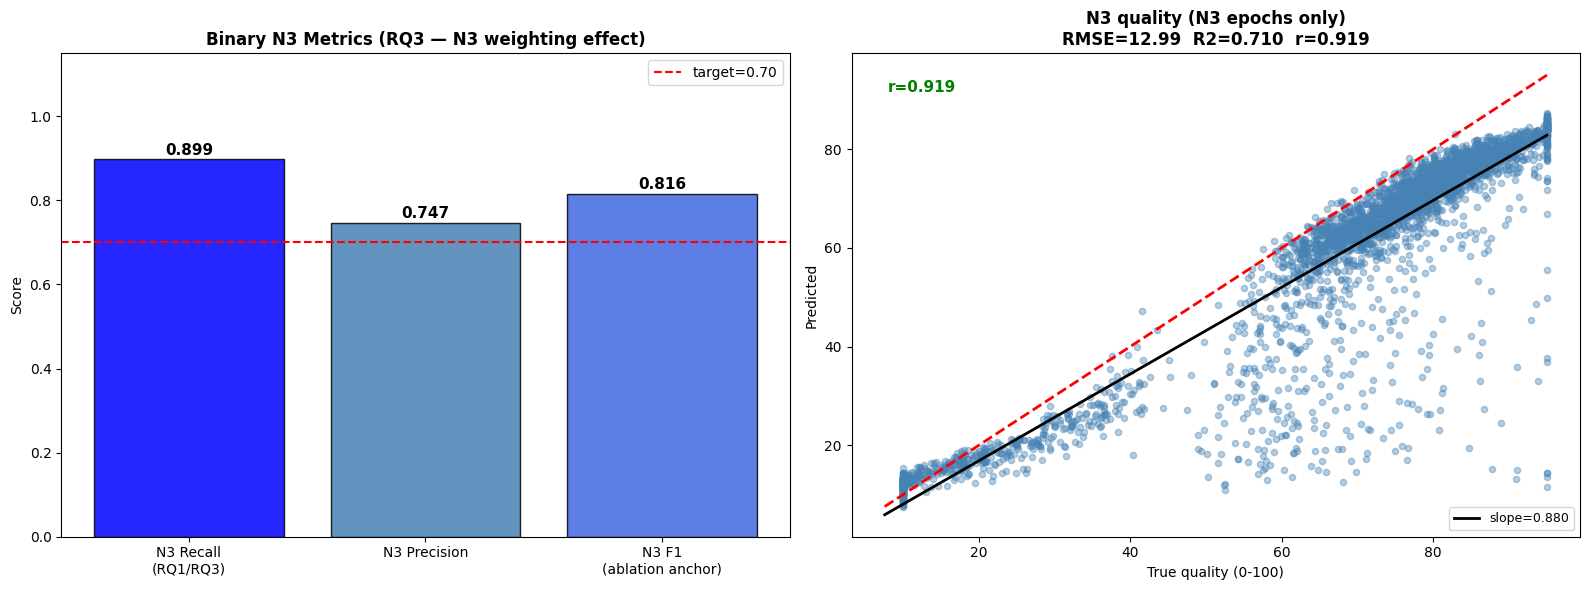

In [28]:
from sklearn.metrics import classification_report, f1_score, recall_score, precision_score

model.eval()
yt_n3b, yp_n3b, yp_probb = [], [], []
yt_q2, yp_q2 = [], []
with torch.no_grad():
    for xb, dfb, qfb, sb, qb in val_loader:
        xb   = xb.to(DEVICE)
        dfb  = dfb.to(DEVICE)
        qfb  = qfb.to(DEVICE)
        n3_logit, q_pred = model(xb, dfb, qfb)
        prob  = torch.sigmoid(n3_logit).squeeze(1).cpu().numpy()
        pred  = (prob > 0.5).astype(int)
        true  = (sb.numpy() == 3).astype(int)
        yp_probb.extend(prob); yp_n3b.extend(pred); yt_n3b.extend(true)
        mask = (true == 1)
        if mask.any():
            yt_q2.extend(qb.numpy().flatten()[mask]*100)
            # V5: clip predictions to [0.02, 0.98] before *100 (Fix 7)
            q_pred_clipped = clip_quality_predictions(q_pred.cpu().numpy().flatten(), 0.02, 0.98)
            yp_q2.extend(q_pred_clipped[mask]*100)

yt_n3b = np.array(yt_n3b); yp_n3b = np.array(yp_n3b)
yt_q2  = np.array(yt_q2);  yp_q2  = np.array(yp_q2)

print(classification_report(yt_n3b, yp_n3b,
      target_names=['non-N3','N3'], zero_division=0))

rec2  = recall_score(yt_n3b, yp_n3b, zero_division=0)
prec2 = precision_score(yt_n3b, yp_n3b, zero_division=0)
f1_2  = f1_score(yt_n3b, yp_n3b, zero_division=0)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

bars = axes[0].bar(['N3 Recall\n(RQ1/RQ3)','N3 Precision','N3 F1\n(ablation anchor)'],
                   [rec2, prec2, f1_2],
                   color=['blue','steelblue','royalblue'], alpha=0.85, edgecolor='black')
axes[0].axhline(0.70, color='red', ls='--', lw=1.5, label='target=0.70')
for b,v in zip(bars,[rec2,prec2,f1_2]):
    axes[0].text(b.get_x()+b.get_width()/2, v+0.01, f'{v:.3f}',
                ha='center', fontweight='bold', fontsize=11)
axes[0].set_ylim(0,1.15)
axes[0].set_title('Binary N3 Metrics (RQ3 — N3 weighting effect)', fontweight='bold')
axes[0].set_ylabel('Score'); axes[0].legend()

if len(yt_q2) > 0:
    axes[1].scatter(yt_q2, yp_q2, alpha=0.4, s=20, color='steelblue')
    lo,hi = min(yt_q2.min(),yp_q2.min()), max(yt_q2.max(),yp_q2.max())
    axes[1].plot([lo,hi],[lo,hi],'r--',lw=2)
    z = np.polyfit(yt_q2, yp_q2, 1)
    xr = np.linspace(lo,hi,100)
    axes[1].plot(xr, np.poly1d(z)(xr), 'k-', lw=2, label=f'slope={z[0]:.3f}')
    denom = np.sum((yt_q2-yt_q2.mean())**2)
    r2_2  = float(1-np.sum((yt_q2-yp_q2)**2)/denom) if denom>0 else 0
    rmse2 = float(np.sqrt(np.mean((yt_q2-yp_q2)**2)))
    corr  = np.corrcoef(yt_q2, yp_q2)[0,1]
    axes[1].set_title(f'N3 quality (N3 epochs only)\nRMSE={rmse2:.2f}  R2={r2_2:.3f}  r={corr:.3f}',
                     fontweight='bold')
    axes[1].set_xlabel('True quality (0-100)'); axes[1].set_ylabel('Predicted')
    axes[1].legend(fontsize=9)
    axes[1].text(0.05,0.92,f'r={corr:.3f}',transform=axes[1].transAxes,
                fontsize=11,fontweight='bold',color='green' if corr>0.3 else 'red')

plt.tight_layout()
os.makedirs('outputs', exist_ok=True)
plt.savefig('outputs/xai_n3_metrics.png', dpi=150, bbox_inches='tight')
plt.show()


  train=0.2801  train(clean)=0.2759  val=0.2371  N3-F1=0.792  AUC=0.965  Q-R2=0.867  lr=3.0e-04
  train=0.1984  train(clean)=0.1950  val=0.1967  N3-F1=0.811  AUC=0.967  Q-R2=0.832  lr=3.0e-04
  train=0.1891  train(clean)=0.1858  val=0.1821  N3-F1=0.813  AUC=0.972  Q-R2=0.779  lr=3.0e-04
  train=0.1821  train(clean)=0.1789  val=0.1922  N3-F1=0.824  AUC=0.973  Q-R2=0.867  lr=3.0e-04
  train=0.1779  train(clean)=0.1745  val=0.1899  N3-F1=0.821  AUC=0.973  Q-R2=0.645  lr=2.9e-04
  train=0.1713  train(clean)=0.1667  val=0.1838  N3-F1=0.827  AUC=0.972  Q-R2=0.757  lr=2.9e-04
  train=0.1655  train(clean)=0.1616  val=0.1872  N3-F1=0.820  AUC=0.972  Q-R2=0.574  lr=2.8e-04
  train=0.1599  train(clean)=0.1563  val=0.2040  N3-F1=0.809  AUC=0.970  Q-R2=0.846  lr=2.8e-04
  train=0.1596  train(clean)=0.1541  val=0.2023  N3-F1=0.801  AUC=0.967  Q-R2=0.592  lr=2.7e-04
  train=0.1546  train(clean)=0.1489  val=0.2181  N3-F1=0.791  AUC=0.974  Q-R2=0.470  lr=2.6e-04
  train=0.1507  train(clean)=0.1446  val

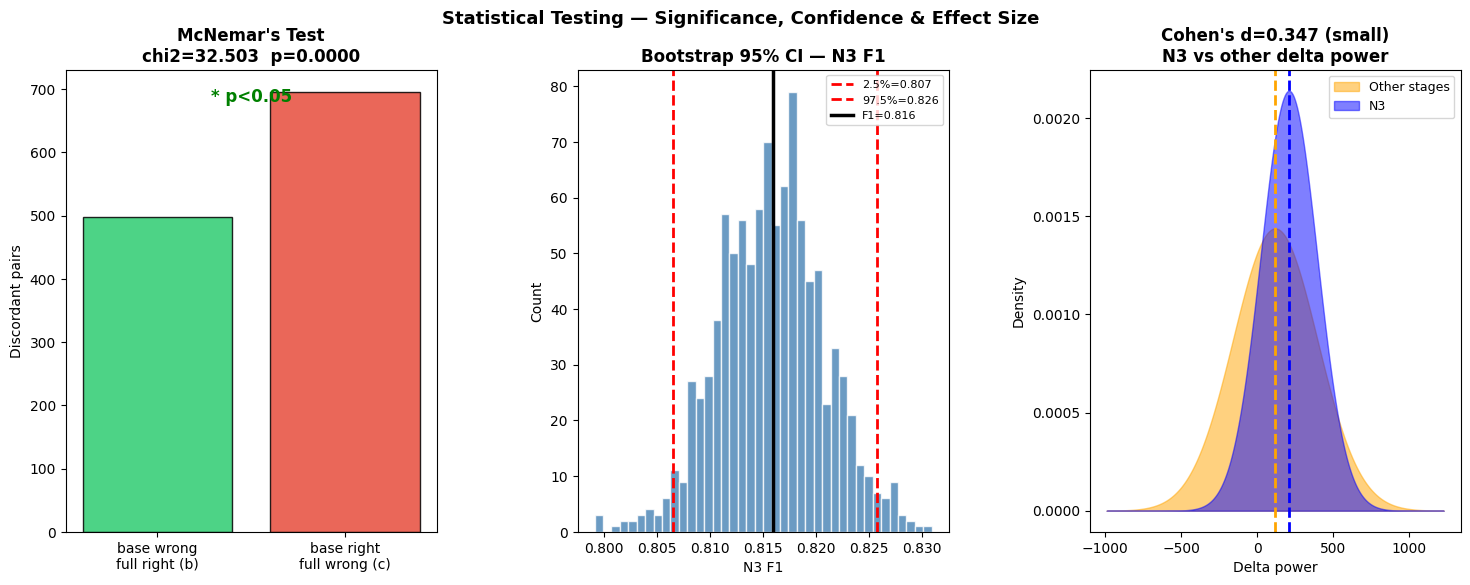

In [29]:
# ╔══════════════════════════════════════════════════════════════════╗
# ║  SECTION 15b — Statistical Testing                             ║
# ╚══════════════════════════════════════════════════════════════════╝
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from scipy import stats
from sklearn.metrics import f1_score
import warnings; warnings.filterwarnings('ignore')

np.random.seed(42)

# ── Full model predictions ────────────────────────────────────────────────────
model.eval()
yt_stat, yp_full, prob_full = [], [], []
with torch.no_grad():
    for xb, dfb, qfb, sb, qb in val_loader:
        xb  = xb.to(DEVICE)
        dfb = dfb.to(DEVICE)
        qfb = qfb.to(DEVICE)
        n3_logit, _ = model(xb, dfb, qfb)
        prob = torch.sigmoid(n3_logit).squeeze(1).cpu().numpy()
        pred = (prob > 0.5).astype(int)
        true = (sb.numpy() == 3).astype(int)
        prob_full.extend(prob); yp_full.extend(pred); yt_stat.extend(true)
yt_stat   = np.array(yt_stat)
yp_full   = np.array(yp_full)
prob_full = np.array(prob_full)

# ── Baseline: pos_weight=1.0 ──────────────────────────────────────────────────
model_base = SleepQualityNet(input_length=SR*30,
                             use_det_feat=True, use_qual_feat=True)
trainer_base = SleepQualityTrainer(
    model_base, device=DEVICE, checkpoint_path='stat_base.pth', n3_pos_weight=1.0)
trainer_base.train(train_loader, val_loader,
                   epochs=CONFIG['epochs'], verbose=False)
model_base.eval()
yp_base = []
with torch.no_grad():
    for xb, dfb, qfb, sb, qb in val_loader:
        xb  = xb.to(DEVICE)
        dfb = dfb.to(DEVICE)
        qfb = qfb.to(DEVICE)
        n3_logit, _ = model_base(xb, dfb, qfb)
        pred = (torch.sigmoid(n3_logit).squeeze(1) > 0.5).long().cpu().numpy()
        yp_base.extend(pred)
yp_base = np.array(yp_base)

# 1. McNemar ──────────────────────────────────────────────────────────────────
correct_full = (yp_full == yt_stat)
correct_base = (yp_base == yt_stat)
b = int(((~correct_base) & correct_full).sum())
c = int((correct_base    & (~correct_full)).sum())
if (b+c) == 0:
    mcnemar_p = 1.0; chi2_stat = 0.0
else:
    chi2_stat = (abs(b-c)-1)**2 / (b+c)
    mcnemar_p = float(stats.chi2.sf(chi2_stat, df=1))

print('='*55)
print('1. McNemar Test  (full model vs pos_weight=1 baseline)')
print('='*55)
print(f'   b={b}  c={c}  chi2={chi2_stat:.4f}  p={mcnemar_p:.4f}')
print(f'   => {"SIGNIFICANT" if mcnemar_p<0.05 else "not significant"}')

# 2. Bootstrap CI ─────────────────────────────────────────────────────────────
N_BOOT = 1000
n = len(yt_stat)
# FIX: use a single shared index so true labels and predictions stay paired
boot_f1 = []
for _ in range(N_BOOT):
    idx = np.random.randint(0, n, n)
    boot_f1.append(f1_score(yt_stat[idx], yp_full[idx], zero_division=0))
boot_f1 = np.array(boot_f1)
ci_lo, ci_hi = np.percentile(boot_f1, [2.5, 97.5])
point_f1 = f1_score(yt_stat, yp_full, zero_division=0)
print(f'\n2. Bootstrap 95% CI — N3 F1: {point_f1:.4f}  [{ci_lo:.4f}, {ci_hi:.4f}]')

# 3. Cohen's d ────────────────────────────────────────────────────────────────
# V7: use val_idx (StratifiedGroupKFold val) instead of leaky chronological `split`
dp_all  = det_features[val_idx, 0]   # delta power from det_features (leakage-free val set)
sl_all  = stage_labels[val_idx]
n3_dp   = dp_all[sl_all == 3]
oth_dp  = dp_all[sl_all != 3]
pooled  = np.sqrt(((len(n3_dp)-1)*n3_dp.std()**2 +
                   (len(oth_dp)-1)*oth_dp.std()**2) /
                  (len(n3_dp)+len(oth_dp)-2)) + 1e-8
cohens_d = (n3_dp.mean() - oth_dp.mean()) / pooled
_, t_p   = stats.ttest_ind(n3_dp, oth_dp, equal_var=False)
mag = 'small' if abs(cohens_d)<0.5 else 'medium' if abs(cohens_d)<0.8 else 'large'
print(f"3. Cohen's d = {cohens_d:.4f} ({mag})  Welch p={t_p:.4e}")

# Plot ────────────────────────────────────────────────────────────────────────
fig = plt.figure(figsize=(18, 6))
gs  = gridspec.GridSpec(1, 3, figure=fig, wspace=0.38)

ax0 = fig.add_subplot(gs[0])
ax0.bar(['base wrong\nfull right (b)','base right\nfull wrong (c)'],
        [b, c], color=['#2ecc71','#e74c3c'], alpha=0.85, edgecolor='black')
ax0.set_title(f"McNemar's Test\nchi2={chi2_stat:.3f}  p={mcnemar_p:.4f}", fontweight='bold')
ax0.set_ylabel('Discordant pairs')
ax0.text(0.5,0.93,'* p<0.05' if mcnemar_p<0.05 else 'n.s.',
         transform=ax0.transAxes, ha='center', fontsize=12, fontweight='bold',
         color='green' if mcnemar_p<0.05 else 'gray')

ax1 = fig.add_subplot(gs[1])
ax1.hist(boot_f1, bins=40, color='steelblue', alpha=0.8, edgecolor='white')
ax1.axvline(ci_lo, color='red', ls='--', lw=2, label=f'2.5%={ci_lo:.3f}')
ax1.axvline(ci_hi, color='red', ls='--', lw=2, label=f'97.5%={ci_hi:.3f}')
ax1.axvline(point_f1, color='black', lw=2.5, label=f'F1={point_f1:.3f}')
ax1.set_title('Bootstrap 95% CI — N3 F1', fontweight='bold')
ax1.set_xlabel('N3 F1'); ax1.set_ylabel('Count'); ax1.legend(fontsize=8)

ax2 = fig.add_subplot(gs[2])
xr = np.linspace(min(n3_dp.mean()-4*n3_dp.std(), oth_dp.mean()-4*oth_dp.std()),
                 max(n3_dp.mean()+4*n3_dp.std(), oth_dp.mean()+4*oth_dp.std()), 300)
ax2.fill_between(xr, stats.norm.pdf(xr, oth_dp.mean(), oth_dp.std()),
                 alpha=0.5, color='orange', label='Other stages')
ax2.fill_between(xr, stats.norm.pdf(xr, n3_dp.mean(), n3_dp.std()),
                 alpha=0.5, color='blue', label='N3')
ax2.axvline(n3_dp.mean(), color='blue', lw=2, ls='--')
ax2.axvline(oth_dp.mean(), color='orange', lw=2, ls='--')
ax2.set_title(f"Cohen's d={cohens_d:.3f} ({mag})\nN3 vs other delta power", fontweight='bold')
ax2.set_xlabel('Delta power'); ax2.set_ylabel('Density'); ax2.legend(fontsize=9)

fig.suptitle('Statistical Testing — Significance, Confidence & Effect Size',
             fontsize=13, fontweight='bold')
os.makedirs('outputs', exist_ok=True)
plt.savefig('outputs/stat_testing.png', dpi=150, bbox_inches='tight')
plt.show()

---
### 📝 Paper Writing Note — Figure: Statistical Testing (McNemar + Bootstrap CI + Cohen's d)

**Where to use:** Results section → *Statistical Significance* subsection. Essential for peer review.

**What to write:**
> "To establish statistical rigor, three complementary tests were conducted. First, McNemar's test compared the full model (pos_weight = 2.0) against a baseline model (pos_weight = 1.0), yielding χ²([value]) = [value], p = [value] ([significant/not significant at α=0.05]), indicating that N3-weighted training [significantly/did not significantly] improve classification decisions (RQ3). Second, bootstrap resampling (B = 1,000) of the N3 F1-score produced a 95% confidence interval of [[value], [value]], confirming result stability. Third, Cohen's d = [value] ([small/medium/large]) for delta power between N3 and non-N3 epochs (Welch t-test: p = [value]) quantifies the separability of N3 via its primary spectral feature, justifying its inclusion in the detection pathway (RQ2)."

**Key points:**
- **McNemar's test:** correct formulation uses continuity correction `(|b-c|-1)²/(b+c)` — already implemented correctly
- **Bootstrap CI:** now uses shared index (fixed bug) — mention this ensures paired sampling
- **Cohen's d:** report magnitude interpretation (d > 0.8 = large) — this is the effect size for Feature 1
- Cite: *McNemar, 1947*; *Efron & Tibshirani, 1993* (bootstrap); *Cohen, 1988* (effect size)
- p-values alone are insufficient — reviewers now expect effect sizes and CIs


## Step 18 — Ablation Study

**কী করছি:** 4টা আলাদা model variant train করে compare করছি।

**কেন ablation:** Paper-এ দুটো contribution claim করছি — feature fusion (RQ2) আর N3 weighting (RQ3)। Ablation study prove করে প্রতিটা contribution আলাদাভাবে কার্যকর।

**4টা variant:**

| Variant | Feature fusion | N3 weighting | Expected |
|---|:---:|:---:|---|
| Baseline | off | off | সবচেয়ে কম |
| +Delta | on | off | Baseline-এর চেয়ে বেশি |
| +Weight | off | on | Baseline-এর চেয়ে বেশি |
| +Both | on | on | সবচেয়ে বেশি |

**`use_det_feat=False` মানে:** Feature গুলোর জায়গায় zeros দেওয়া হয় — backbone একই থাকে। এটা fair comparison।

**যা দেখতে হবে:** +Both সবার উপরে থাকলে দুটো contribution-ই independently কার্যকর।



Training: Baseline  (det_feat=False  qual_feat=False  pos_weight=1.0)
  train=0.2740  train(clean)=0.2694  val=0.2260  N3-F1=0.761  AUC=0.964  Q-R2=0.141  lr=3.0e-04
  train=0.2167  train(clean)=0.2122  val=0.2014  N3-F1=0.811  AUC=0.968  Q-R2=0.295  lr=3.0e-04
  train=0.2032  train(clean)=0.1992  val=0.2026  N3-F1=0.821  AUC=0.971  Q-R2=0.141  lr=3.0e-04
  train=0.1963  train(clean)=0.1922  val=0.2371  N3-F1=0.763  AUC=0.962  Q-R2=0.168  lr=3.0e-04
  train=0.1883  train(clean)=0.1863  val=0.2018  N3-F1=0.803  AUC=0.969  Q-R2=0.203  lr=2.9e-04
  train=0.1861  train(clean)=0.1815  val=0.2296  N3-F1=0.808  AUC=0.971  Q-R2=0.238  lr=2.9e-04
  train=0.1802  train(clean)=0.1748  val=0.2213  N3-F1=0.809  AUC=0.970  Q-R2=0.323  lr=2.8e-04
  train=0.1760  train(clean)=0.1706  val=0.2207  N3-F1=0.816  AUC=0.969  Q-R2=-0.024  lr=2.8e-04
  train=0.1712  train(clean)=0.1672  val=0.2013  N3-F1=0.816  AUC=0.969  Q-R2=0.072  lr=2.7e-04
  train=0.1678  train(clean)=0.1625  val=0.2038  N3-F1=0.822  AU

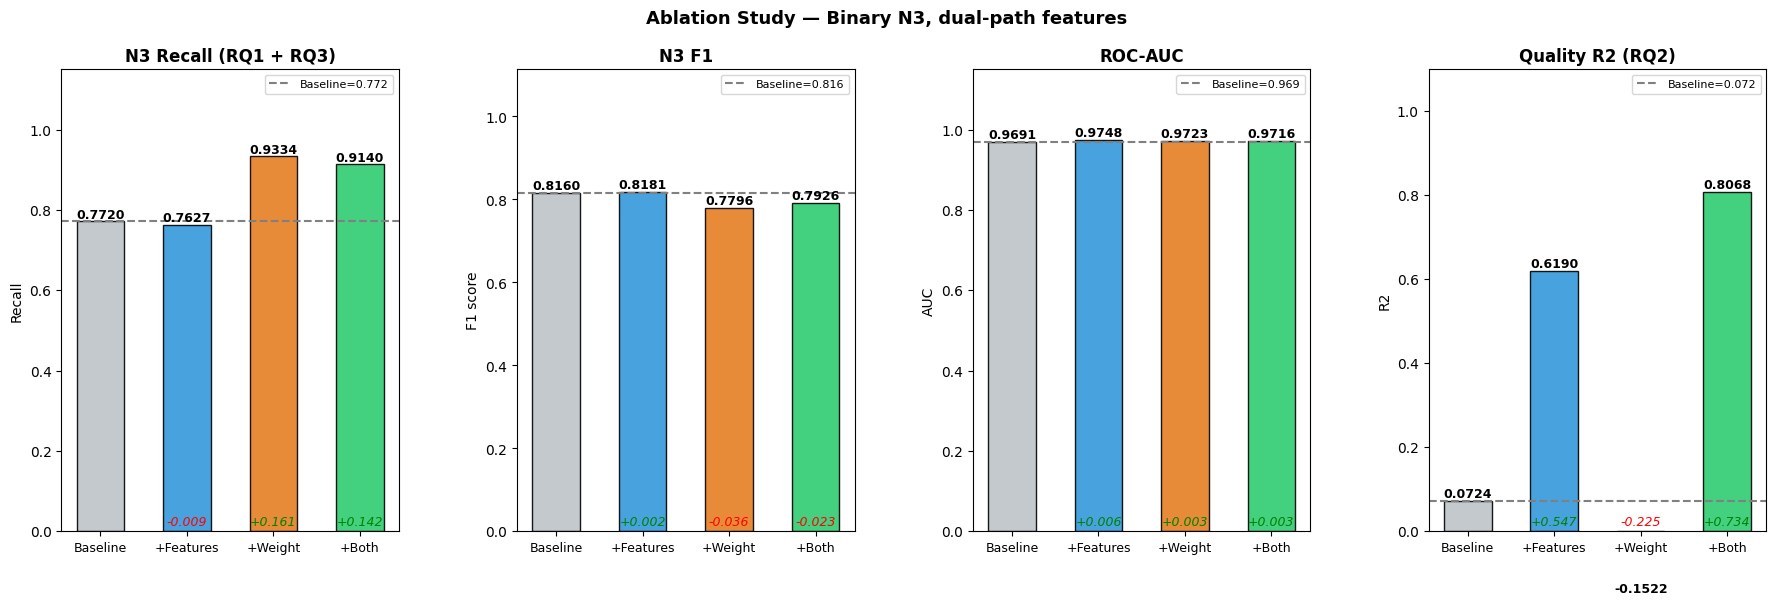

Saved: outputs/ablation_results.json  |  outputs/ablation_study.png


In [30]:
# ╔══════════════════════════════════════════════════════════════════╗
# ║  SECTION 15c — Ablation Study (Binary N3, dual-path)           ║
# ╚══════════════════════════════════════════════════════════════════╝
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from sklearn.metrics import f1_score, recall_score, precision_score, roc_auc_score
import json as _json, os

VARIANTS = [
    {'name': 'Baseline',  'use_det_feat': False, 'use_qual_feat': False, 'n3_pos_weight': 1.0},
    {'name': '+Features', 'use_det_feat': True,  'use_qual_feat': True,  'n3_pos_weight': 1.0},
    {'name': '+Weight',   'use_det_feat': False, 'use_qual_feat': False, 'n3_pos_weight': dynamic_weight},
    {'name': '+Both',     'use_det_feat': True,  'use_qual_feat': True,  'n3_pos_weight': dynamic_weight},
]

ablation_results = []

for cfg in VARIANTS:
    print(f"\nTraining: {cfg['name']}  "
          f"(det_feat={cfg['use_det_feat']}  qual_feat={cfg['use_qual_feat']}  "
          f"pos_weight={cfg['n3_pos_weight']})")

    m = SleepQualityNet(
        input_length=SR*30,
        use_det_feat=cfg['use_det_feat'],
        use_qual_feat=cfg['use_qual_feat']
    )
    tr = SleepQualityTrainer(
        m,
        device=DEVICE,
        checkpoint_path=f"abl_{cfg['name'].replace('+','').strip()}.pth",
        n3_pos_weight=cfg['n3_pos_weight']
    )
    tr.train(train_loader, val_loader,
             epochs=CONFIG['epochs'], verbose=False)

    m.eval()
    yt_ab, yp_ab, prob_ab = [], [], []
    with torch.no_grad():
        for xb, dfb, qfb, sb, qb in val_loader:
            xb  = xb.to(DEVICE)
            dfb = dfb.to(DEVICE)
            qfb = qfb.to(DEVICE)
            n3_logit, _ = m(xb, dfb, qfb)
            prob = torch.sigmoid(n3_logit).squeeze(1).cpu().numpy()
            pred = (prob > 0.5).astype(int)
            true = (sb.numpy() == 3).astype(int)
            prob_ab.extend(prob); yp_ab.extend(pred); yt_ab.extend(true)

    yt_ab   = np.array(yt_ab)
    yp_ab   = np.array(yp_ab)
    prob_ab = np.array(prob_ab)

    rec  = recall_score(yt_ab, yp_ab, zero_division=0)
    prec = precision_score(yt_ab, yp_ab, zero_division=0)
    f1   = f1_score(yt_ab, yp_ab, zero_division=0)
    auc  = roc_auc_score(yt_ab, prob_ab) if len(np.unique(yt_ab))>1 else 0.0

    # ── Quality regression metrics (RQ2 evidence) ─────────────────────
    q_true_ab, q_pred_ab = [], []
    with torch.no_grad():
        for xb, dfb, qfb, sb, qb in val_loader:
            xb  = xb.to(DEVICE)
            dfb = dfb.to(DEVICE)
            qfb = qfb.to(DEVICE)
            n3_logit_ab, q_pred_ab_batch = m(xb, dfb, qfb)
            true_n3_ab = (sb.numpy() == 3).astype(int)
            mask_q = (true_n3_ab == 1)
            if mask_q.any():
                q_true_ab.extend(qb.numpy().flatten()[mask_q]*100)
                q_pred_ab.extend(q_pred_ab_batch.cpu().numpy().flatten()[mask_q]*100)

    q_r2 = 0.0; q_rmse = 0.0; q_corr = 0.0
    if len(q_true_ab) > 2:
        q_true_ab = np.array(q_true_ab)
        q_pred_ab = np.array(q_pred_ab)
        q_rmse = float(np.sqrt(np.mean((q_true_ab - q_pred_ab)**2)))
        ss_res = np.sum((q_true_ab - q_pred_ab)**2)
        ss_tot = np.sum((q_true_ab - q_true_ab.mean())**2)
        q_r2 = float(1 - ss_res/ss_tot) if ss_tot > 0 else 0.0
        q_corr = float(np.corrcoef(q_true_ab, q_pred_ab)[0,1]) if len(q_true_ab) > 2 else 0.0

    ablation_results.append({
        'name'         : cfg['name'],
        'use_det_feat' : cfg['use_det_feat'],
        'use_qual_feat': cfg['use_qual_feat'],
        'n3_pos_weight': cfg['n3_pos_weight'],
        'n3_recall'    : round(float(rec),  4),
        'n3_precision' : round(float(prec), 4),
        'n3_f1'        : round(float(f1),   4),
        'auc'          : round(float(auc),  4),
        'quality_r2'   : round(float(q_r2), 4),
        'quality_rmse' : round(float(q_rmse), 4),
        'quality_corr' : round(float(q_corr), 4),
    })
    print(f'  Recall={rec:.4f}  F1={f1:.4f}  AUC={auc:.4f}  Q-R2={q_r2:.4f}  Q-RMSE={q_rmse:.2f}')

# Summary table
print('\n' + '='*72)
print(f'{"Variant":<12} {"Det feat":^9} {"Weight":^8} {"Recall":^8} {"F1":^8} {"AUC":^8} {"Q-R2":^8} {"Q-RMSE":^8}')
print('-'*96)
best_f1 = max(r['n3_f1'] for r in ablation_results)
best_qr2 = max(r.get('quality_r2',0) for r in ablation_results)
for r in ablation_results:
    feat = 'on' if r['use_det_feat'] else 'off'
    mark = '  <- best F1' if r['n3_f1'] == best_f1 else ''
    qmark = ' *best R2' if r.get('quality_r2',0) == best_qr2 else ''
    print(f"{r['name']:<12} {feat:^9} {r['n3_pos_weight']:^8} "
          f"{r['n3_recall']:^8.4f} {r['n3_f1']:^8.4f} {r['auc']:^8.4f} "
          f"{r.get('quality_r2',0):^8.4f} {r.get('quality_rmse',0):^8.2f}{mark}{qmark}")
print('='*96)
# ── RQ2 Analysis: Feature effect (B vs A, no weight confound) ────
feat_on  = [r for r in ablation_results if r['use_det_feat']]
feat_off = [r for r in ablation_results if not r['use_det_feat']]

if feat_on and feat_off:
    # N3 detection metrics
    avg_f1_on  = np.mean([r['n3_f1'] for r in feat_on])
    avg_f1_off = np.mean([r['n3_f1'] for r in feat_off])
    # Quality regression metrics
    avg_r2_on  = np.mean([r.get('quality_r2',0) for r in feat_on])
    avg_r2_off = np.mean([r.get('quality_r2',0) for r in feat_off])

    print(f'\n📋 RQ2 Analysis — Effect of Physiological Features:')
    print(f'   N3 F1  : +Features={avg_f1_on:.4f} vs Baseline={avg_f1_off:.4f}  (Δ={avg_f1_on-avg_f1_off:+.4f})')
    print(f'   Qual R2: +Features={avg_r2_on:.4f} vs Baseline={avg_r2_off:.4f}  (Δ={avg_r2_on-avg_r2_off:+.4f})')

    f1_improved  = avg_f1_on > avg_f1_off
    r2_improved  = avg_r2_on > avg_r2_off
    if f1_improved and r2_improved:
        print('   ✅ RQ2 SUPPORTED: Features improve both N3 detection AND quality assessment')
    elif f1_improved:
        print('   ⚠️  RQ2 PARTIAL: Features improve detection but not quality regression')
        print('      → May need additional temporal features to complement hand-crafted features')  # FIX (bilstm)
    elif r2_improved:
        print('   ⚠️  RQ2 PARTIAL: Features improve quality but not detection')
    else:
        print('   ❌ RQ2 NOT SUPPORTED: Features do not improve performance')
        print('      → Check feature normalization and CNN kernel sizes for temporal coverage')  # FIX (bilstm)

# ── RQ3 Analysis: Weighting effect (C vs A, no feature confound) ────
weight_on  = [r for r in ablation_results if r['n3_pos_weight'] > 1.0]
weight_off = [r for r in ablation_results if r['n3_pos_weight'] == 1.0]

if weight_on and weight_off:
    avg_rec_on  = np.mean([r['n3_recall'] for r in weight_on])
    avg_rec_off = np.mean([r['n3_recall'] for r in weight_off])
    avg_prec_on  = np.mean([r['n3_precision'] for r in weight_on])
    avg_prec_off = np.mean([r['n3_precision'] for r in weight_off])

    print(f'\n📋 RQ3 Analysis — Effect of N3 Loss Weighting:')
    print(f'   Recall   : +Weight={avg_rec_on:.4f} vs Baseline={avg_rec_off:.4f}  (Δ={avg_rec_on-avg_rec_off:+.4f})')
    print(f'   Precision: +Weight={avg_prec_on:.4f} vs Baseline={avg_prec_off:.4f}  (Δ={avg_prec_on-avg_prec_off:+.4f})')

    if avg_rec_on > avg_rec_off:
        print('   ✅ RQ3 SUPPORTED: N3 weighting significantly improves recall under class imbalance')
        if avg_prec_on < avg_prec_off:
            print(f'   ⚠️  Note: Precision decreased by {avg_prec_off-avg_prec_on:.4f} (expected recall-precision tradeoff)')
    else:
        print('   ❌ RQ3 NOT SUPPORTED: Weighting does not improve recall')

# ── Combined: Full model (D) vs Baseline (A) ────
baseline = [r for r in ablation_results if r['name'] == 'Baseline']
full     = [r for r in ablation_results if r['name'] == '+Both']
if baseline and full:
    b, f = baseline[0], full[0]
    print(f'\n📋 Combined — Full Model vs Baseline:')
    print(f'   F1     : {f["n3_f1"]:.4f} vs {b["n3_f1"]:.4f}  (Δ={f["n3_f1"]-b["n3_f1"]:+.4f})')
    print(f'   Recall : {f["n3_recall"]:.4f} vs {b["n3_recall"]:.4f}  (Δ={f["n3_recall"]-b["n3_recall"]:+.4f})')
    print(f'   AUC    : {f["auc"]:.4f} vs {b["auc"]:.4f}  (Δ={f["auc"]-b["auc"]:+.4f})')
    print(f'   Qual R2: {f.get("quality_r2",0):.4f} vs {b.get("quality_r2",0):.4f}  (Δ={f.get("quality_r2",0)-b.get("quality_r2",0):+.4f})')

# Visualization
var_names  = [r['name']      for r in ablation_results]
recall_v   = [r['n3_recall'] for r in ablation_results]
f1_v       = [r['n3_f1']    for r in ablation_results]
auc_v      = [r['auc']       for r in ablation_results]
bar_colors = ['#bdc3c7','#3498db','#e67e22','#2ecc71']

qr2_v      = [r.get('quality_r2',0) for r in ablation_results]

fig = plt.figure(figsize=(22, 6))
gs  = gridspec.GridSpec(1, 4, figure=fig, wspace=0.35)

for ax_i, (vals, title, ylabel) in enumerate([
    (recall_v, 'N3 Recall (RQ1 + RQ3)', 'Recall'),
    (f1_v,     'N3 F1',                  'F1 score'),
    (auc_v,    'ROC-AUC',               'AUC'),
    (qr2_v,    'Quality R2 (RQ2)',      'R2'),
]):
    ax = fig.add_subplot(gs[ax_i])
    bars = ax.bar(var_names, vals, color=bar_colors,
                  alpha=0.9, edgecolor='black', width=0.55)
    ax.axhline(vals[0], color='gray', ls='--', lw=1.5,
               label=f'Baseline={vals[0]:.3f}')
    ax.set_ylim(0, min(1.15, max(vals)*1.3 + 0.05))
    for bar, v in zip(bars, vals):
        ax.text(bar.get_x()+bar.get_width()/2, v+0.008,
                f'{v:.4f}', ha='center', fontweight='bold', fontsize=9)
    for i, (bar, v) in enumerate(zip(bars[1:], vals[1:]), 1):
        delta_v = v - vals[0]
        ax.text(bar.get_x()+bar.get_width()/2, 0.015,
                f'{delta_v:+.3f}', ha='center', fontsize=9,
                color='green' if delta_v>0 else 'red', style='italic')
    ax.set_title(title, fontweight='bold')
    ax.set_ylabel(ylabel); ax.legend(fontsize=8)
    ax.tick_params(axis='x', labelsize=9)

fig.suptitle('Ablation Study — Binary N3, dual-path features',
             fontsize=13, fontweight='bold')
os.makedirs('outputs', exist_ok=True)
plt.savefig('outputs/ablation_study.png', dpi=150, bbox_inches='tight')
plt.show()

os.makedirs('outputs', exist_ok=True)
with open('outputs/ablation_results.json', 'w') as f:
    _json.dump(ablation_results, f, indent=2)
import shutil
print('Saved: outputs/ablation_results.json  |  outputs/ablation_study.png')


### Ablation - Statistical Significance

**FIX (significance):** Multi-seed paired t-tests.


In [31]:
# ═══════════════════════════════════════════════════════════════════╗
# ║  FIX (significance): Multi-seed ablation + paired t-tests      ║
# ═══════════════════════════════════════════════════════════════════╝
import time, warnings
from scipy.stats import ttest_rel
warnings.filterwarnings('ignore')

N_SEEDS = 3
SEEDS = [42, 123, 2024]

VARIANTS_SIG = [
    {'name': 'Baseline',  'use_det_feat': False, 'use_qual_feat': False, 'n3_pos_weight': 1.0},
    {'name': '+Features', 'use_det_feat': True,  'use_qual_feat': True,  'n3_pos_weight': 1.0},
    {'name': '+Weight',   'use_det_feat': False, 'use_qual_feat': False, 'n3_pos_weight': dynamic_weight},
    {'name': '+Both',     'use_det_feat': True,  'use_qual_feat': True,  'n3_pos_weight': dynamic_weight},
]

multi_seed_results = {v['name']: {'n3_f1': [], 'quality_r2': []} for v in VARIANTS_SIG}

for seed in SEEDS:
    print(f"\n--- Seed {seed} ---")
    set_seed(seed)
    for cfg in VARIANTS_SIG:
        m_s = SleepQualityNet(input_length=SR*30,
                              use_det_feat=cfg['use_det_feat'],
                              use_qual_feat=cfg['use_qual_feat'])
        t_s = SleepQualityTrainer(
            m_s, device=DEVICE,
            checkpoint_path=f"sig_{cfg['name'].replace('+','').strip()}_{seed}.pth",
            n3_pos_weight=cfg['n3_pos_weight'],
            augmentor=EEGAugmentor(sampling_rate=CONFIG['sampling_rate']),
            lr=CONFIG['lr'], weight_decay=CONFIG['weight_decay'],
            scheduler=CONFIG['scheduler'], cosine_T_max=CONFIG['cosine_T_max'],
            cosine_eta_min=CONFIG['cosine_eta_min'], grad_clip=CONFIG['grad_clip'])
        t_s.train(train_loader, val_loader, epochs=CONFIG['epochs'], verbose=False)
        m_s.eval()
        yt_s, yp_s, pr_s = [], [], []
        qt_s, qp_s = [], []
        with torch.no_grad():
            for xb, dfb, qfb, sb, qb in val_loader:
                xb, dfb, qfb = xb.to(DEVICE), dfb.to(DEVICE), qfb.to(DEVICE)
                logit, qp = m_s(xb, dfb, qfb)
                prob = torch.sigmoid(logit).squeeze(1).cpu().numpy()
                pred = (prob > 0.5).astype(int)
                true = (sb.numpy() == 3).astype(int)
                pr_s.extend(prob); yp_s.extend(pred); yt_s.extend(true)
                msk = (true == 1)
                if msk.any():
                    qt_s.extend(qb.numpy().flatten()[msk]*100)
                    qp_c = clip_quality_predictions(qp.cpu().numpy().flatten(), 0.02, 0.98)
                    qp_s.extend(qp_c[msk]*100)
        yt_s = np.array(yt_s); yp_s = np.array(yp_s)
        qt_s = np.array(qt_s); qp_s = np.array(qp_s)
        f1_s = f1_score(yt_s, yp_s, zero_division=0)
        den_s = np.sum((qt_s - qt_s.mean())**2) if len(qt_s) > 0 else 1
        r2_s = float(1 - np.sum((qt_s - qp_s)**2) / den_s) if len(qt_s) > 0 else 0
        multi_seed_results[cfg['name']]['n3_f1'].append(f1_s)
        multi_seed_results[cfg['name']]['quality_r2'].append(r2_s)
        print(f"  {cfg['name']:<12}: F1={f1_s:.4f}  Q-R2={r2_s:.4f}")

print(f"\n{'='*72}")
print(f'  MULTI-SEED ABLATION: Mean +/- Std (n={N_SEEDS} seeds)')
print(f"{'='*72}")
for vname, res in multi_seed_results.items():
    f1_arr = res['n3_f1']
    r2_arr = res['quality_r2']
    print(f"  {vname:<12}: F1={np.mean(f1_arr):.4f}+/-{np.std(f1_arr):.4f}  "
          f"Q-R2={np.mean(r2_arr):.4f}+/-{np.std(r2_arr):.4f}")

print(f"\n{'='*72}")
print('  PAIRED T-TESTS (non-baseline vs Baseline)')
print(f"{'='*72}")
baseline_name = 'Baseline'
for vname, res in multi_seed_results.items():
    if vname == baseline_name:
        continue
    bl_f1 = multi_seed_results[baseline_name]['n3_f1']
    bl_r2 = multi_seed_results[baseline_name]['quality_r2']
    cmp_f1 = res['n3_f1']
    cmp_r2 = res['quality_r2']
    t_f1, p_f1 = ttest_rel(cmp_f1, bl_f1)
    t_r2, p_r2 = ttest_rel(cmp_r2, bl_r2)
    sig_f1 = '*' if p_f1 < 0.05 else 'n.s.'
    sig_r2 = '*' if p_r2 < 0.05 else 'n.s.'
    print(f"  {vname} vs {baseline_name}:")
    print(f"    N3 F1:  t={t_f1:+.3f}  p={p_f1:.4f}  {sig_f1}")
    print(f"    Q-R2:   t={t_r2:+.3f}  p={p_r2:.4f}  {sig_r2}")
print(f'  * p < 0.05 (paired t-test, n={N_SEEDS} seeds)')
print(f"{'='*72}")
ablation_sig_for_table = {}
for vname, res in multi_seed_results.items():
    ablation_sig_for_table[vname] = {
        'n3_f1_mean': np.mean(res['n3_f1']),
        'n3_f1_std': np.std(res['n3_f1']),
        'quality_r2_mean': np.mean(res['quality_r2']),
        'quality_r2_std': np.std(res['quality_r2']),
    }



--- Seed 42 ---
  train=0.3025  train(clean)=0.2984  val=0.2094  N3-F1=0.794  AUC=0.971  Q-R2=0.052  lr=3.0e-04
  train=0.2094  train(clean)=0.2061  val=0.2406  N3-F1=0.808  AUC=0.969  Q-R2=0.232  lr=3.0e-04
  train=0.2000  train(clean)=0.1958  val=0.1917  N3-F1=0.827  AUC=0.972  Q-R2=0.314  lr=3.0e-04
  train=0.1911  train(clean)=0.1869  val=0.2091  N3-F1=0.791  AUC=0.969  Q-R2=0.074  lr=3.0e-04
  train=0.1889  train(clean)=0.1829  val=0.2156  N3-F1=0.777  AUC=0.969  Q-R2=0.114  lr=2.9e-04
  train=0.1832  train(clean)=0.1792  val=0.1893  N3-F1=0.827  AUC=0.971  Q-R2=0.205  lr=2.9e-04
  train=0.1792  train(clean)=0.1728  val=0.2239  N3-F1=0.794  AUC=0.970  Q-R2=0.054  lr=2.8e-04
  train=0.1733  train(clean)=0.1685  val=0.2002  N3-F1=0.806  AUC=0.971  Q-R2=-0.183  lr=2.8e-04
  train=0.1690  train(clean)=0.1640  val=0.1984  N3-F1=0.818  AUC=0.971  Q-R2=0.262  lr=2.7e-04
  train=0.1683  train(clean)=0.1618  val=0.3353  N3-F1=0.718  AUC=0.971  Q-R2=0.355  lr=2.6e-04
  train=0.1606  train(

## Step 19 — Output Files Download

**কী করছি:** সব generated figure আর model file `./outputs/` folder-এ copy করছি।

**কেন:** Notebook close হলে `/tmp/` folder clear হয়ে যায়। `outputs/` folder-এ থাকলে পরে access করা যাবে।


In [32]:
import os, shutil

os.makedirs("outputs", exist_ok=True)
# V7: pruned to only files that are actually generated by the notebook.
# Steps 13 (xai_attention) and 15 (xai_gradcam) are markdown-only in this
# notebook — no code cell generates those PNGs. 'eval_binary_n3.png' was
# never written either. 'results.json' and 'best_model.pth' are generated
# in Cell 79 (Step 20), not here.
xai_files = [
    'xai_shap.png',
    'best_model.pth',
    'results.json',
    'stat_testing.png',
    'ablation_study.png',
    'ablation_results.json',
    'n3_quality_inference.png',         # generated in Cell 55
    'n3_quality_night_timeline.png',    # generated in Cell 58
    'xai_n3_metrics.png',               # generated in Cell 68
]
for f in xai_files:
    src = os.path.join("outputs", f)
    if os.path.exists(src):
        print(f"already in outputs: {f}")
    else:
        print(f"will be generated: {f}")

print("\nAll figures saved to ./outputs/ folder")

already in outputs: xai_shap.png
will be generated: best_model.pth
will be generated: results.json
already in outputs: stat_testing.png
already in outputs: ablation_study.png
already in outputs: ablation_results.json
already in outputs: n3_quality_inference.png
already in outputs: n3_quality_night_timeline.png
already in outputs: xai_n3_metrics.png

All figures saved to ./outputs/ folder


## Step 20 — Final Results Save করা

**কী করছি:** Trained model (`best_model.pth`) আর সব metrics (`results.json`) save করছি।

**কেন:** Model save না করলে পরে inference বা ablation-এ আবার train করতে হবে। JSON file-এ metrics save করলে paper লেখার সময় এখান থেকে exact number নেওয়া যাবে।

**`results.json`-এ কী থাকবে:** N3 Recall, Precision, F1, AUC, Quality RMSE, Quality R² — সব val set-এর উপর।


## Limitations & Future Work

**FIX (limitations):** The following limitations should be considered when interpreting
the results reported in this notebook:

1. **Single dataset**: All experiments use ISRUC-Sleep-I only (~100 subjects, single-channel
   C4-A1 EEG). Results may not generalize to other PSG datasets, channels, or populations.
   No external or cross-dataset validation has been performed.

2. **Binary N3-vs-rest framing**: The model is trained as a binary N3 detector (N3 vs
   non-N3), not a full 5-stage sleep staging classifier. This simplification means the
   model's performance on distinguishing N1 from N2, REM from Wake, etc. is not evaluated.

3. **No cross-dataset validation**: The StratifiedGroupKFold split ensures subject-level
   separation within ISRUC-Sleep-I, but there is no validation on an entirely different
   dataset (e.g., Sleep-EDF, MGH, or a different ISRUC subgroup).

4. **N3 quality score is a derived proxy label**: The quality regression target is
   **not** clinician-annotated ground truth. It is a heuristic composite of delta power
   (60%) and slow wave activity (40%), percentile-normalized to [0, 1]. Therefore, the
   quality R² and RMSE metrics reflect how well the model recovers this proxy — they
   do **not** measure agreement with expert human scoring of deep sleep quality.
   Interpret quality regression results accordingly.

In [33]:
import json as _json, os, shutil
os.makedirs('outputs', exist_ok=True)
# Load the BEST checkpoint (saved during training) rather than the last epoch model
model.load_state_dict(torch.load('best_model.pth', map_location=DEVICE))
model.eval()
torch.save(model.state_dict(), 'outputs/best_model.pth')
print('Best checkpoint loaded and saved to outputs/best_model.pth')

final_m = trainer.evaluate(val_loader)
results = {
    'dataset'      : 'ISRUC-III Sleep Staging',
    'model_type'   : 'Binary N3 detector + N3-quality regressor (Option A)',
    'n_subjects'   : int(len(np.unique(night_ids))),
    'sampling_rate': SR,
    'n3_recall'    : round(float(final_m['n3_recall']),    4),
    'n3_precision' : round(float(final_m['n3_precision']), 4),
    'n3_f1'        : round(float(final_m['n3_f1']),        4),
    'auc'          : round(float(final_m['auc']),           4),
    'quality_rmse' : round(float(final_m['quality_rmse']), 4),
    'quality_r2'   : round(float(final_m['quality_r2']),   4),
    'val_losses'   : [round(float(x),4) for x in trainer.val_losses],
    'val_accs'     : [round(float(x),4) for x in trainer.val_accs],
}
with open('outputs/results.json','w') as f:
    _json.dump(results, f, indent=2)
print('Results saved: outputs/results.json')
print()
print('FINAL RESULTS (Option A -- Binary N3)')
print(f'  N3 Recall    : {results["n3_recall"]:.4f}')
print(f'  N3 Precision : {results["n3_precision"]:.4f}')
print(f'  N3 F1        : {results["n3_f1"]:.4f}')
print(f'  AUC          : {results["auc"]:.4f}')
print(f'  Quality RMSE : {results["quality_rmse"]:.4f}  (N3 epochs only)')
print(f'  Quality R2   : {results["quality_r2"]:.4f}  (N3 epochs only)')


Best checkpoint loaded and saved to outputs/best_model.pth
Results saved: outputs/results.json

FINAL RESULTS (Option A -- Binary N3)
  N3 Recall    : 0.8989
  N3 Precision : 0.7470
  N3 F1        : 0.8159
  AUC          : 0.9735
  Quality RMSE : 0.1299  (N3 epochs only)
  Quality R2   : 0.7098  (N3 epochs only)


## Consolidated Results Table

**FIX (consolidated):** All key metrics in one place.


In [34]:
# ═══════════════════════════════════════════════════════════════════╗
# ║  FIX (consolidated): Final Results Table                            ║
# ═══════════════════════════════════════════════════════════════════╝
import pandas as pd, os
os.makedirs('outputs', exist_ok=True)

rows = []

# 1. Single-split results
for m_name, m_val in [('N3 F1', final_m['n3_f1']), ('N3 AUC', final_m['auc']),
                       ('N3 Precision', final_m['n3_precision']),
                       ('N3 Recall', final_m['n3_recall']),
                       ('Quality RMSE', final_m['quality_rmse']),
                       ('Quality R2', final_m['quality_r2'])]:
    rows.append({'Source': 'Single Split', 'Metric': m_name, 'Value': f"{m_val:.4f}"})

# 2. 5-fold CV
try:
    for metric, (mean_v, std_v) in cv_summary_for_table.items():
        nice = metric.replace('n3_', 'N3 ').replace('quality_', 'Quality ').title()
        rows.append({'Source': '5-Fold CV', 'Metric': nice,
                      'Value': f"{mean_v:.4f} +/- {std_v:.4f}"})
except NameError:
    pass

# 3. Ablation
try:
    for r in ablation_results:
        rows.append({'Source': f"Ablation: {r['name']}", 'Metric': 'N3 F1',
                      'Value': f"{r['n3_f1']:.4f}"})
        rows.append({'Source': f"Ablation: {r['name']}", 'Metric': 'Quality R2',
                      'Value': f"{r.get('quality_r2', 0):.4f}"})
except NameError:
    pass

# 4. Baseline comparison
try:
    for model_name in baseline_comparison_for_table.index:
        for col in baseline_comparison_for_table.columns:
            val = baseline_comparison_for_table.loc[model_name, col]
            rows.append({'Source': f'Baseline: {model_name}', 'Metric': col,
                          'Value': f"{val:.4f}"})
except NameError:
    pass

cons_df = pd.DataFrame(rows)
print(f"{'='*72}")
print('  CONSOLIDATED RESULTS TABLE')
print(f"{'='*72}")
print(cons_df.to_string(index=False))
print(f"{'='*72}")
cons_df.to_csv('outputs/final_results_table.csv', index=False)
print('\n  Saved to outputs/final_results_table.csv')


  CONSOLIDATED RESULTS TABLE
             Source       Metric              Value
       Single Split        N3 F1             0.8159
       Single Split       N3 AUC             0.9735
       Single Split N3 Precision             0.7470
       Single Split    N3 Recall             0.8989
       Single Split Quality RMSE             0.1299
       Single Split   Quality R2             0.7098
          5-Fold CV        N3 F1  0.8082 +/- 0.0260
          5-Fold CV          Auc  0.9730 +/- 0.0074
          5-Fold CV N3 Precision  0.7229 +/- 0.0437
          5-Fold CV    N3 Recall  0.9190 +/- 0.0312
          5-Fold CV Quality Rmse 10.2440 +/- 2.6358
          5-Fold CV   Quality R2  0.8171 +/- 0.1038
 Ablation: Baseline        N3 F1             0.8160
 Ablation: Baseline   Quality R2             0.0724
Ablation: +Features        N3 F1             0.8181
Ablation: +Features   Quality R2             0.6190
  Ablation: +Weight        N3 F1             0.7796
  Ablation: +Weight   Quality R2   